# NHS primary care appointments: capacity and utilisation analysis

**Author:** Lan Ngoc Mau  
**Tools:** Python (pandas, NumPy, Matplotlib, Seaborn, TextBlob)

**Business question:** does the NHS need more staff and capacity, or can it make better use of what it has? This notebook explores GP appointment data (August 2021 to June 2022), finds monthly and seasonal patterns, investigates outlier ICBs, analyses healthcare-related tweets, and compares utilisation against the NHS planning benchmark of 1.2 million appointments per day.

**Data files** (not included in this repository; place them next to the notebook): `actual_duration.csv`, `appointments_regional.csv`, `national_categories.xlsx`, `tweets.csv`, `gp-reg-pat-prac-all.csv` (NHS Digital registered patients by practice).

# 1. Planning the approach

##### Current Situation
- Refine business questions to actionable analytic question
- NHS need to expand its infrastructure and resources to match with increasing population capacity -> utilisation trends of each component it its network.

##### Contrast opinions about the utilisation of NHS resources
- NHS's capacity is not enough to cope with current situation
- The current trends in utilisation shows no need to put more effort in making better use of existing infrastructure and resources.

##### The missed appointments needs to be scrutinized and the aim to reducing or eliminating them
- Has there been adequate staff and capacity in the networks?

- What was the actual utilisation of resources?

#### Questions to guide initial thoughts

- The population is increasing -> more people in need of NHS services -> however why more missed appointments -> doesnt fully reflect the whole situation.
- Numbers and appointments and records per month?
- Reasons for cancelling appointments: got an appointment way too far from their expected date -> no use to see doctor because they might already recover until the appointment?
- How many locations are there?
- 5 locations with highest number of appointments?
- How many service settings, context types, national categories, number of appointments?

##### Lead time between calling and getting an appointment: lead time for each category of symptoms
##### What symptoms that people tend to skip appointments/ any similar patterns/group?
- Any others reasons that might contribute to this: number of locations/ monthly and seasonal trends based on number of appointments for service settings, context types, national categories?
- What can be learnt from interpreting opinions from Twitter? Do they all tell us the same thing? Do customers provide their reason behind missed appointments?
- What can top trending hashtag on twitter tell about? will it help the decision making process?
- Patterns in people tend to have more appointments than others? Will they cancel more than others
- Patterns in people tend to not show up? Were it symptoms/illness categories related or any other factors?
- Conversion rate between "Booked" to "Attended/Unknown/DNA": any patterns? 

#### -> Try to gain more insights by looking at patterns

#### Recommendations:
- How to utilise staff when patients missed appointments? What would nurses/doctors do in case their patients do not show up? Is there anything they can work on?

# 2. Data import, cleaning and first exploration

In [1]:
# Import the necessary libraries.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Optional - Ignore warnings.
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Import and sense-check the actual_duration.csv data set as ad.
ad = pd.read_csv('actual_duration.csv')

# View the DataFrame.
ad

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments
0,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,31-60 Minutes,364
1,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,21-30 Minutes,619
2,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,6-10 Minutes,1698
3,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,Unknown / Data Quality,1277
4,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,01-Dec-21,16-20 Minutes,730
...,...,...,...,...,...,...,...,...
137788,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,31-60 Minutes,430
137789,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,21-30 Minutes,751
137790,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,16-20 Minutes,921
137791,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,30-Jun-22,11-15 Minutes,1439


In [3]:
# Determine whether there are missing values.
ad_na = ad[ad.isna().any(axis=1)]

ad_na

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments


In [4]:
# Confirm whether no missing values

ad.isna().sum()

sub_icb_location_code        0
sub_icb_location_ons_code    0
sub_icb_location_name        0
icb_ons_code                 0
region_ons_code              0
appointment_date             0
actual_duration              0
count_of_appointments        0
dtype: int64

In [5]:
# Determine the metadata of the data set.
type(ad)

pandas.core.frame.DataFrame

In [6]:
# Describe the dataset
ad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137793 entries, 0 to 137792
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   sub_icb_location_code      137793 non-null  object
 1   sub_icb_location_ons_code  137793 non-null  object
 2   sub_icb_location_name      137793 non-null  object
 3   icb_ons_code               137793 non-null  object
 4   region_ons_code            137793 non-null  object
 5   appointment_date           137793 non-null  object
 6   actual_duration            137793 non-null  object
 7   count_of_appointments      137793 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 8.4+ MB


In [7]:
# Change the datatype of appointment_date

ad['appointment_date'] = pd.to_datetime(ad['appointment_date'])

ad.dtypes

sub_icb_location_code                object
sub_icb_location_ons_code            object
sub_icb_location_name                object
icb_ons_code                         object
region_ons_code                      object
appointment_date             datetime64[ns]
actual_duration                      object
count_of_appointments                 int64
dtype: object

In [8]:
# Print the DataFrame

ad

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments
0,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,2021-12-01,31-60 Minutes,364
1,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,2021-12-01,21-30 Minutes,619
2,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,2021-12-01,6-10 Minutes,1698
3,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,2021-12-01,Unknown / Data Quality,1277
4,00L,E38000130,NHS North East and North Cumbria ICB - 00L,E54000050,E40000012,2021-12-01,16-20 Minutes,730
...,...,...,...,...,...,...,...,...
137788,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,2022-06-30,31-60 Minutes,430
137789,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,2022-06-30,21-30 Minutes,751
137790,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,2022-06-30,16-20 Minutes,921
137791,X2C4Y,E38000254,NHS West Yorkshire ICB - X2C4Y,E54000054,E40000012,2022-06-30,11-15 Minutes,1439


In [9]:
# Rows and columns count
ad.shape

(137793, 8)

In [10]:
# Determine the descriptive statistics of the data set.
ad.describe()

,appointment_date,count_of_appointments
count,137793,137793.000000
mean,2022-03-16 19:31:17.868977664,1219.080011
min,2021-12-01 00:00:00,1.000000
25%,2022-01-25 00:00:00,194.000000
50%,2022-03-16 00:00:00,696.000000
75%,2022-05-09 00:00:00,1621.000000
max,2022-06-30 00:00:00,15400.000000
std,NaN,1546.902956


In [11]:
# Import and sense-check the appointments_regional.csv data set as ar.
ar = pd.read_csv('appointments_regional.csv')

# View the DataFrame.
ar

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,E54000034,2020-01,Attended,GP,Face-to-Face,1 Day,8107
1,E54000034,2020-01,Attended,GP,Face-to-Face,15 to 21 Days,6791
2,E54000034,2020-01,Attended,GP,Face-to-Face,2 to 7 Days,20686
3,E54000034,2020-01,Attended,GP,Face-to-Face,22 to 28 Days,4268
4,E54000034,2020-01,Attended,GP,Face-to-Face,8 to 14 Days,11971
...,...,...,...,...,...,...,...
596816,E54000050,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,E54000050,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,E54000050,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,E54000050,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [12]:
# Determine whether there are missing values.
ar_na = ar[ar.isna().any(axis=1)]

ar_na

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments


In [13]:
# Confirm whether no missing values

ar.isna().sum()

icb_ons_code                         0
appointment_month                    0
appointment_status                   0
hcp_type                             0
appointment_mode                     0
time_between_book_and_appointment    0
count_of_appointments                0
dtype: int64

In [14]:
# Determine the metadata of the data set.
type(ar)

pandas.core.frame.DataFrame

In [15]:
# Describe the dataset
ar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 596821 entries, 0 to 596820
Data columns (total 7 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   icb_ons_code                       596821 non-null  object
 1   appointment_month                  596821 non-null  object
 2   appointment_status                 596821 non-null  object
 3   hcp_type                           596821 non-null  object
 4   appointment_mode                   596821 non-null  object
 5   time_between_book_and_appointment  596821 non-null  object
 6   count_of_appointments              596821 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 31.9+ MB


In [16]:
# Determine the descriptive statistics of the data set.
ar.describe()

,count_of_appointments
count,596821.000000
mean,1244.601857
std,5856.887042
min,1.000000
25%,7.000000
50%,47.000000
75%,308.000000
max,211265.000000


In [17]:
# Import and sense-check the national_categories.xlsx data set as nc.
nc = pd.read_excel('national_categories.xlsx')
# View the DataFrame.
nc.head()

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08


In [18]:
# Determine whether there are missing values.
nc_na = nc[nc.isna().any(axis=1)]

nc_na

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month


In [19]:
# Confirm whether no missing values
nc.isna().sum()

appointment_date         0
icb_ons_code             0
sub_icb_location_name    0
service_setting          0
context_type             0
national_category        0
count_of_appointments    0
appointment_month        0
dtype: int64

In [20]:
# Describe the dataset

nc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 817394 entries, 0 to 817393
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   appointment_date       817394 non-null  datetime64[ns]
 1   icb_ons_code           817394 non-null  object        
 2   sub_icb_location_name  817394 non-null  object        
 3   service_setting        817394 non-null  object        
 4   context_type           817394 non-null  object        
 5   national_category      817394 non-null  object        
 6   count_of_appointments  817394 non-null  int64         
 7   appointment_month      817394 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(6)
memory usage: 49.9+ MB


In [21]:
# Determine the metadata of the data set.
type(nc)

pandas.core.frame.DataFrame

In [22]:
# Check the dtype

nc.dtypes

appointment_date         datetime64[ns]
icb_ons_code                     object
sub_icb_location_name            object
service_setting                  object
context_type                     object
national_category                object
count_of_appointments             int64
appointment_month                object
dtype: object

In [23]:
# Determine the descriptive statistics of the data set.
nc.describe()

,appointment_date,count_of_appointments
count,817394,817394.000000
mean,2022-01-16 00:50:35.860796160,362.183684
min,2021-08-01 00:00:00,1.000000
25%,2021-10-25 00:00:00,7.000000
50%,2022-01-18 00:00:00,25.000000
75%,2022-04-07 00:00:00,128.000000
max,2022-06-30 00:00:00,16590.000000
std,NaN,1084.576600


### Explore the data set

**Question 1:** How many locations are there in the data set?

In [24]:
# Get column names

list(ad.columns)

['sub_icb_location_code',
 'sub_icb_location_ons_code',
 'sub_icb_location_name',
 'icb_ons_code',
 'region_ons_code',
 'appointment_date',
 'actual_duration',
 'count_of_appointments']

In [25]:
# Determine the number of locations.

ad['sub_icb_location_name'].value_counts()

sub_icb_location_name
NHS Norfolk and Waveney ICB - 26A                       1484
NHS Kent and Medway ICB - 91Q                           1484
NHS North West London ICB - W2U3Z                       1484
NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y    1484
NHS Greater Manchester ICB - 14L                        1484
                                                        ... 
NHS Staffordshire and Stoke-on-Trent ICB - 05D          1051
NHS South Yorkshire ICB - 03L                           1028
NHS North East and North Cumbria ICB - 00P              1025
NHS South Yorkshire ICB - 02P                           1022
NHS Cheshire and Merseyside ICB - 01F                   1013
Name: count, Length: 106, dtype: int64

In [26]:
# Confirm number of locations.

ad['sub_icb_location_code'].value_counts()

sub_icb_location_code
26A      1484
91Q      1484
W2U3Z    1484
M1J4Y    1484
14L      1484
         ... 
05D      1051
03L      1028
00P      1025
02P      1022
01F      1013
Name: count, Length: 106, dtype: int64

**Question 2:** What are the five locations with the highest number of appointments?

In [27]:
# Creating a new dataframe for easy analysis without changing the original one

ad1 = pd.DataFrame(ad, columns = ['sub_icb_location_name', 'count_of_appointments'])

ad1

,sub_icb_location_name,count_of_appointments
0,NHS North East and North Cumbria ICB - 00L,364
1,NHS North East and North Cumbria ICB - 00L,619
2,NHS North East and North Cumbria ICB - 00L,1698
3,NHS North East and North Cumbria ICB - 00L,1277
4,NHS North East and North Cumbria ICB - 00L,730
...,...,...
137788,NHS West Yorkshire ICB - X2C4Y,430
137789,NHS West Yorkshire ICB - X2C4Y,751
137790,NHS West Yorkshire ICB - X2C4Y,921
137791,NHS West Yorkshire ICB - X2C4Y,1439


In [28]:
# Determine the top five locations based on record count.

ad1_sorted = ad1.groupby('sub_icb_location_name')['count_of_appointments']\
   .sum()\
   .sort_values(ascending=False)\
   .head()

ad1_sorted.head()

sub_icb_location_name
NHS North West London ICB - W2U3Z              6976986
NHS North East London ICB - A3A8R              5341883
NHS Kent and Medway ICB - 91Q                  5209641
NHS Hampshire and Isle Of Wight ICB - D9Y0V    4712737
NHS South East London ICB - 72Q                4360079
Name: count_of_appointments, dtype: int64

**Question 3:** How many service settings, context types, national categories, and appointment statuses are there?

In [29]:
# Determine the number of service settings
nc['service_setting'].value_counts()

service_setting
General Practice             359274
Primary Care Network         183790
Other                        138789
Extended Access Provision    108122
Unmapped                      27419
Name: count, dtype: int64

In [30]:
# Determine the number of context types.
nc['context_type'].value_counts()

context_type
Care Related Encounter    700481
Inconsistent Mapping       89494
Unmapped                   27419
Name: count, dtype: int64

In [31]:
# Determine the number of national categories.
nc['national_category'].value_counts()

national_category
Inconsistent Mapping                                                   89494
General Consultation Routine                                           89329
General Consultation Acute                                             84874
Planned Clinics                                                        76429
Clinical Triage                                                        74539
Planned Clinical Procedure                                             59631
Structured Medication Review                                           44467
Service provided by organisation external to the practice              43095
Home Visit                                                             41850
Unplanned Clinical Activity                                            40415
Patient contact during Care Home Round                                 28795
Unmapped                                                               27419
Care Home Visit                                           

In [32]:
# Determine the number of appointment statuses.
ar['appointment_status'].value_counts()

appointment_status
Attended    232137
Unknown     201324
DNA         163360
Name: count, dtype: int64

# 3. Answering specific questions about appointments

**Question 1:** Between what dates were appointments scheduled? 

In [33]:
# View the first five rows of appointment_date for the ad DataFrame to determine the date format.
ad['appointment_date'].head()

0   2021-12-01
1   2021-12-01
2   2021-12-01
3   2021-12-01
4   2021-12-01
Name: appointment_date, dtype: datetime64[ns]

In [34]:
# View the first five rows of appointment_date for the nc DataFrame to determine the date format.
nc['appointment_date'].head()

0   2021-08-02
1   2021-08-02
2   2021-08-02
3   2021-08-02
4   2021-08-02
Name: appointment_date, dtype: datetime64[ns]

In [35]:
# Determine the minimum and maximum dates in the ad DataFrame.
ad['appointment_date'].agg(['min', 'max'])

min   2021-12-01
max   2022-06-30
Name: appointment_date, dtype: datetime64[ns]

In [36]:
# Format the datatype of appointment_date column

nc['appointment_date']= pd.to_datetime(nc['appointment_date'])

In [37]:
# Determine the minimum and maximum dates in the nc DataFrame.
nc['appointment_date'].agg(['min', 'max'])

min   2021-08-01
max   2022-06-30
Name: appointment_date, dtype: datetime64[ns]

**Question 2:** Which service setting was the most popular for NHS North West London from 1 January to 1 June 2022?

In [38]:
# Create a subset of the nc DataFrame

nc_subset = nc[nc['sub_icb_location_name'] == 'NHS North West London ICB - W2U3Z']

nc_subset

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month
794321,2021-08-01,E54000027,NHS North West London ICB - W2U3Z,Unmapped,Unmapped,Unmapped,607,2021-08
794322,2021-08-01,E54000027,NHS North West London ICB - W2U3Z,Other,Inconsistent Mapping,Inconsistent Mapping,6,2021-08
794323,2021-08-01,E54000027,NHS North West London ICB - W2U3Z,General Practice,Inconsistent Mapping,Inconsistent Mapping,47,2021-08
794324,2021-08-01,E54000027,NHS North West London ICB - W2U3Z,General Practice,Care Related Encounter,Walk-in,74,2021-08
794325,2021-08-01,E54000027,NHS North West London ICB - W2U3Z,General Practice,Care Related Encounter,Planned Clinics,98,2021-08
...,...,...,...,...,...,...,...,...
807323,2022-06-30,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,6,2022-06
807324,2022-06-30,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,General Consultation Routine,25,2022-06
807325,2022-06-30,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,General Consultation Acute,217,2022-06
807326,2022-06-30,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,Clinical Triage,103,2022-06


In [39]:
# Specify the date of appointments from 1 January 2022 to 1 June 2022

nc_subset = nc_subset[nc_subset['appointment_date'].between('2022-01-01', '2022-06-01')]

nc_subset

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month
800289,2022-01-01,E54000027,NHS North West London ICB - W2U3Z,Unmapped,Unmapped,Unmapped,496,2022-01
800290,2022-01-01,E54000027,NHS North West London ICB - W2U3Z,Primary Care Network,Care Related Encounter,Clinical Triage,19,2022-01
800291,2022-01-01,E54000027,NHS North West London ICB - W2U3Z,Other,Inconsistent Mapping,Inconsistent Mapping,1,2022-01
800292,2022-01-01,E54000027,NHS North West London ICB - W2U3Z,General Practice,Inconsistent Mapping,Inconsistent Mapping,16,2022-01
800293,2022-01-01,E54000027,NHS North West London ICB - W2U3Z,Primary Care Network,Care Related Encounter,Planned Clinics,29,2022-01
...,...,...,...,...,...,...,...,...
806220,2022-06-01,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,Home Visit,4,2022-06
806221,2022-06-01,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,General Consultation Routine,27,2022-06
806222,2022-06-01,E54000027,NHS North West London ICB - W2U3Z,General Practice,Care Related Encounter,Unplanned Clinical Activity,626,2022-06
806223,2022-06-01,E54000027,NHS North West London ICB - W2U3Z,Extended Access Provision,Care Related Encounter,General Consultation Acute,224,2022-06


In [40]:
# For each of these service settings, determine the number of records available for the period and the location. 
nc_subset['service_setting'].value_counts()

# View the output.
print(nc_subset['service_setting'].value_counts())

service_setting
General Practice             2104
Other                        1318
Primary Care Network         1272
Extended Access Provision    1090
Unmapped                      152
Name: count, dtype: int64


In [41]:
# Count number of appointments with each service setting

nc_subset_appointments1 = nc_subset.groupby('service_setting')[['count_of_appointments']]

In [42]:
# View the output
nc_subset_appointments1.sum().sort_values(by='count_of_appointments', ascending=False)
                                

,count_of_appointments
service_setting,
General Practice,4804239
Unmapped,391106
Other,152897
Primary Care Network,109840
Extended Access Provision,98159


**Question 3:** Which month had the highest number of appointments?

In [43]:
# Number of appointments per month == sum of count_of_appointments by month.
monthly_appointments = nc['count_of_appointments'].groupby([nc['appointment_date'].dt.year.rename('Year'),
                                                            nc['appointment_date'].dt.month.rename('Month')])
monthly_appointments

In [44]:
# Use the groupby() and sort_values() functions.
monthly_appointments.sum().sort_values(ascending=False)

Year  Month
2021  11       30405070
      10       30303834
2022  3        29595038
2021  9        28522501
2022  5        27495508
      6        25828078
      1        25635474
      2        25355260
2021  12       25140776
2022  4        23913060
2021  8        23852171
Name: count_of_appointments, dtype: int64

**Question 4:** What was the total number of appointments per month?

In [45]:
# Total number of records per month.
total_monthly_appointments = pd.DataFrame(monthly_appointments.sum().sort_values(ascending=False))

total_monthly_appointments

count_of_appointments
Year Month                       
2021 11                  30405070
     10                  30303834
2022 3                   29595038
2021 9                   28522501
2022 5                   27495508
     6                   25828078
     1                   25635474
     2                   25355260
2021 12                  25140776
2022 4                   23913060
2021 8                   23852171

# 4. Monthly and seasonal trends

### Create visualisations and identify possible monthly and seasonal trends in the data.

In [46]:
# Import the necessary libraries.
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
# Set figure size.
sns.set(rc={'figure.figsize':(15, 12)})

# Set the plot style as white.
sns.set_style('white')

### Objective 1
Create three visualisations indicating the number of appointments per month for service settings, context types, and national categories.

In [47]:
# Creating a new nc subset to use for analysis without changing the original nc dataset

nc_copy = nc

nc_copy

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08
...,...,...,...,...,...,...,...,...
817389,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Unplanned Clinical Activity,12,2022-06
817390,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-06
817391,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,92,2022-06
817392,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,4,2022-06


In [48]:
# Change the datatype of the appointment date to string to allow for easier plotting.

nc_copy['appointment_date']= pd.to_datetime(nc_copy['appointment_date']).dt.strftime('%Y-%m-%d')

In [49]:
print(nc_copy.dtypes)

appointment_date         object
icb_ons_code             object
sub_icb_location_name    object
service_setting          object
context_type             object
national_category        object
count_of_appointments     int64
appointment_month        object
dtype: object


In [50]:
# Adding new columns as count_millions for appointment counts

nc_copy['count_millions']= nc_copy['count_of_appointments']/1_000_000

nc_copy

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,0.000003
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,0.000007
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08,0.000079
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08,0.000725
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08,0.000002
...,...,...,...,...,...,...,...,...,...
817389,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Unplanned Clinical Activity,12,2022-06,0.000012
817390,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-06,0.000004
817391,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,92,2022-06,0.000092
817392,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,4,2022-06,0.000004


In [51]:
# Aggregate on service setting and determine the sum of records per month.
nc_copy.groupby('service_setting')[['count_of_appointments']]
# View output.
nc_copy.groupby('service_setting')[['count_of_appointments']].sum().sort_values(by='count_of_appointments', ascending=False)

,count_of_appointments
service_setting,
General Practice,270811691
Unmapped,11080810
Primary Care Network,6557386
Other,5420076
Extended Access Provision,2176807


In [52]:
# Aggregate on monthly level and determine the sum of records per month.

nc_copy.groupby(['appointment_month'])[['count_of_appointments']].sum().sort_values(by='count_of_appointments', ascending=False)

,count_of_appointments
appointment_month,
2021-11,30405070
2021-10,30303834
2022-03,29595038
2021-09,28522501
2022-05,27495508
2022-06,25828078
2022-01,25635474
2022-02,25355260
2021-12,25140776


In [53]:
# Aggregate on monthly level and determine the sum of records per month - count by millions
nc_monthly = nc_copy.groupby(['appointment_month','service_setting'])[['count_millions']].sum()

nc_monthly

count_millions
appointment_month service_setting                          
2021-08           Extended Access Provision        0.160927
                  General Practice                21.575852
                  Other                            0.449101
                  Primary Care Network             0.432448
                  Unmapped                         1.233843
2021-09           Extended Access Provision        0.187906
                  General Practice                25.940821
                  Other                            0.527174
                  Primary Care Network             0.530485
                  Unmapped                         1.336115
2021-10           Extended Access Provision        0.209539
                  General Practice                27.606171
                  Other                            0.556487
                  Primary Care Network             0.564981
                  Unmapped                         1.366656
2021-11           Extended Access Provision        0.207577
                  General Practice                27.767889
                  Other                            0.558784
                  Primary Care Network             0.614324
                  Unmapped                         1.256496
2021-12           Extended Access Provision        0.173504
                  General Practice                23.008818
                  Other                            0.464718
                  Primary Care Network             0.539479
                  Unmapped                         0.954257
2022-01           Extended Access Provision        0.186375
                  General Practice                23.583053
                  Other                            0.457440
                  Primary Care Network             0.569044
                  Unmapped                         0.839562
2022-02           Extended Access Provision        0.196627
                  General Practice                23.305934
                  Other                            0.456153
                  Primary Care Network             0.585300
                  Unmapped                         0.811246
2022-03           Extended Access Provision        0.231905
                  General Practice                27.187368
                  Other                            0.530677
                  Primary Care Network             0.702176
                  Unmapped                         0.942912
2022-04           Extended Access Provision        0.192284
                  General Practice                21.916791
                  Other                            0.437402
                  Primary Care Network             0.606270
                  Unmapped                         0.760313
2022-05           Extended Access Provision        0.220511
                  General Practice                25.238620
                  Other                            0.503327
                  Primary Care Network             0.712280
                  Unmapped                         0.820770
2022-06           Extended Access Provision        0.209652
                  General Practice                23.680374
                  Other                            0.478813
                  Primary Care Network             0.700599
                  Unmapped                         0.758640

**Service settings:**

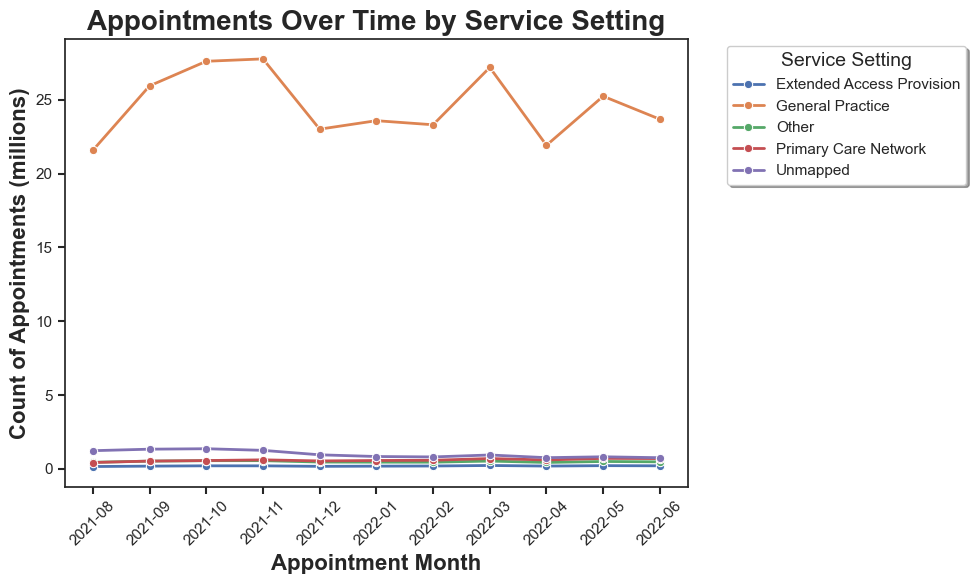

In [54]:
# Plot the appointments over the available date range, and review the service settings for months.
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(10,6)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='service_setting', data=nc_monthly,
            errorbar=None, linewidth=2, marker='o', ax=ax)

# Adding title and labels
ax.set_title('Appointments Over Time by Service Setting', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_service_setting.png', dpi=300)
plt.show()

**Context types:**

In [55]:
# Create a separate data set that can be used in future weeks.

context_monthly= nc_copy.groupby(['context_type','appointment_month'])[['count_millions']].sum()
                                
# View output.
context_monthly

count_millions
context_type           appointment_month                
Care Related Encounter 2021-08                 20.255235
                       2021-09                 24.404251
                       2021-10                 26.125201
                       2021-11                 26.282778
                       2021-12                 21.798612
                       2022-01                 22.441947
                       2022-02                 22.211021
                       2022-03                 25.928850
                       2022-04                 20.904193
                       2022-05                 24.101243
                       2022-06                 22.621827
Inconsistent Mapping   2021-08                  2.363093
                       2021-09                  2.782135
                       2021-10                  2.811977
                       2021-11                  2.865796
                       2021-12                  2.387907
                       2022-01                  2.353965
                       2022-02                  2.332993
                       2022-03                  2.723276
                       2022-04                  2.248554
                       2022-05                  2.573495
                       2022-06                  2.447611
Unmapped               2021-08                  1.233843
                       2021-09                  1.336115
                       2021-10                  1.366656
                       2021-11                  1.256496
                       2021-12                  0.954257
                       2022-01                  0.839562
                       2022-02                  0.811246
                       2022-03                  0.942912
                       2022-04                  0.760313
                       2022-05                  0.820770
                       2022-06                  0.758640

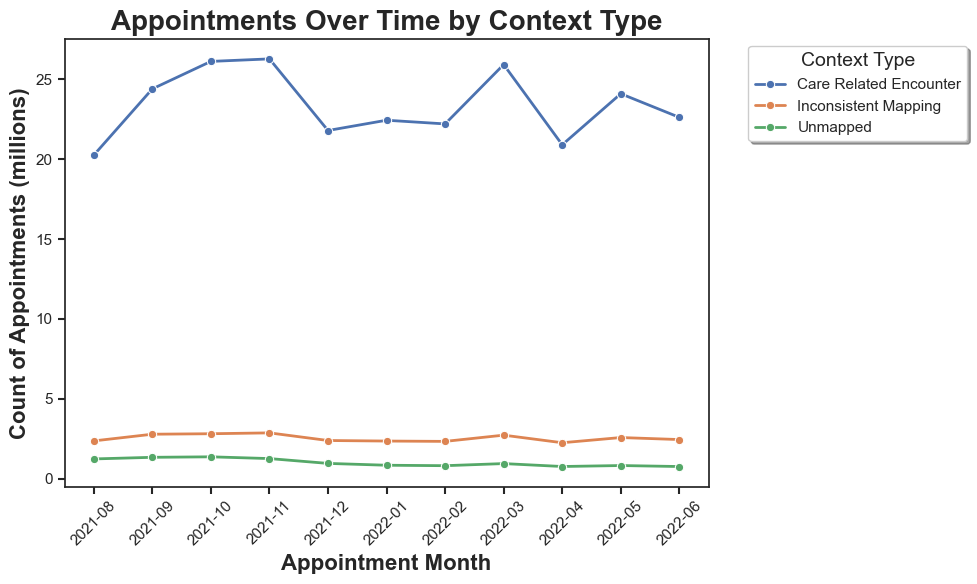

In [56]:
# Plot the appointments over the available date range, and review the context types for months.
# Create a lineplot.

fig, ax = plt.subplots()
fig.set_size_inches(10,6)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='context_type', data=context_monthly,
            errorbar=None, linewidth=2, marker='o', ax=ax)

# Adding title and labels

ax.set_title('Appointments Over Time by Context Type', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(title='Context Type', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_context_type.png', dpi=300)
plt.show()

**National categories:**

In [57]:
# Create a separate data set that can be used in future weeks. 

national_categories= nc_copy.groupby(['appointment_month','national_category'])\
                                    [['count_millions']]\
                                    .sum()
# View output.
national_categories

count_millions
appointment_month national_category                                                 
2021-08           Care Home Needs Assessment & Personalised Care ...        0.029676
                  Care Home Visit                                           0.047583
                  Clinical Triage                                           3.704207
                  General Consultation Acute                                4.280920
                  General Consultation Routine                              7.756045
...                                                                              ...
2022-06           Social Prescribing Service                                0.055066
                  Structured Medication Review                              0.187800
                  Unmapped                                                  0.758640
                  Unplanned Clinical Activity                               0.274491
                  Walk-in                                                   0.035935

[198 rows x 1 columns]

### Extra steps:

- As there are many categories in the national category, plotting them altogether without order would make it hard to follow

-> Will create different variable to make arrange legends that can follow the order of each lineplot

In [58]:
# get the last value of each category
last_values = national_categories.groupby('national_category')\
              ['count_millions']\
                .last().sort_values(ascending=False)

last_values

national_category
General Consultation Routine                                           8.691384
General Consultation Acute                                             4.882755
Clinical Triage                                                        3.391163
Planned Clinics                                                        2.556175
Inconsistent Mapping                                                   2.447611
Planned Clinical Procedure                                             2.032073
Unmapped                                                               0.758640
Unplanned Clinical Activity                                            0.274491
Home Visit                                                             0.193923
Structured Medication Review                                           0.187800
Patient contact during Care Home Round                                 0.119022
Service provided by organisation external to the practice              0.081663
Care Home Visit       

In [59]:
all_categories = last_values.index.tolist()

all_categories

['General Consultation Routine',
 'General Consultation Acute',
 'Clinical Triage',
 'Planned Clinics',
 'Inconsistent Mapping',
 'Planned Clinical Procedure',
 'Unmapped',
 'Unplanned Clinical Activity',
 'Home Visit',
 'Structured Medication Review',
 'Patient contact during Care Home Round',
 'Service provided by organisation external to the practice',
 'Care Home Visit',
 'Social Prescribing Service',
 'Care Home Needs Assessment & Personalised Care and Support Planning',
 'Walk-in',
 'Non-contractual chargeable work',
 'Group Consultation and Group Education']

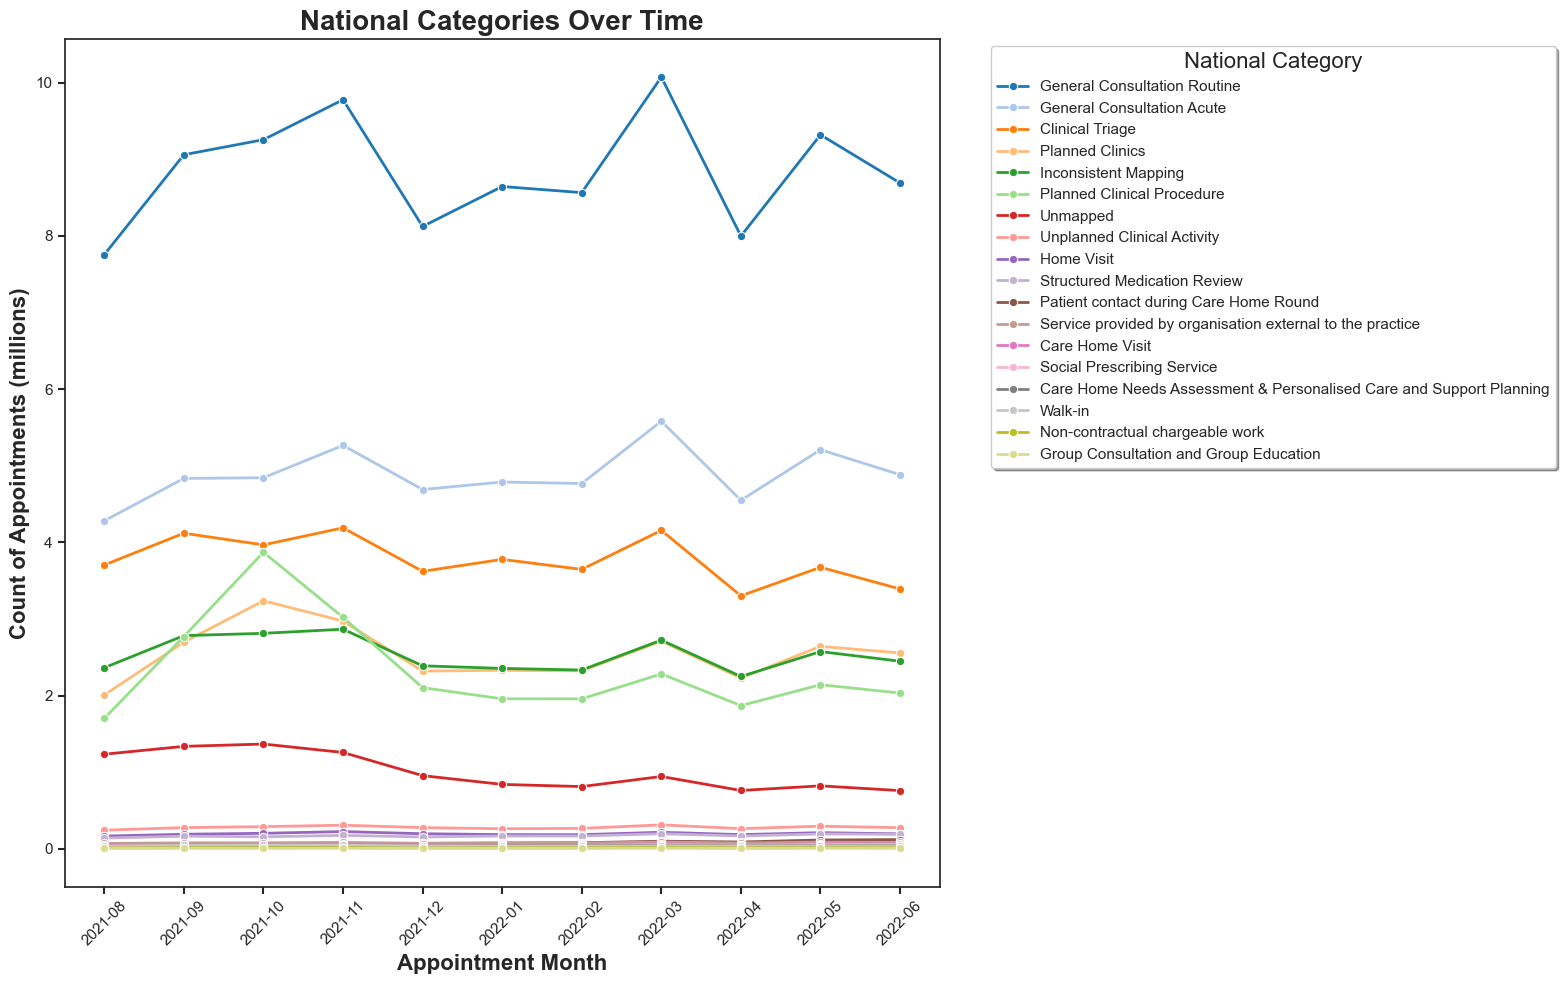

In [60]:
# Plot the appointments over the available date range, and review the national categories for months.
# Adding more color options for better visualisation
import matplotlib.cm as cm
colors = cm.tab20.colors 

# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(16,10)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='national_category',
             hue_order=all_categories, # control legend order
             data=national_categories,
             errorbar=None, 
             linewidth=2, marker='o', ax=ax, palette= colors)

# Adding title and labels

ax.set_title('National Categories Over Time', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(bbox_to_anchor=(1.05, 1),
          title='National Category', title_fontsize=16,
           frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_national_category.png', dpi=300)
plt.show()

#### As the above chart was overcrowded, decided to plot another chart that limits to 5 top categories 

In [61]:
# Limited to top 7 National Categories

top7 = last_values.head(7).index.tolist()

top7

['General Consultation Routine',
 'General Consultation Acute',
 'Clinical Triage',
 'Planned Clinics',
 'Inconsistent Mapping',
 'Planned Clinical Procedure',
 'Unmapped']

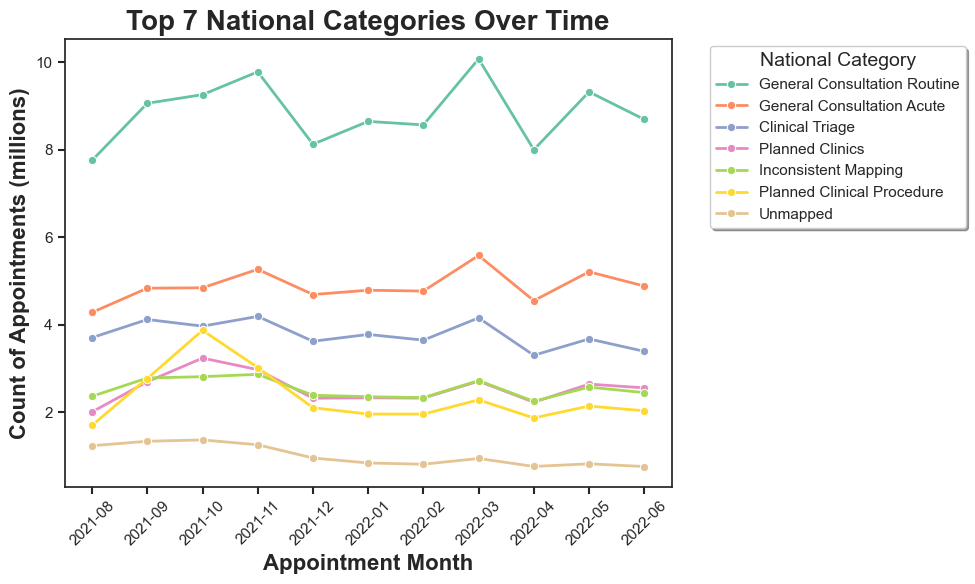

In [62]:
# Plot the appointments over the available date range, and review the national categories for months.
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(10,6)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='national_category',
             hue_order=top7, # control legend order
             data=national_categories,
             errorbar=None, 
             linewidth=2, marker='o', ax=ax, palette='Set2')

# Adding title and labels

ax.set_title('Top 7 National Categories Over Time', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(bbox_to_anchor=(1.05, 1),
          title='National Category', title_fontsize=14,
          frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_top 7_national_category.png', dpi=300)
plt.show()

In [63]:
# Filter the last 11 national categories

last11 = last_values.tail(11).index.tolist()

last11

['Unplanned Clinical Activity',
 'Home Visit',
 'Structured Medication Review',
 'Patient contact during Care Home Round',
 'Service provided by organisation external to the practice',
 'Care Home Visit',
 'Social Prescribing Service',
 'Care Home Needs Assessment & Personalised Care and Support Planning',
 'Walk-in',
 'Non-contractual chargeable work',
 'Group Consultation and Group Education']

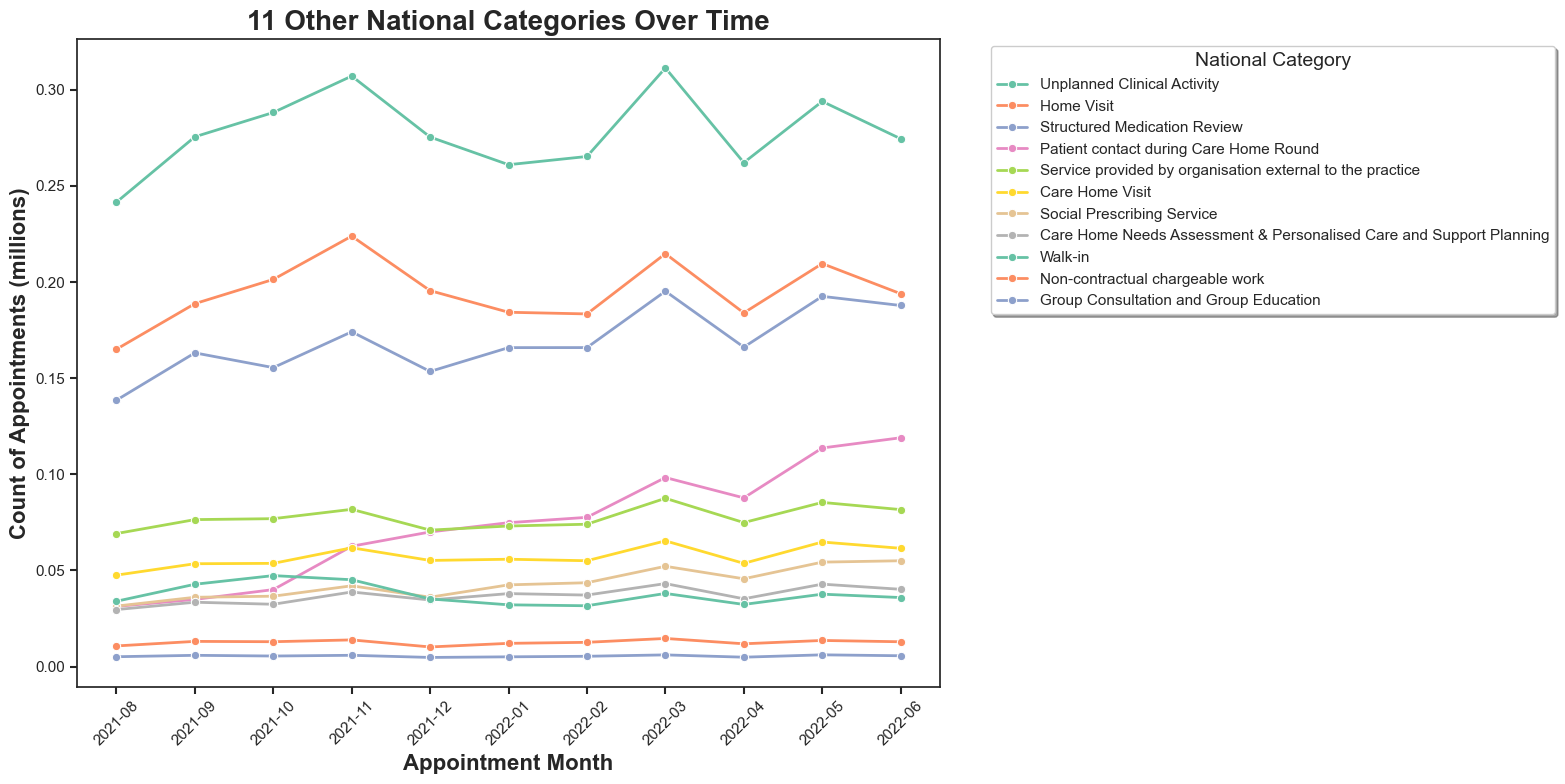

In [64]:
# Plot the appointments over the available date range, and review the national categories for months.
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(16,8)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='national_category',
             hue_order=last11, # control legend order
             data=national_categories,
             errorbar=None, 
             linewidth=2, marker='o', ax=ax, palette='Set2')

# Adding title and labels

ax.set_title('11 Other National Categories Over Time', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(bbox_to_anchor=(1.05, 1),
          title='National Category', title_fontsize=14,
          frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_11_other_types_national_category.png', dpi=300)
plt.show()

#### Key takeaways from above charts:

- The majority of national category type appointments show the same pattern over the period: steady rise from August 2021 to November 2021 and reached their peak in November 2021, followed by a sharp drop in December 2021, then kept a steady rise until March 2022 before dropped sharply in April 2022.
- Outliers that caught my attention:
+ Planned clinical procedure and planned clinics: all reached their top levels of appointments in October 2021
+ Patient contact during Care Home Round rise steadily over the time.

-> Will take a look further into understanding these details

#### Investigation into Planned Clinics and Planned Clinical Procedure

In [65]:
nc_clinics = nc[nc['national_category'].isin(['Planned Clinics', 'Planned Clinical Procedure'])]

nc_clinics

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,0.000007
11,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinical Procedure,3,2021-08,0.000003
18,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,8,2021-08,0.000008
24,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Extended Access Provision,Care Related Encounter,Planned Clinics,15,2021-08,0.000015
25,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Planned Clinics,1993,2021-08,0.001993
...,...,...,...,...,...,...,...,...,...
817377,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Planned Clinics,851,2022-06,0.000851
817378,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Planned Clinical Procedure,552,2022-06,0.000552
817382,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,2,2022-06,0.000002
817390,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-06,0.000004


In [66]:
nc_clinics.columns.tolist()

['appointment_date',
 'icb_ons_code',
 'sub_icb_location_name',
 'service_setting',
 'context_type',
 'national_category',
 'count_of_appointments',
 'appointment_month',
 'count_millions']

In [67]:
nc_clinics['appointment_month']= pd.to_datetime(nc['appointment_month']).dt.strftime('%Y-%m')

#### Finding which ICB drove the strange pattern in 2021-09 and 2021-10

In [68]:
nc_clinics_1 = nc_clinics.groupby(['appointment_month', 'sub_icb_location_name','national_category'])['count_millions'].sum().reset_index()

nc_clinics_1

,appointment_month,sub_icb_location_name,national_category,count_millions
0,2021-08,NHS Bath and North East Somerset Swindon and W...,Planned Clinical Procedure,0.039840
1,2021-08,NHS Bath and North East Somerset Swindon and W...,Planned Clinics,0.040029
2,2021-08,NHS Bedfordshire Luton and Milton Keynes ICB -...,Planned Clinical Procedure,0.020858
3,2021-08,NHS Bedfordshire Luton and Milton Keynes ICB -...,Planned Clinics,0.068027
4,2021-08,NHS Birmingham and Solihull ICB - 15E,Planned Clinical Procedure,0.044664
...,...,...,...,...
2326,2022-06,NHS West Yorkshire ICB - 15F,Planned Clinics,0.065517
2327,2022-06,NHS West Yorkshire ICB - 36J,Planned Clinical Procedure,0.027770
2328,2022-06,NHS West Yorkshire ICB - 36J,Planned Clinics,0.028502
2329,2022-06,NHS West Yorkshire ICB - X2C4Y,Planned Clinical Procedure,0.012258


In [69]:
spike_period = nc_clinics_1[nc_clinics_1['appointment_month'].isin(['2021-09', '2021-10'])]

top_icb_spike = spike_period.groupby('sub_icb_location_name')['count_millions']\
                 .sum()\
                 .sort_values(ascending=False).head(8)
top_icb_spike

sub_icb_location_name
NHS North West London ICB - W2U3Z                       0.598626
NHS Hampshire and Isle Of Wight ICB - D9Y0V             0.419443
NHS Devon ICB - 15N                                     0.385445
NHS Kent and Medway ICB - 91Q                           0.376268
NHS Norfolk and Waveney ICB - 26A                       0.312014
NHS North East London ICB - A3A8R                       0.305289
NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y    0.279939
NHS Black Country ICB - D2P2L                           0.275641
Name: count_millions, dtype: float64

In [70]:
# Create a DataFrame that includes all 8 sub-ICBs that got the most appointments in those 2 national category types
nc_clinics_2 = nc_clinics_1[nc_clinics_1['sub_icb_location_name'].isin(['NHS North West London ICB - W2U3Z', 'NHS Hampshire and Isle Of Wight ICB - D9Y0V',
                                                           'NHS Devon ICB - 15N', 'NHS Kent and Medway ICB - 91Q',
                                                           'NHS Norfolk and Waveney ICB - 26A', 'NHS North East London ICB - A3A8R',
                                                           'NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y', 'NHS Black Country ICB - D2P2L'])]
nc_clinics_2
                                                

,appointment_month,sub_icb_location_name,national_category,count_millions
2,2021-08,NHS Bedfordshire Luton and Milton Keynes ICB -...,Planned Clinical Procedure,0.020858
3,2021-08,NHS Bedfordshire Luton and Milton Keynes ICB -...,Planned Clinics,0.068027
6,2021-08,NHS Black Country ICB - D2P2L,Planned Clinical Procedure,0.032301
7,2021-08,NHS Black Country ICB - D2P2L,Planned Clinics,0.045563
42,2021-08,NHS Devon ICB - 15N,Planned Clinical Procedure,0.052713
...,...,...,...,...
2250,2022-06,NHS Norfolk and Waveney ICB - 26A,Planned Clinics,0.077853
2253,2022-06,NHS North East London ICB - A3A8R,Planned Clinical Procedure,0.050851
2254,2022-06,NHS North East London ICB - A3A8R,Planned Clinics,0.063046
2271,2022-06,NHS North West London ICB - W2U3Z,Planned Clinical Procedure,0.058383


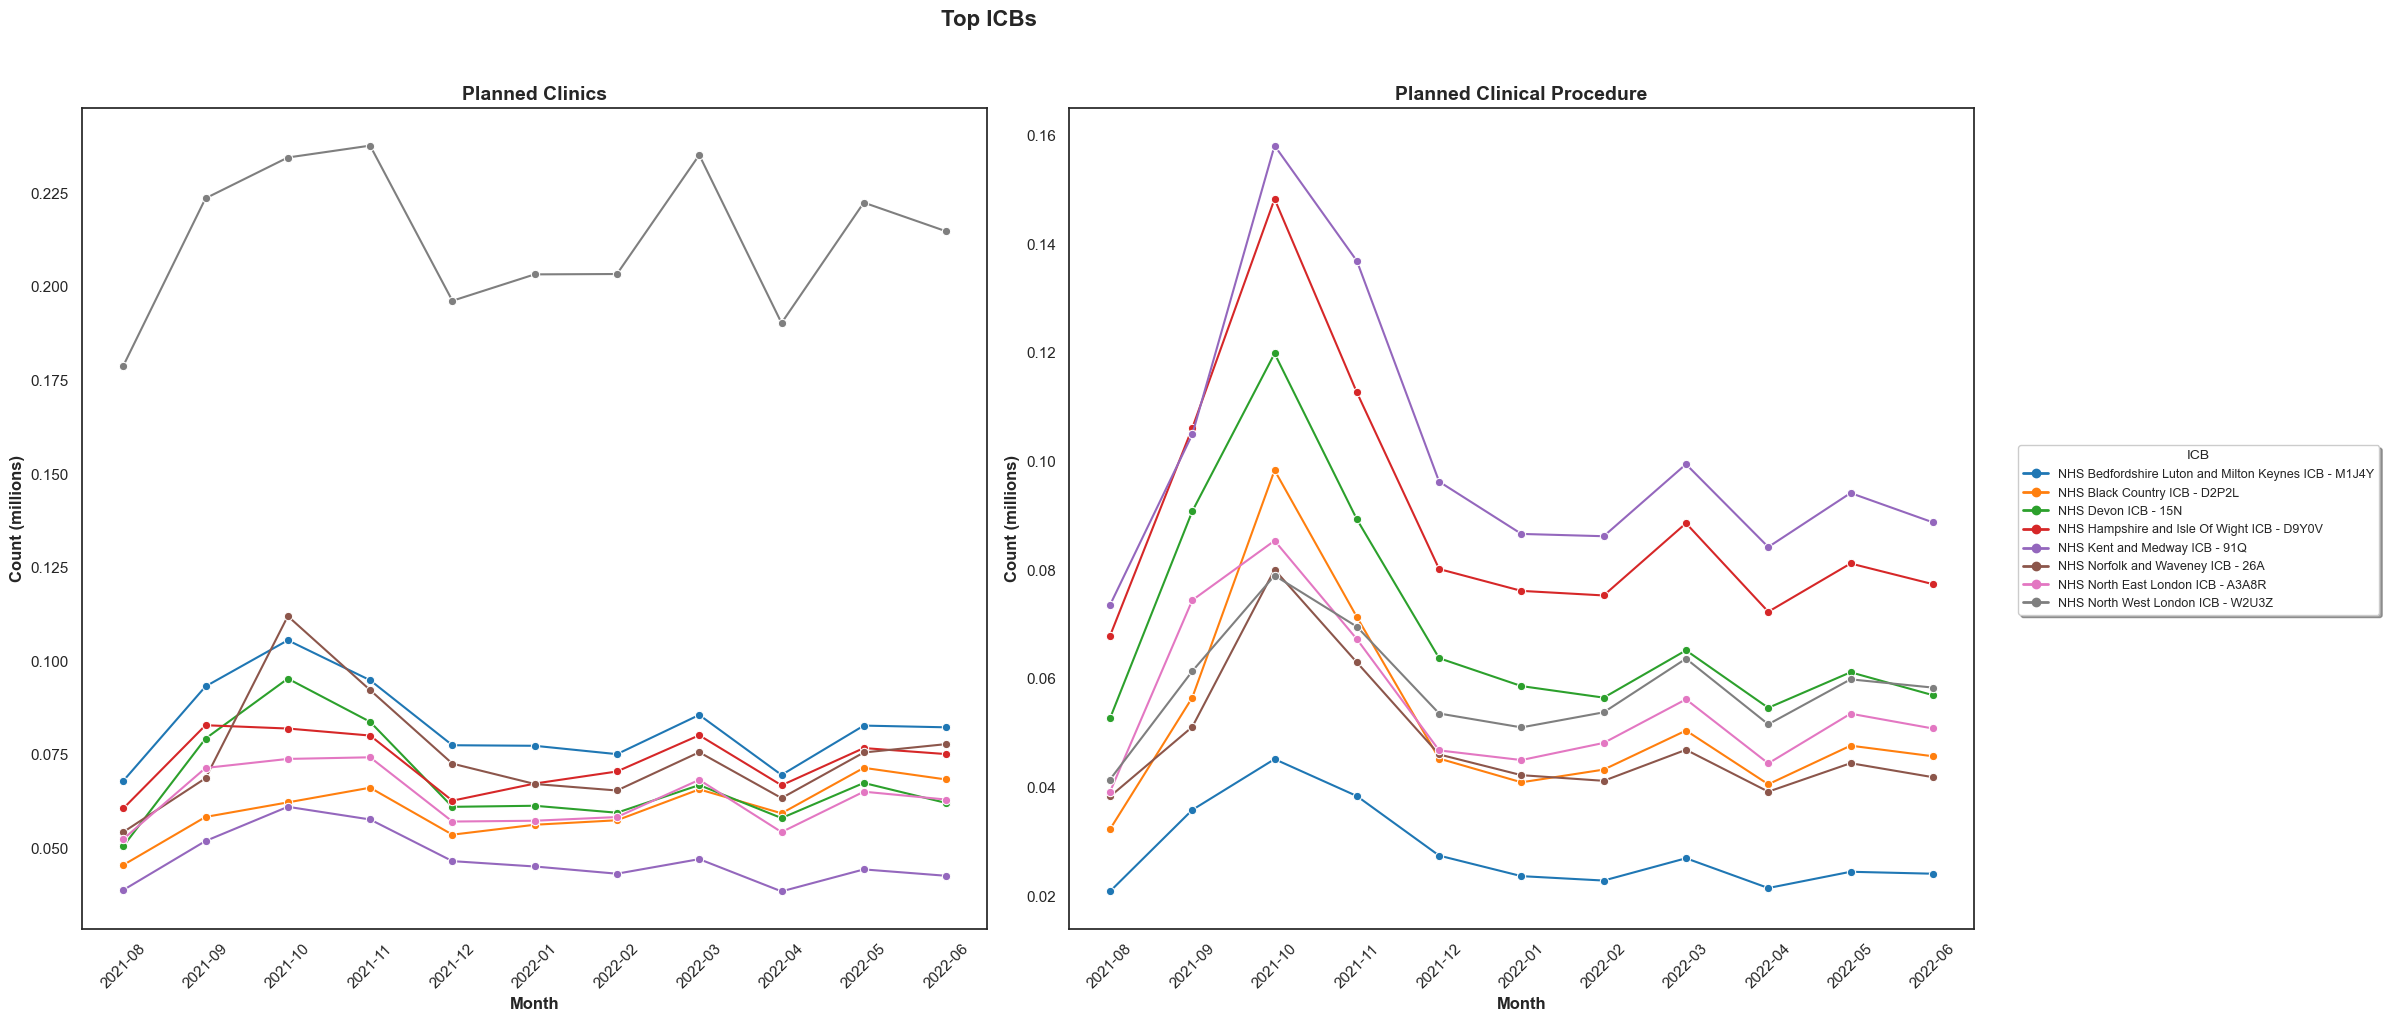

In [71]:
# Step 1 — ensure appointment_month is string and count_millions exists
nc_clinics_2['appointment_month'] = nc_clinics_2['appointment_month'].astype(str)

# Step 2 — build ONE consistent palette from sorted ICB list
icb_list = sorted(nc_clinics_2['sub_icb_location_name'].unique())
palette = dict(zip(icb_list, sns.color_palette('tab10', len(icb_list))))

# Step 3 — plot
fig, axes = plt.subplots(1, 2, figsize=(20,10), sharey=False)

for ax, cat in zip(axes, ['Planned Clinics', 'Planned Clinical Procedure']):
    subset = nc_clinics_2[nc_clinics_2['national_category'] == cat]
    
    sns.lineplot(data=subset,
                 x='appointment_month',
                 y='count_millions',
                 hue='sub_icb_location_name',
                 palette=palette,
                 hue_order=icb_list,
                 marker='o',
                 ax=ax,
                 legend=False)          # no per-axis legend
    
    ax.set_title(cat, fontsize=14, fontweight='bold')
    ax.set_xlabel('Month', fontsize=12, fontweight='bold')
    ax.set_ylabel('Count (millions)', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

# Step 4 — single shared legend built manually from palette
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], color=palette[icb], marker='o', linewidth=2, label=icb)
    for icb in icb_list
]

fig.legend(handles=legend_handles,
           bbox_to_anchor=(1.01, 0.5),
           loc='center left',
           title='ICB',
           fontsize=9,
           title_fontsize=10,
           frameon=True,
           shadow=True)

plt.suptitle('Top ICBs ',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('icb_regional_variation.png', dpi=300, bbox_inches='tight')
plt.show()

In [72]:
# Find the top ICBs with most appointments in Planned Clinics
planned_clinics = nc_clinics_2[nc_clinics_2['national_category'] == 'Planned Clinics']
top_planned_clinics = (planned_clinics.groupby('sub_icb_location_name')['count_millions']
               .sum()
               .sort_values(ascending=False))
total_planned_clinics = top_planned_clinics.sum()

top_planned_clinics_pct = top_planned_clinics.reset_index()
top_planned_clinics_pct.columns = ['sub_icb_location_name', 'count_millions']
top_planned_clinics_pct['percentage'] = (top_planned_clinics_pct['count_millions'] / total_planned_clinics * 100).round(2)

print(top_planned_clinics_pct.to_string(index=False))

                               sub_icb_location_name  count_millions  percentage
                   NHS North West London ICB - W2U3Z        2.340773       31.18
NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y        0.912375       12.15
                   NHS Norfolk and Waveney ICB - 26A        0.825340       10.99
         NHS Hampshire and Isle Of Wight ICB - D9Y0V        0.805400       10.73
                                 NHS Devon ICB - 15N        0.745754        9.93
                   NHS North East London ICB - A3A8R        0.695997        9.27
                       NHS Black Country ICB - D2P2L        0.665026        8.86
                       NHS Kent and Medway ICB - 91Q        0.517413        6.89


In [73]:
# Test whether the spike is driven by NW London alone
without_nwl = nc_clinics_2[nc_clinics_2['sub_icb_location_name'] != 'NHS North West London ICB - W2U3Z']

clinics_no_nwl = (without_nwl[without_nwl['national_category'] == 'Planned Clinics']
                  .groupby('appointment_month')['count_millions']
                  .sum())

print(clinics_no_nwl)

appointment_month
2021-08    0.370551
2021-09    0.506116
2021-10    0.592307
2021-11    0.549439
2021-12    0.431473
2022-01    0.432197
2022-02    0.429840
2022-03    0.489691
2022-04    0.410261
2022-05    0.483762
2022-06    0.471668
Name: count_millions, dtype: float64


In [74]:
# Find the top ICBs with most appointments in Planned Clinical Procedure with the percentage
procedure_clinics = nc_clinics_2[nc_clinics_2['national_category'] == 'Planned Clinical Procedure']
top_procedure_clinics = (procedure_clinics.groupby('sub_icb_location_name')['count_millions']
               .sum()
               .sort_values(ascending=False))
total = top_procedure_clinics.sum()

top_procedure_clinics_pct = top_procedure_clinics.reset_index()
top_procedure_clinics_pct.columns = ['sub_icb_location_name', 'count_millions']
top_procedure_clinics_pct['percentage'] = (top_procedure_clinics_pct['count_millions'] / total * 100).round(2)

print(top_procedure_clinics_pct.to_string(index=False))

                               sub_icb_location_name  count_millions  percentage
                       NHS Kent and Medway ICB - 91Q        1.109739       20.03
         NHS Hampshire and Isle Of Wight ICB - D9Y0V        0.986557       17.81
                                 NHS Devon ICB - 15N        0.769914       13.90
                   NHS North West London ICB - W2U3Z        0.643581       11.62
                   NHS North East London ICB - A3A8R        0.611519       11.04
                       NHS Black Country ICB - D2P2L        0.572648       10.34
                   NHS Norfolk and Waveney ICB - 26A        0.534623        9.65
NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y        0.311308        5.62


#### Insights from above charts and tables

- Planned Clinical Procedure: all top 8 ICBs showed a similar pattern to the general pattern; this can be explained by the spike from August 2021 to October 2021 happening at a national level. The top 6 ICBs account for 80% of the whole nation, which means this type of appointment is fairly concentrated in 6 ICBs, and if the NHS wants to deploy a new policy, bringing changes to those 6 ICBS might result in a national effect.
- Planned Clinics: 1 ICB account for almost 31% of all appointments across the whole country, while others ICB share the same patterns, this ICB shows a slightly different pattern with reaching its peak in November 2021
  

In [75]:
# Check if NW London has unusually high row counts vs other ICBs
row_counts = (nc_clinics_2[nc_clinics_2['national_category'] == 'Planned Clinics']
              .groupby('sub_icb_location_name')
              .agg(
                  row_count=('count_millions', 'count'),
                  total_appointments=('count_millions', 'sum'),
                  avg_per_row=('count_millions', 'mean')
              )
              .sort_values('total_appointments', ascending=False))

print(row_counts.head(10))

                                                    row_count  \
sub_icb_location_name                                           
NHS North West London ICB - W2U3Z                          11   
NHS Bedfordshire Luton and Milton Keynes ICB - ...         11   
NHS Norfolk and Waveney ICB - 26A                          11   
NHS Hampshire and Isle Of Wight ICB - D9Y0V                11   
NHS Devon ICB - 15N                                        11   
NHS North East London ICB - A3A8R                          11   
NHS Black Country ICB - D2P2L                              11   
NHS Kent and Medway ICB - 91Q                              11   

                                                    total_appointments  \
sub_icb_location_name                                                    
NHS North West London ICB - W2U3Z                             2.340773   
NHS Bedfordshire Luton and Milton Keynes ICB - ...            0.912375   
NHS Norfolk and Waveney ICB - 26A                    

#### Validating the information why NHS North West London ICB - W2U3Z got that amount of surprising high appointments

In [76]:
# Getting the sub_icb_location_ons_code from actual_duration dataset to link with another dataset

top8= ad[ad['sub_icb_location_name'].\
    isin(['NHS North West London ICB - W2U3Z','NHS Bedfordshire Luton and Milton Keynes ICB - M1J4Y ',
         'NHS Norfolk and Waveney ICB - 26A', 'NHS Hampshire and Isle Of Wight ICB - D9Y0V',
        'NHS Devon ICB - 15N', 'NHS North East London ICB - A3A8R',
          'NHS Black Country ICB - D2P2L','NHS Kent and Medway ICB - 91Q'])]
top8

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments
92450,15N,E38000230,NHS Devon ICB - 15N,E54000037,E40000006,2021-12-01,Unknown / Data Quality,4927
92451,15N,E38000230,NHS Devon ICB - 15N,E54000037,E40000006,2021-12-01,6-10 Minutes,6569
92452,15N,E38000230,NHS Devon ICB - 15N,E54000037,E40000006,2021-12-01,31-60 Minutes,1632
92453,15N,E38000230,NHS Devon ICB - 15N,E54000037,E40000006,2021-12-01,21-30 Minutes,2870
92454,15N,E38000230,NHS Devon ICB - 15N,E54000037,E40000006,2021-12-01,16-20 Minutes,2952
...,...,...,...,...,...,...,...,...
136508,W2U3Z,E38000256,NHS North West London ICB - W2U3Z,E54000027,E40000003,2022-06-30,31-60 Minutes,2653
136509,W2U3Z,E38000256,NHS North West London ICB - W2U3Z,E54000027,E40000003,2022-06-30,21-30 Minutes,4038
136510,W2U3Z,E38000256,NHS North West London ICB - W2U3Z,E54000027,E40000003,2022-06-30,16-20 Minutes,4222
136511,W2U3Z,E38000256,NHS North West London ICB - W2U3Z,E54000027,E40000003,2022-06-30,11-15 Minutes,6835


In [77]:
top_icbs=top8.groupby(['sub_icb_location_name', 'sub_icb_location_ons_code'])['count_of_appointments'].sum().reset_index()

top_icbs

,sub_icb_location_name,sub_icb_location_ons_code,count_of_appointments
0,NHS Black Country ICB - D2P2L,E38000259,3901431
1,NHS Devon ICB - 15N,E38000230,4255338
2,NHS Hampshire and Isle Of Wight ICB - D9Y0V,E38000253,4712737
3,NHS Kent and Medway ICB - 91Q,E38000237,5209641
4,NHS Norfolk and Waveney ICB - 26A,E38000239,3490647
5,NHS North East London ICB - A3A8R,E38000255,5341883
6,NHS North West London ICB - W2U3Z,E38000256,6976986


In [78]:
top_icbs['sub_icb_location_ons_code'].tolist()

['E38000259',
 'E38000230',
 'E38000253',
 'E38000237',
 'E38000239',
 'E38000255',
 'E38000256']

In [79]:
# Getting number of patients from these 8 top ICBs

patients=pd.read_csv('gp-reg-pat-prac-all.csv')

patients

,PUBLICATION,EXTRACT_DATE,TYPE,SUB_ICB_LOCATION_CODE,ONS_SUB_ICB_LOCATION_CODE,CODE,POSTCODE,SEX,AGE,NUMBER_OF_PATIENTS
0,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81001,TS18 1HU,ALL,ALL,3889
1,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81002,TS18 2AW,ALL,ALL,18742
2,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81004,TS5 8SB,ALL,ALL,11327
3,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81005,TS14 7DJ,ALL,ALL,7726
4,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81006,TS18 2AT,ALL,ALL,14738
...,...,...,...,...,...,...,...,...,...,...
6244,GP_PRAC_PAT_LIST,2025-01-01,GP,02Q,E38000008,Y08082,DN22 7XF,ALL,ALL,9
6245,GP_PRAC_PAT_LIST,2025-01-01,GP,03R,E38000190,Y08186,BD1 3LS,ALL,ALL,27
6246,GP_PRAC_PAT_LIST,2025-01-01,GP,A3A8R,E38000255,Y08371,RM13 8QZ,ALL,ALL,2419
6247,GP_PRAC_PAT_LIST,2025-01-01,GP,36L,E38000245,Y08402,CR0 1FE,ALL,ALL,31


In [80]:
patients_top8= patients[patients['ONS_SUB_ICB_LOCATION_CODE'].isin(['E38000259',
 'E38000230',
 'E38000253',
 'E38000237',
 'E38000239',
 'E38000255',
 'E38000256'])]

patients_group=patients_top8.groupby('ONS_SUB_ICB_LOCATION_CODE')['NUMBER_OF_PATIENTS'].sum().reset_index()

patients_group= patients_group.rename(columns={'ONS_SUB_ICB_LOCATION_CODE':'sub_icb_location_ons_code'})

patients_group

,sub_icb_location_ons_code,NUMBER_OF_PATIENTS
0,E38000230,1298178
1,E38000237,2035099
2,E38000239,1100260
3,E38000253,1735245
4,E38000255,2469805
5,E38000256,2902259
6,E38000259,1341002


In [81]:
patients_merge= pd.merge(patients_group, top_icbs, on='sub_icb_location_ons_code', how='outer')

patients_merge.sort_values(by='NUMBER_OF_PATIENTS', ascending=False)

,sub_icb_location_ons_code,NUMBER_OF_PATIENTS,sub_icb_location_name,count_of_appointments
5,E38000256,2902259,NHS North West London ICB - W2U3Z,6976986
4,E38000255,2469805,NHS North East London ICB - A3A8R,5341883
1,E38000237,2035099,NHS Kent and Medway ICB - 91Q,5209641
3,E38000253,1735245,NHS Hampshire and Isle Of Wight ICB - D9Y0V,4712737
6,E38000259,1341002,NHS Black Country ICB - D2P2L,3901431
0,E38000230,1298178,NHS Devon ICB - 15N,4255338
2,E38000239,1100260,NHS Norfolk and Waveney ICB - 26A,3490647


In [218]:
# Calculating appointments per 1000 registered patients:
patients_merge['appts_per_1000'] = (
    (patients_merge['count_of_appointments'] / patients_merge['NUMBER_OF_PATIENTS']) * 1000
).round(1)

patients_merge.sort_values(by='count_of_appointments', ascending=False)

,sub_icb_location_ons_code,NUMBER_OF_PATIENTS,sub_icb_location_name,count_of_appointments,appts_per_1000
5,E38000256,2902259,NHS North West London ICB - W2U3Z,6976986,2404.0
4,E38000255,2469805,NHS North East London ICB - A3A8R,5341883,2162.9
1,E38000237,2035099,NHS Kent and Medway ICB - 91Q,5209641,2559.9
3,E38000253,1735245,NHS Hampshire and Isle Of Wight ICB - D9Y0V,4712737,2715.9
0,E38000230,1298178,NHS Devon ICB - 15N,4255338,3277.9
6,E38000259,1341002,NHS Black Country ICB - D2P2L,3901431,2909.3
2,E38000239,1100260,NHS Norfolk and Waveney ICB - 26A,3490647,3172.6


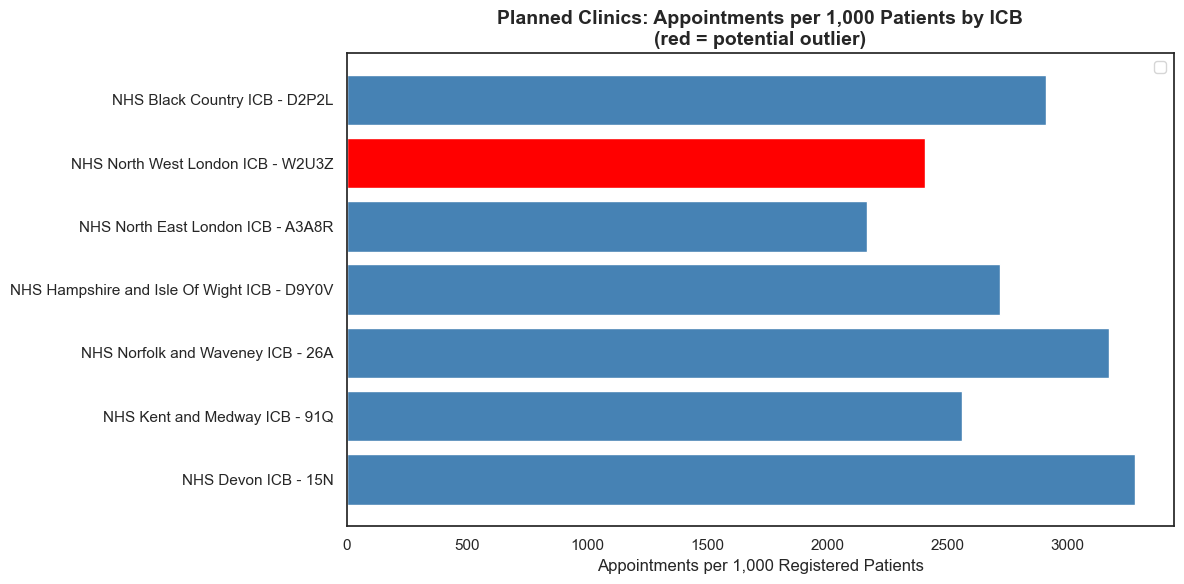

In [83]:
# Plot the figure

ig, ax = plt.subplots(figsize=(12, 6))

colors = ['red' if 'W2U3Z' in str(x) else 'steelblue' 
          for x in patients_merge['sub_icb_location_name']]

ax.barh(patients_merge['sub_icb_location_name'], 
        patients_merge['appts_per_1000'],
        color=colors)

# Adding title and label
ax.set_xlabel('Appointments per 1,000 Registered Patients', fontsize=12)
ax.set_title('Planned Clinics: Appointments per 1,000 Patients by ICB\n(red = potential outlier)', 
             fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('appts_per_1000_patients.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key takeaway:

- NHS North West London ICB - W2U3Z does not appear as an outlier due to data duplicates - it has the largest registered patient base compared to other ICBs, that's why it accounts for 31% in the planned clinics appointments in the whole nation.
- Any change to this ICB planned clinics appointments type can have a big effect on the whole nation' planned clinics performance.

#### Patient Care Home Round

This national category type is currently showing a completely contrast pattern compared to other types - a steady clear rising trend.

-> Decided to investigate this a bit further

In [84]:
# Extracting a new dataset dedicated to Patient Care Home Round
care_home = nc[nc['national_category'] == 'Patient contact during Care Home Round']

care_home

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,0.000003
35,2021-08-03,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,2,2021-08,0.000002
51,2021-08-03,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Patient contact during Care Home Round,47,2021-08,0.000047
68,2021-08-04,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,7,2021-08,0.000007
76,2021-08-04,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Patient contact during Care Home Round,15,2021-08,0.000015
...,...,...,...,...,...,...,...,...,...
817286,2022-06-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,102,2022-06,0.000102
817312,2022-06-29,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,7,2022-06,0.000007
817336,2022-06-29,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Patient contact during Care Home Round,16,2022-06,0.000016
817355,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,18,2022-06,0.000018


In [85]:
# Take a look at which service settings are driving the growth?

care_home_service= care_home.groupby(['service_setting','appointment_month'])['count_millions'].sum().reset_index()

care_home_service

,service_setting,appointment_month,count_millions
0,Extended Access Provision,2021-08,0.000082
1,Extended Access Provision,2021-09,0.000104
2,Extended Access Provision,2021-10,0.000155
3,Extended Access Provision,2021-11,0.000241
4,Extended Access Provision,2021-12,0.000179
5,Extended Access Provision,2022-01,0.000286
6,Extended Access Provision,2022-02,0.000291
7,Extended Access Provision,2022-03,0.000361
8,Extended Access Provision,2022-04,0.000317
9,Extended Access Provision,2022-05,0.000373


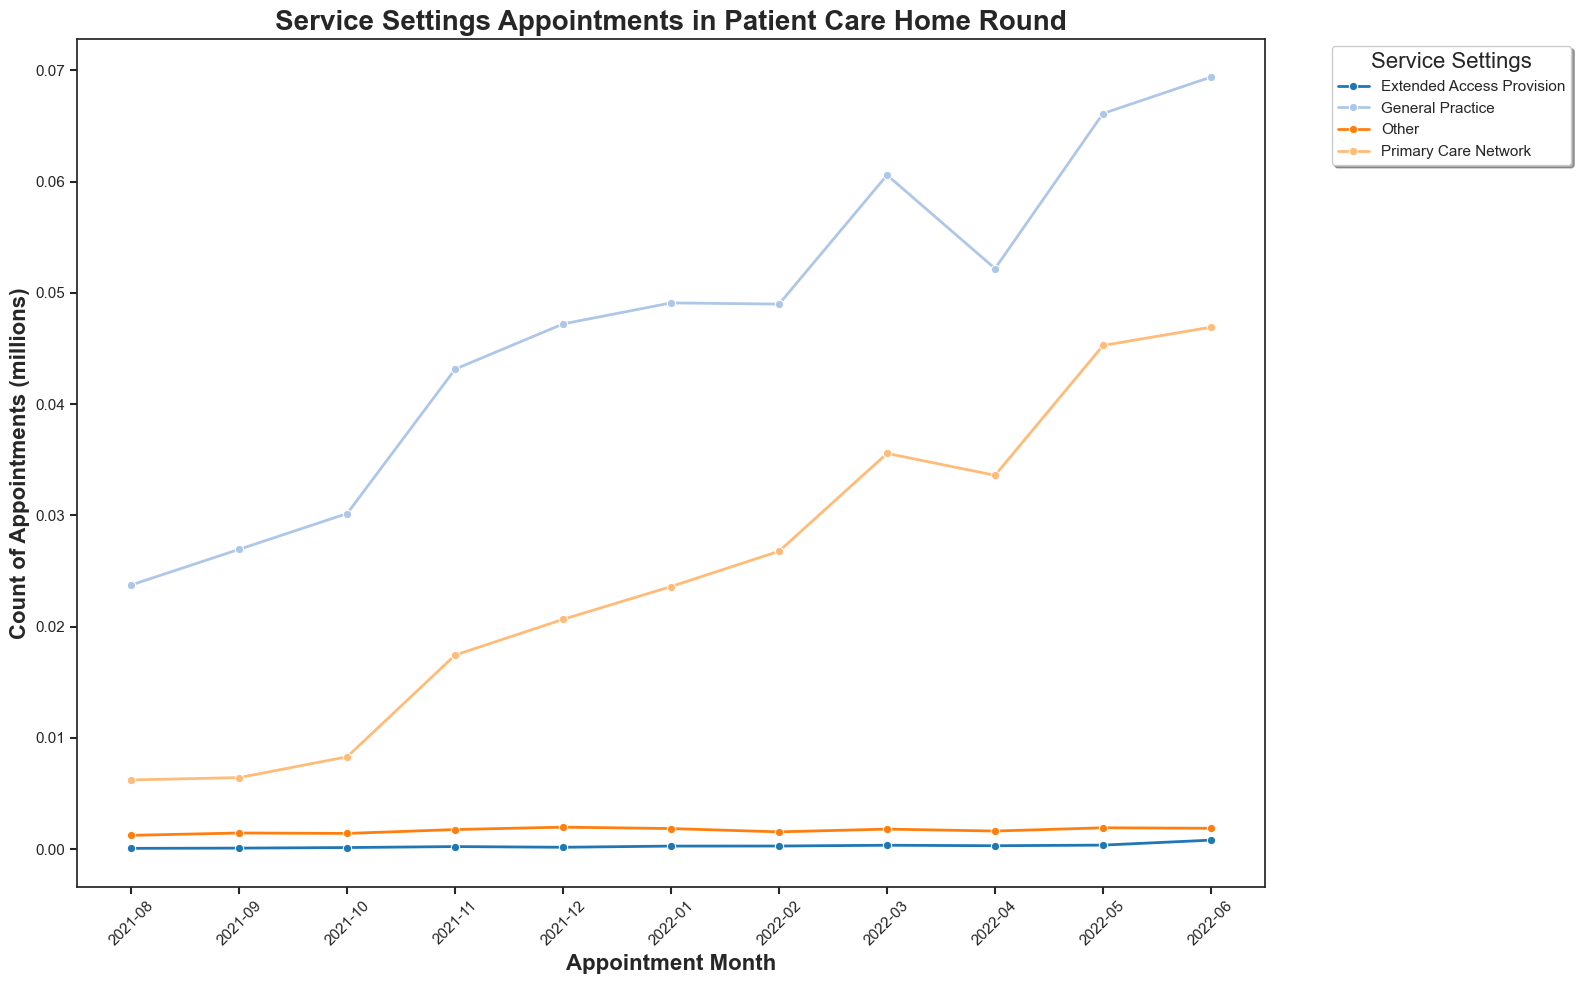

In [86]:
# Plot the appointments over the available date range, and review the national categories for months.
# Adding more color options for better visualisation
import matplotlib.cm as cm
colors = cm.tab20.colors 

# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(16,10)
# Plot data

sns.lineplot(x='appointment_month', y='count_millions', hue='service_setting',
             data=care_home_service,
             errorbar=None, 
             linewidth=2, marker='o', ax=ax, palette= colors)

# Adding title and labels

ax.set_title('Service Settings Appointments in Patient Care Home Round', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(bbox_to_anchor=(1.05, 1),
          title='Service Settings', title_fontsize=16,
           frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('service_setting_care_home.png', dpi=300)
plt.show()

In [87]:
# Take a look at ICBs were driving the growth?

care_home_icb = (care_home.groupby(['appointment_month', 'sub_icb_location_name'])
                 ['count_of_appointments'].sum()
                 .reset_index())

care_home_icb.sort_values(by='count_of_appointments', ascending=False)

,appointment_month,sub_icb_location_name,count_of_appointments
992,2022-06,NHS Hampshire and Isle Of Wight ICB - D9Y0V,4800
891,2022-05,NHS Hampshire and Isle Of Wight ICB - D9Y0V,4705
927,2022-05,NHS North East and North Cumbria ICB - 84H,4536
691,2022-03,NHS Hampshire and Isle Of Wight ICB - D9Y0V,4485
977,2022-06,NHS Coventry and Warwickshire ICB - B2M3M,4444
...,...,...,...
223,2021-10,NHS Lancashire and South Cumbria ICB - 00X,2
280,2021-11,NHS Cheshire and Merseyside ICB - 01J,1
315,2021-11,NHS Lancashire and South Cumbria ICB - 00X,1
488,2022-01,NHS Greater Manchester ICB - 01D,1


In [88]:
care_home_icb_total = pd.DataFrame(care_home_icb.groupby('sub_icb_location_name')['count_of_appointments'].sum().reset_index())

care_home_icb_total.sort_values(by=['count_of_appointments'], ascending=False)

,sub_icb_location_name,count_of_appointments
34,NHS Hampshire and Isle Of Wight ICB - D9Y0V,35147
96,NHS Sussex ICB - 70F,30029
20,NHS Devon ICB - 15N,24974
45,NHS Kent and Medway ICB - 91Q,23787
23,NHS Gloucestershire ICB - 11M,23232
...,...,...
9,NHS Cheshire and Merseyside ICB - 01J,116
66,NHS North East and North Cumbria ICB - 00N,33
33,NHS Hampshire and Isle Of Wight ICB - 10R,29
61,NHS Mid and South Essex ICB - 99G,16


In [89]:
# Add percentage column to see the proportion of each ICB
total = care_home_icb_total['count_of_appointments'].sum()
care_home_icb_total['percentage'] = (
    (care_home_icb_total['count_of_appointments'] / total) * 100
).round(2)

care_home_icb_total.sort_values(by='count_of_appointments', ascending=False)

,sub_icb_location_name,count_of_appointments,percentage
34,NHS Hampshire and Isle Of Wight ICB - D9Y0V,35147,4.34
96,NHS Sussex ICB - 70F,30029,3.71
20,NHS Devon ICB - 15N,24974,3.08
45,NHS Kent and Medway ICB - 91Q,23787,2.94
23,NHS Gloucestershire ICB - 11M,23232,2.87
...,...,...,...
9,NHS Cheshire and Merseyside ICB - 01J,116,0.01
66,NHS North East and North Cumbria ICB - 00N,33,0.00
33,NHS Hampshire and Isle Of Wight ICB - 10R,29,0.00
61,NHS Mid and South Essex ICB - 99G,16,0.00


### Key takeaways:
- General Practice and Primary Care Network is striking ahead.
- Extended Access Provision and Other are negligible and flat
- Activity is extremely fragmented — the top ICB (Hampshire) accounts for only 4.34%, and the top 5 combined account for roughly 18%. Across 103 ICBs, no single region dominates
-> The change in Patient Care Home Round happened in a national level, and not just limited to any particular ICBs. This might not entirely suggest that the patients in need of care home services were growing rapidly? Is this something related to the different way of reporting in the NHS system/ how the data was collected also needed to investigate a bit further. If this is soemthing related to how the data was collected, would it be worth it to apply new data collection method to other service settings to improve data collection accuracy?

### Objective 2
Create four visualisations indicating the number of appointments for service setting per season. The seasons are summer (August 2021), autumn (September to November 2021), winter (December to February 2022), and spring (March to May 2022).

**Summer (August 2021):** as the data in nc dataset only started from August 2021

In [90]:
# Create a separate data set that can be used in future weeks. 
nc_summer2021= nc_copy[nc_copy['appointment_month']== '2021-08']

# View output.
nc_summer2021

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,0.000003
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,0.000007
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08,0.000079
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08,0.000725
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08,0.000002
...,...,...,...,...,...,...,...,...,...
808176,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Other,Care Related Encounter,Clinical Triage,20,2021-08,0.000020
808177,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Unplanned Clinical Activity,143,2021-08,0.000143
808178,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Social Prescribing Service,7,2021-08,0.000007
808179,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Home Visit,36,2021-08,0.000036


In [91]:
nc_summer2021.dtypes

appointment_date          object
icb_ons_code              object
sub_icb_location_name     object
service_setting           object
context_type              object
national_category         object
count_of_appointments      int64
appointment_month         object
count_millions           float64
dtype: object

In [92]:
%pip install holidays

In [93]:
# Filter to all business days in a month, excluding weekends and holidays if possible.
# This aims to provide a better presentation of data.
# Create a holiday list.

import holidays

# get UK holidays automatically
uk_holidays = holidays.country_holidays('GB', subdiv='ENG', 
                                         years=[2021, 2022])

# convert to list
my_holiday_list = [str(d) for d in uk_holidays.keys()]

print(my_holiday_list)

['2021-04-02', '2021-05-03', '2021-05-31', '2021-01-01', '2021-12-25', '2021-12-27', '2021-12-26', '2021-12-28', '2021-04-05', '2021-08-30', '2022-04-15', '2022-05-02', '2022-06-02', '2022-06-03', '2022-09-19', '2022-01-01', '2022-01-03', '2022-12-25', '2022-12-27', '2022-12-26', '2022-04-18', '2022-08-29']


In [94]:
# Filter to all business days in a month, excluding weekends and holidays if possible.
# This aims to provide a better presentation of data.
# Create a reusable function.

def business_days(start_date, end_date):
    """ Excluding weekends and holidays in any datasets to provide better presentation of data 
        Input: df, start and end date strings
        Output: dataframe with weekdays only"""
    
    # write a code to excludes weekends and holidays:
    bdays= pd.bdate_range(start=start_date, end=end_date,
                          freq='C', holidays=my_holiday_list)
    # Return a list of dates as business days
    return bdays.strftime('%Y-%m-%d').tolist()

# Test if the function works

august_bdays= business_days('2021-08-02', '2021-08-31')
print(august_bdays)

['2021-08-02', '2021-08-03', '2021-08-04', '2021-08-05', '2021-08-06', '2021-08-09', '2021-08-10', '2021-08-11', '2021-08-12', '2021-08-13', '2021-08-16', '2021-08-17', '2021-08-18', '2021-08-19', '2021-08-20', '2021-08-23', '2021-08-24', '2021-08-25', '2021-08-26', '2021-08-27', '2021-08-31']


In [95]:
# Use business_days as a filter
nc_summer2021_sub= nc_summer2021[nc_summer2021['appointment_date'].isin(august_bdays)]

nc_summer2021_sub

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,0.000003
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,0.000007
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08,0.000079
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08,0.000725
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08,0.000002
...,...,...,...,...,...,...,...,...,...
808176,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Other,Care Related Encounter,Clinical Triage,20,2021-08,0.000020
808177,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Unplanned Clinical Activity,143,2021-08,0.000143
808178,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,Social Prescribing Service,7,2021-08,0.000007
808179,2021-08-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Home Visit,36,2021-08,0.000036


In [96]:
# Create a separate data set that can be used in future weeks. 
summer_2021= nc_summer2021_sub.groupby(['service_setting','appointment_date'])\
             [['count_millions']].sum().reset_index()
# View output.
summer_2021       

,service_setting,appointment_date,count_millions
0,Extended Access Provision,2021-08-02,0.007705
1,Extended Access Provision,2021-08-03,0.007820
2,Extended Access Provision,2021-08-04,0.006917
3,Extended Access Provision,2021-08-05,0.006841
4,Extended Access Provision,2021-08-06,0.005854
...,...,...,...
100,Unmapped,2021-08-24,0.060024
101,Unmapped,2021-08-25,0.054773
102,Unmapped,2021-08-26,0.053806
103,Unmapped,2021-08-27,0.051444


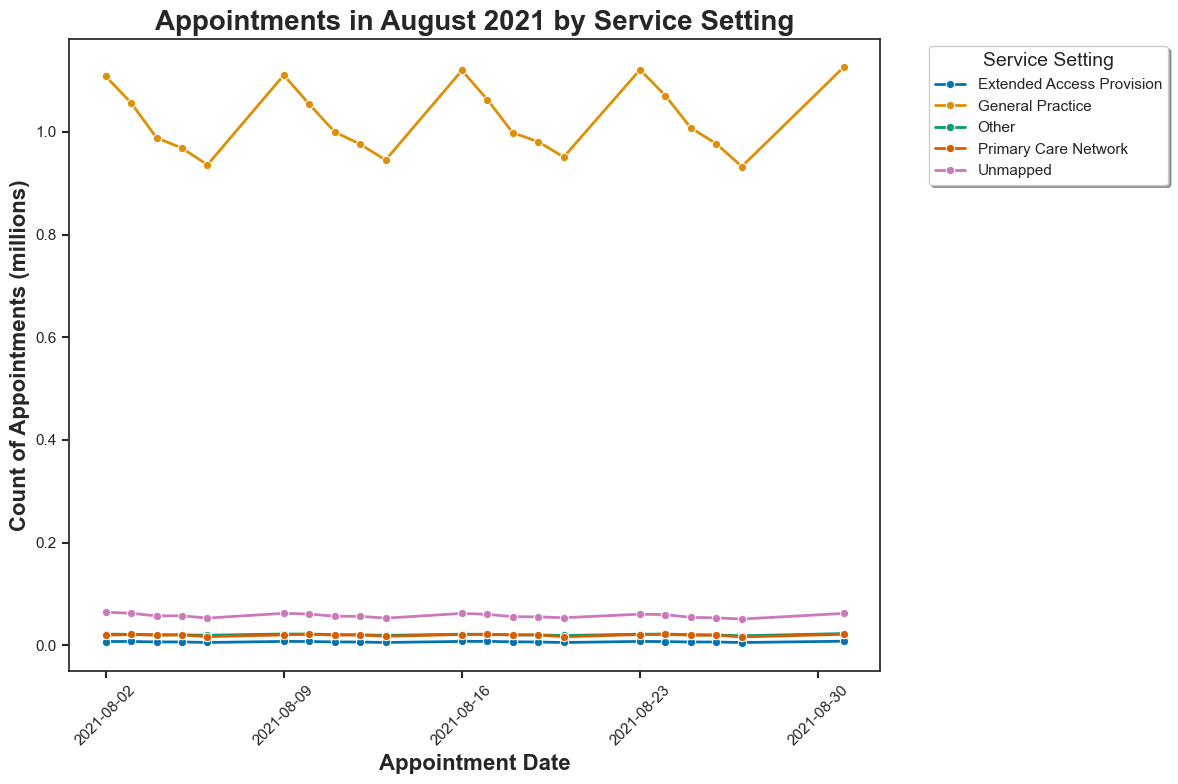

In [97]:
# Look at August 2021 in more detail to allow a closer look.

summer_2021['appointment_date'] = pd.to_datetime(summer_2021['appointment_date'])

# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(12,8)
# Plot data

sns.lineplot(x='appointment_date', y='count_millions', hue='service_setting',
             data= summer_2021,
            errorbar=None, linewidth=2, marker='o',
             palette='colorblind',ax=ax)

# Adding the weekly tick marks- Mondays with labels
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and labels
ax.set_title('Appointments in August 2021 by Service Setting', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Date', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot the figure
plt.tight_layout()  
plt.savefig('appointments_by_service_setting_August2021.png', dpi=300, bbox_inches='tight')
plt.show()

**Autumn (September to November 2021):**

In [98]:
# Look at September to November 2021 in more detail to allow a closer look.
nc_autumn2021= nc_copy[nc_copy['appointment_month'].isin(['2021-09', '2021-10', '2021-11'])]

nc_autumn2021

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
636,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,147,2021-09,0.000147
637,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,4,2021-09,0.000004
638,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,45,2021-09,0.000045
639,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,8,2021-09,0.000008
640,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,1,2021-09,0.000001
...,...,...,...,...,...,...,...,...,...
810945,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,131,2021-11,0.000131
810946,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Home Visit,1,2021-11,0.000001
810947,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,15,2021-11,0.000015
810948,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Acute,20,2021-11,0.000020


In [99]:
# Filter out business days in Autumn 2021
autumn_bdays= business_days('2021-09-01', '2021-11-30')
print(autumn_bdays)

['2021-09-01', '2021-09-02', '2021-09-03', '2021-09-06', '2021-09-07', '2021-09-08', '2021-09-09', '2021-09-10', '2021-09-13', '2021-09-14', '2021-09-15', '2021-09-16', '2021-09-17', '2021-09-20', '2021-09-21', '2021-09-22', '2021-09-23', '2021-09-24', '2021-09-27', '2021-09-28', '2021-09-29', '2021-09-30', '2021-10-01', '2021-10-04', '2021-10-05', '2021-10-06', '2021-10-07', '2021-10-08', '2021-10-11', '2021-10-12', '2021-10-13', '2021-10-14', '2021-10-15', '2021-10-18', '2021-10-19', '2021-10-20', '2021-10-21', '2021-10-22', '2021-10-25', '2021-10-26', '2021-10-27', '2021-10-28', '2021-10-29', '2021-11-01', '2021-11-02', '2021-11-03', '2021-11-04', '2021-11-05', '2021-11-08', '2021-11-09', '2021-11-10', '2021-11-11', '2021-11-12', '2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18', '2021-11-19', '2021-11-22', '2021-11-23', '2021-11-24', '2021-11-25', '2021-11-26', '2021-11-29', '2021-11-30']


In [100]:
# Use business_days as a filter
nc_autumn2021_sub= nc_autumn2021[nc_autumn2021['appointment_date'].isin(autumn_bdays)]

nc_autumn2021_sub

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
636,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,147,2021-09,0.000147
637,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,4,2021-09,0.000004
638,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,45,2021-09,0.000045
639,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,8,2021-09,0.000008
640,2021-09-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,1,2021-09,0.000001
...,...,...,...,...,...,...,...,...,...
810945,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,131,2021-11,0.000131
810946,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Home Visit,1,2021-11,0.000001
810947,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,15,2021-11,0.000015
810948,2021-11-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Acute,20,2021-11,0.000020


In [101]:
# Create a separate data set that can be used in future weeks. 
autumn_2021= nc_autumn2021_sub.groupby(['service_setting','appointment_date'])\
             [['count_millions']].sum().reset_index()

# View output.
autumn_2021     

,service_setting,appointment_date,count_millions
0,Extended Access Provision,2021-09-01,0.006916
1,Extended Access Provision,2021-09-02,0.007223
2,Extended Access Provision,2021-09-03,0.006324
3,Extended Access Provision,2021-09-06,0.008134
4,Extended Access Provision,2021-09-07,0.007862
...,...,...,...
320,Unmapped,2021-11-24,0.051408
321,Unmapped,2021-11-25,0.051381
322,Unmapped,2021-11-26,0.047964
323,Unmapped,2021-11-29,0.053797


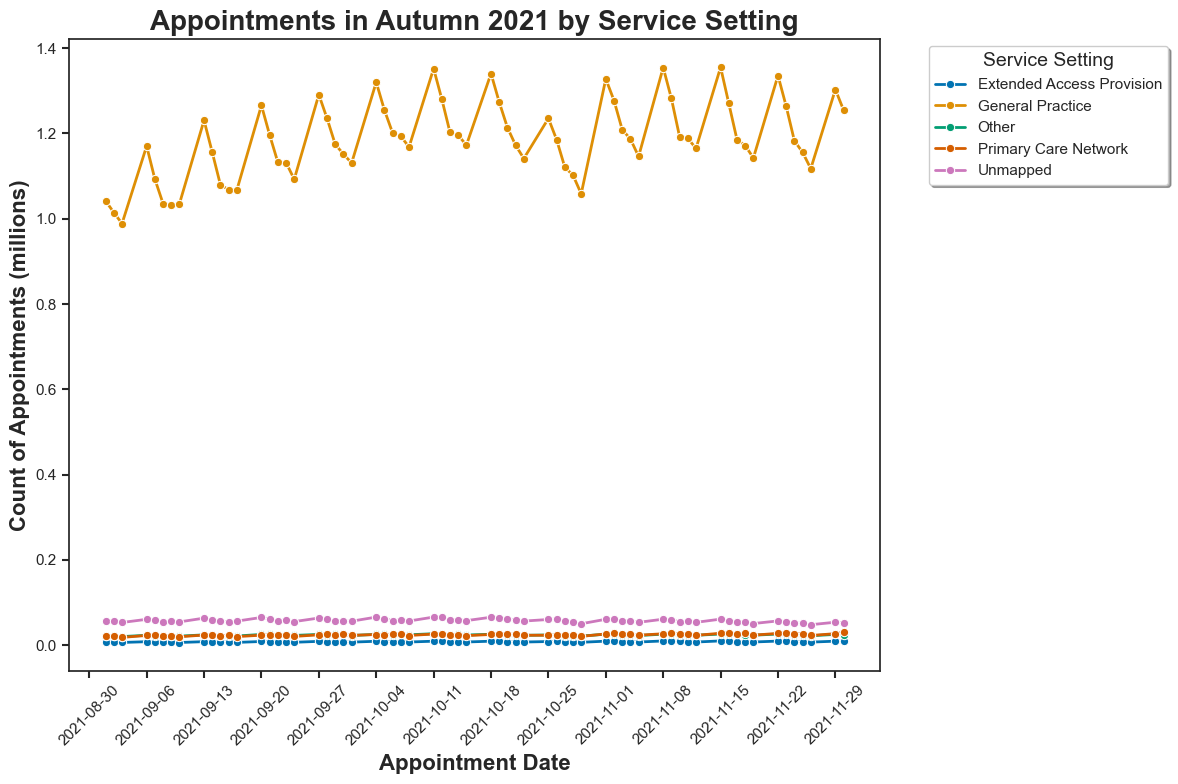

In [102]:
# Look at Sep to Nov 2021 in more detail to allow a closer look.
autumn_2021['appointment_date'] = pd.to_datetime(autumn_2021['appointment_date'])
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(12,8)
# Plot data

sns.lineplot(x='appointment_date', y='count_millions', hue='service_setting',
             data= autumn_2021,
            errorbar=None, linewidth=2, marker='o',
             palette='colorblind',ax=ax)

# Adding the weekly tick marks- Mondays with labels
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and labels
ax.set_title('Appointments in Autumn 2021 by Service Setting', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Date', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('appointments_by_service_setting_Autumn2021.png', dpi=300)
plt.show()

**Winter (December to February 2022):**

In [103]:
# Look at December 2021 to February 2022 in more detail to allow a closer look.
nc_winter2021= nc_copy[nc_copy['appointment_month'].isin(['2021-12', '2022-01', '2022-02'])]

nc_winter2021

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
2634,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,198,2021-12,0.000198
2635,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,5,2021-12,0.000005
2636,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,52,2021-12,0.000052
2637,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,27,2021-12,0.000027
2638,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,30,2021-12,0.000030
...,...,...,...,...,...,...,...,...,...
813632,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-02,0.000004
813633,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,81,2022-02,0.000081
813634,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,14,2022-02,0.000014
813635,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Acute,28,2022-02,0.000028


In [104]:
# Filter out business days in Winter 
winter_bdays= business_days('2021-12-01', '2022-02-28')
print(winter_bdays)

['2021-12-01', '2021-12-02', '2021-12-03', '2021-12-06', '2021-12-07', '2021-12-08', '2021-12-09', '2021-12-10', '2021-12-13', '2021-12-14', '2021-12-15', '2021-12-16', '2021-12-17', '2021-12-20', '2021-12-21', '2021-12-22', '2021-12-23', '2021-12-24', '2021-12-29', '2021-12-30', '2021-12-31', '2022-01-04', '2022-01-05', '2022-01-06', '2022-01-07', '2022-01-10', '2022-01-11', '2022-01-12', '2022-01-13', '2022-01-14', '2022-01-17', '2022-01-18', '2022-01-19', '2022-01-20', '2022-01-21', '2022-01-24', '2022-01-25', '2022-01-26', '2022-01-27', '2022-01-28', '2022-01-31', '2022-02-01', '2022-02-02', '2022-02-03', '2022-02-04', '2022-02-07', '2022-02-08', '2022-02-09', '2022-02-10', '2022-02-11', '2022-02-14', '2022-02-15', '2022-02-16', '2022-02-17', '2022-02-18', '2022-02-21', '2022-02-22', '2022-02-23', '2022-02-24', '2022-02-25', '2022-02-28']


In [105]:
# Use business_days as a filter
nc_winter2021_sub= nc_winter2021[nc_winter2021['appointment_date'].isin(winter_bdays)]

nc_winter2021_sub

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
2634,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,198,2021-12,0.000198
2635,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,5,2021-12,0.000005
2636,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,52,2021-12,0.000052
2637,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,27,2021-12,0.000027
2638,2021-12-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,30,2021-12,0.000030
...,...,...,...,...,...,...,...,...,...
813632,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-02,0.000004
813633,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,81,2022-02,0.000081
813634,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,14,2022-02,0.000014
813635,2022-02-28,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Acute,28,2022-02,0.000028


In [106]:
# Create a separate data set that can be used in future weeks. 
winter_2021= nc_winter2021_sub.groupby(['service_setting','appointment_date'])\
             [['count_millions']].sum().reset_index()

# View output.
winter_2021     

,service_setting,appointment_date,count_millions
0,Extended Access Provision,2021-12-01,0.008500
1,Extended Access Provision,2021-12-02,0.008023
2,Extended Access Provision,2021-12-03,0.007073
3,Extended Access Provision,2021-12-06,0.009632
4,Extended Access Provision,2021-12-07,0.009235
...,...,...,...
300,Unmapped,2022-02-22,0.040670
301,Unmapped,2022-02-23,0.037250
302,Unmapped,2022-02-24,0.038609
303,Unmapped,2022-02-25,0.035465


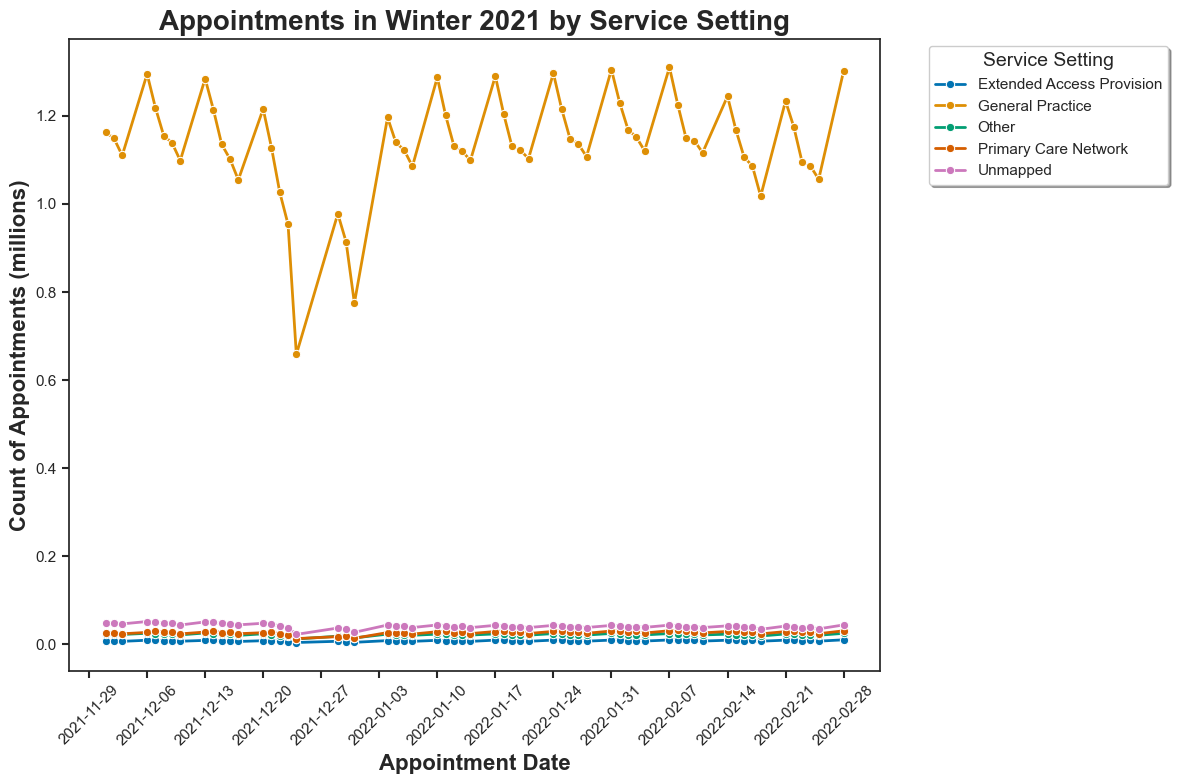

In [107]:
# Look at December to February 2022 in more detail to allow a closer look.
winter_2021['appointment_date']= pd.to_datetime(winter_2021['appointment_date'])
# Create a lineplot.

fig, ax = plt.subplots()
fig.set_size_inches(12,8)
# Plot data

sns.lineplot(x='appointment_date', y='count_millions', hue='service_setting',
             data= winter_2021,
            errorbar=None, linewidth=2, marker='o',
             palette='colorblind',ax=ax)

# Adding the weekly tick marks- Mondays with labels
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and label
ax.set_title('Appointments in Winter 2021 by Service Setting', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Date', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('appointments_by_service_setting_Winter 2021.png', dpi=300)
plt.show()

**Spring (March to May 2022):**

In [108]:
nc_spring2022= nc_copy[nc_copy['appointment_month'].isin(['2022-03', '2022-04', '2022-05'])]

nc_spring2022

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
4454,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,156,2022-03,0.000156
4455,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Inconsistent Mapping,Inconsistent Mapping,7,2022-03,0.000007
4456,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,19,2022-03,0.000019
4457,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Social Prescribing Service,15,2022-03,0.000015
4458,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,83,2022-03,0.000083
...,...,...,...,...,...,...,...,...,...
816466,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,General Consultation Routine,177,2022-05,0.000177
816467,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Planned Clinical Procedure,503,2022-05,0.000503
816468,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Care Home Needs Assessment & Personalised Care...,19,2022-05,0.000019
816469,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Clinical Triage,547,2022-05,0.000547


In [109]:
# Filter out business days in Winter 
spring_bdays= business_days('2022-03-01', '2022-05-31')
print(spring_bdays)

['2022-03-01', '2022-03-02', '2022-03-03', '2022-03-04', '2022-03-07', '2022-03-08', '2022-03-09', '2022-03-10', '2022-03-11', '2022-03-14', '2022-03-15', '2022-03-16', '2022-03-17', '2022-03-18', '2022-03-21', '2022-03-22', '2022-03-23', '2022-03-24', '2022-03-25', '2022-03-28', '2022-03-29', '2022-03-30', '2022-03-31', '2022-04-01', '2022-04-04', '2022-04-05', '2022-04-06', '2022-04-07', '2022-04-08', '2022-04-11', '2022-04-12', '2022-04-13', '2022-04-14', '2022-04-19', '2022-04-20', '2022-04-21', '2022-04-22', '2022-04-25', '2022-04-26', '2022-04-27', '2022-04-28', '2022-04-29', '2022-05-03', '2022-05-04', '2022-05-05', '2022-05-06', '2022-05-09', '2022-05-10', '2022-05-11', '2022-05-12', '2022-05-13', '2022-05-16', '2022-05-17', '2022-05-18', '2022-05-19', '2022-05-20', '2022-05-23', '2022-05-24', '2022-05-25', '2022-05-26', '2022-05-27', '2022-05-30', '2022-05-31']


In [110]:
# Use business_days as a filter
nc_spring2022_sub= nc_spring2022[nc_spring2022['appointment_date'].isin(spring_bdays)]

nc_spring2022_sub

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
4454,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Unmapped,Unmapped,Unmapped,156,2022-03,0.000156
4455,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Inconsistent Mapping,Inconsistent Mapping,7,2022-03,0.000007
4456,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Structured Medication Review,19,2022-03,0.000019
4457,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Social Prescribing Service,15,2022-03,0.000015
4458,2022-03-01,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Planned Clinics,83,2022-03,0.000083
...,...,...,...,...,...,...,...,...,...
816466,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,Primary Care Network,Care Related Encounter,General Consultation Routine,177,2022-05,0.000177
816467,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Planned Clinical Procedure,503,2022-05,0.000503
816468,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Care Home Needs Assessment & Personalised Care...,19,2022-05,0.000019
816469,2022-05-31,E54000054,NHS West Yorkshire ICB - X2C4Y,General Practice,Care Related Encounter,Clinical Triage,547,2022-05,0.000547


In [111]:
# Create a separate data set that can be used in future weeks. 
spring_2022= nc_spring2022_sub.groupby(['service_setting','appointment_date'])\
             [['count_millions']].sum().reset_index()

# View output.
spring_2022  

,service_setting,appointment_date,count_millions
0,Extended Access Provision,2022-03-01,0.010082
1,Extended Access Provision,2022-03-02,0.009660
2,Extended Access Provision,2022-03-03,0.009384
3,Extended Access Provision,2022-03-04,0.008007
4,Extended Access Provision,2022-03-07,0.010287
...,...,...,...
310,Unmapped,2022-05-25,0.037001
311,Unmapped,2022-05-26,0.037335
312,Unmapped,2022-05-27,0.034713
313,Unmapped,2022-05-30,0.038040


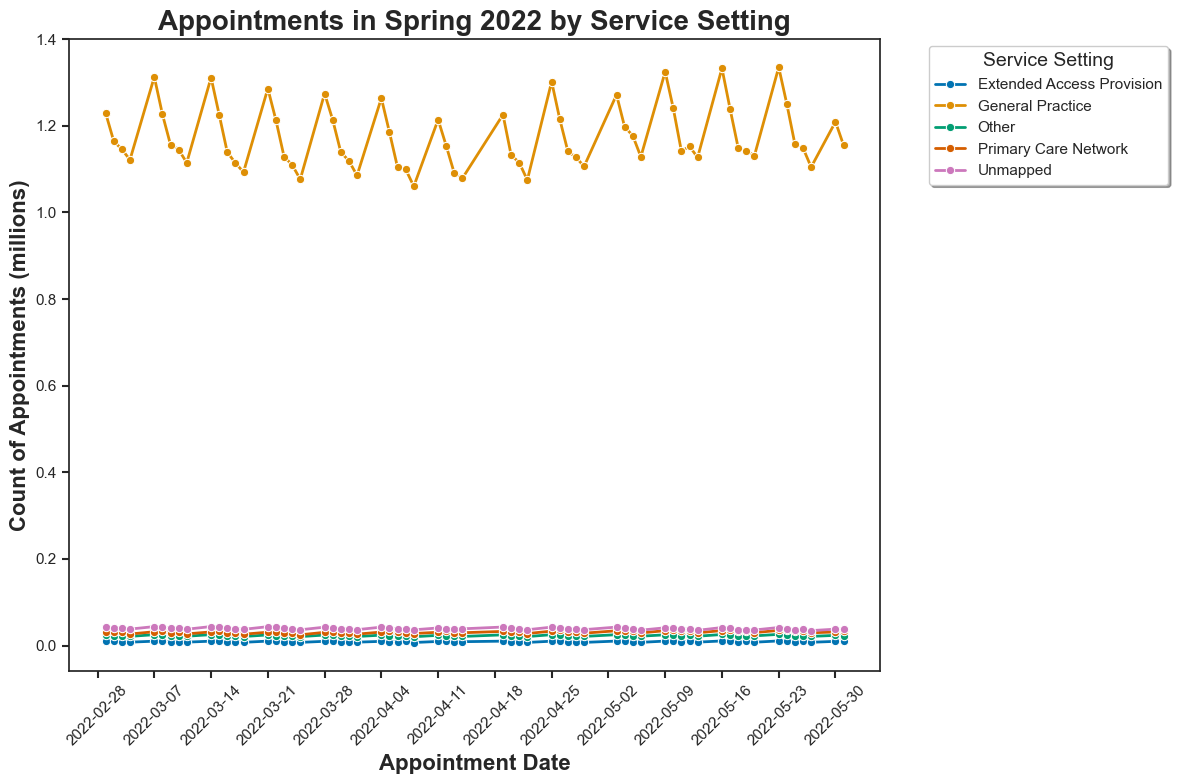

In [112]:
# Look at March to May 2022 in more detail to allow a closer look.
spring_2022['appointment_date']= pd.to_datetime(spring_2022['appointment_date'])
# Create a lineplot.

fig, ax = plt.subplots()
fig.set_size_inches(12,8)
# Plot data

sns.lineplot(x='appointment_date', y='count_millions', hue='service_setting',
             data= spring_2022,
            errorbar=None, linewidth=2, marker='o',
             palette='colorblind',ax=ax)

# Adding the weekly tick marks- Mondays with labels
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and label
ax.set_title('Appointments in Spring 2022 by Service Setting', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Date', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot the figure
plt.tight_layout() 
plt.savefig('appointments_by_service_setting_Spring_2022.png', dpi=300)
plt.show()

# 5. Social media (Twitter/X) analysis

### Analyse tweets from Twitter with hashtags related to healthcare in the UK.

In [113]:
# Libraries and settings needed for analysis
import pandas as pd
import seaborn as sns

# Set figure size.
sns.set(rc={'figure.figsize':(15, 12)})

# Set the plot style as white.
sns.set_style('white')

# Maximum column width to display
pd.options.display.max_colwidth = 200

In [114]:
# Load the data set.
tweets = pd.read_csv('tweets.csv')

# View the DataFrame.
tweets.head()

,tweet_id,tweet_full_text,tweet_entities,tweet_entities_hashtags,tweet_metadata,tweet_retweet_count,tweet_favorite_count,tweet_favorited,tweet_retweeted,tweet_lang
0,1567629223795527681,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...","{'hashtags': [{'text': 'Healthcare', 'indices': [253, 264]}], 'symbols': [], 'user_mentions': [], 'urls': [{'url': 'https://t.co/yw0cstfmSI', 'expanded_url': 'https://bit.ly/3BiSKbs', 'display_url...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en
1,1567582846612553728,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…,"{'hashtags': [{'text': 'PremiseHealth', 'indices': [94, 108]}, {'text': 'hiring', 'indices': [127, 134]}], 'symbols': [], 'user_mentions': [{'screen_name': 'AndreaGrammer', 'name': 'Andrea Grammer...","#PremiseHealth, #hiring","{'iso_language_code': 'en', 'result_type': 'recent'}",2,0,False,False,en
2,1567582787070304256,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…,"{'hashtags': [{'text': 'Healthcare', 'indices': [70, 81]}], 'symbols': [], 'user_mentions': [{'screen_name': 'OntarioGreens', 'name': 'Green Party of Ontario', 'id': 37115912, 'id_str': '37115912'...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",39,0,False,False,en
3,1567582767625428992,RT @modrnhealthcr: 🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data…,"{'hashtags': [{'text': 'NEW', 'indices': [20, 24]}], 'symbols': [], 'user_mentions': [{'screen_name': 'modrnhealthcr', 'name': 'Modern Healthcare', 'id': 18935711, 'id_str': '18935711', 'indices':...",#NEW,"{'iso_language_code': 'en', 'result_type': 'recent'}",5,0,False,False,en
4,1567582720460570625,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di...","{'hashtags': [{'text': 'blogs', 'indices': [184, 190]}, {'text': 'digitaltransformation', 'indices': [191, 213]}, {'text': 'cybersecurity', 'indices': [214, 228]}, {'text': 'accounting', 'indices'...","#blogs, #digitaltransformation, #cybersecurity, #accounting, #finance, #healthcare","{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en


In [115]:
# Explore the metadata.
tweets.describe()
tweets.info()
tweets.columns.tolist()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1174 entries, 0 to 1173
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   tweet_id                 1174 non-null   int64 
 1   tweet_full_text          1174 non-null   object
 2   tweet_entities           1174 non-null   object
 3   tweet_entities_hashtags  1007 non-null   object
 4   tweet_metadata           1174 non-null   object
 5   tweet_retweet_count      1174 non-null   int64 
 6   tweet_favorite_count     1174 non-null   int64 
 7   tweet_favorited          1174 non-null   bool  
 8   tweet_retweeted          1174 non-null   bool  
 9   tweet_lang               1174 non-null   object
dtypes: bool(2), int64(3), object(5)
memory usage: 75.8+ KB


['tweet_id',
 'tweet_full_text',
 'tweet_entities',
 'tweet_entities_hashtags',
 'tweet_metadata',
 'tweet_retweet_count',
 'tweet_favorite_count',
 'tweet_favorited',
 'tweet_retweeted',
 'tweet_lang']

In [116]:
# Explore the data set.
tweets['tweet_retweet_count'].value_counts(ascending=False)

tweet_retweet_count
0      526
1      215
2      114
3       70
5       35
4       27
7       18
12      16
8       15
73      14
9       13
6       12
208     12
35      10
37       6
11       6
10       5
53       5
44       4
150      4
63       4
76       3
85       3
41       3
62       3
207      3
68       3
78       2
23       2
24       2
72       2
16       2
13       1
49       1
48       1
15       1
107      1
14       1
79       1
20       1
39       1
19       1
303      1
57       1
40       1
54       1
169      1
Name: count, dtype: int64

In [117]:
# Explore the data set.
tweets['tweet_favorite_count'].value_counts(ascending=False)

tweet_favorite_count
0     1027
1       91
2       16
3       13
4        7
5        5
6        2
17       1
12       1
10       1
8        1
13       1
11       1
7        1
20       1
28       1
14       1
18       1
9        1
42       1
Name: count, dtype: int64

### Would it be useful to only look at retweeted and favourite tweet messages?

On social media, retweet and favorite counts can also be used as indicators of whether a post receives positive feedback or whether others agree with it by showing interest.

However, in this case, I will need to dig deeper, as looking only at retweet and favorite counts might not show the full picture because:

- The majority of posts receive fewer than 5 reactions (either retweets or favorites): this may be due to various reasons, such as not everyone using X to share their ideas and the post not reaching many people.
- I need to understand and identify trends in people's tweets: what are the major problems with regard to the NHS, and are there any common themes among posts that receive more reactions?
- As reactions on X are quite limited compared to other social platforms, is it really worth sourcing the data from X? Would it be better to look at data from other platforms where public reactions are more active?

In [118]:
# Create a new DataFrame containing only the text.
tweets_text = tweets['tweet_full_text']

# View the DataFrame.
tweets_text

0       As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...
1                                                                   RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed.  We're #hiring for…
2                                                                RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…
3                                                                  RT @modrnhealthcr: 🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data…
4       ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a gr

In [119]:
# Loop through the messages, and create a list of values containing the # symbol.
tags = []

for y in [x.split(' ') for x in tweets['tweet_full_text'].values]:
    for z in y:
        if '#' in z:
            # Change to lowercase.
            tags.append(z.lower())

In [120]:
# Display the first 30 records.
pd.Series(tags).value_counts().head(30)

#healthcare                    716
#health                         80
#medicine                       41
#ai                             40
#job                            38
#medical                        35
#strategy                       30
#pharmaceutical                 28
#digitalhealth                  25
#pharma                         25
#marketing                      25
#medtwitter                     24
#biotech                        24
#competitiveintelligence        24
#meded                          23
#vaccine                        18
#hiring                         18
#news                           17
#machinelearning                17
#technology                     17
#coronavirus                    16
#womeninmedicine                16
#covid                          16
#competitivemarketing           16
#wellness                       15
#healthtech                     15
#doctorofveterinarymedicine     14
#science                        14
#medicare           

In [121]:
# Convert the series to a DataFrame in preparation for visualisation.
tweets_hashtag = pd.Series(tags).value_counts().to_frame().reset_index()

# Rename the columns.
tweets_hashtag.columns=['word','count']
tweets_hashtag

,word,count
0,#healthcare,716
1,#health,80
2,#medicine,41
3,#ai,40
4,#job,38
...,...,...
1749,#evestudy,1
1750,#patientdata…,1
1751,#secure,1
1752,#sms,1


In [122]:
# Explore the metadata

tweets_hashtag.shape
tweets_hashtag.describe()
tweets_hashtag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   word    1754 non-null   object
 1   count   1754 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 27.5+ KB


In [123]:
# Display records where the count is larger than 10.
# Create a new DataFrame with all counts record > 10
filtered_tweets_hashtag = tweets_hashtag[tweets_hashtag['count'] >=10]

# View the DataFrame

filtered_tweets_hashtag
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(filtered_tweets_hashtag)

,word,count
0,#healthcare,716
1,#health,80
2,#medicine,41
3,#ai,40
4,#job,38
5,#medical,35
6,#strategy,30
7,#pharmaceutical,28
8,#digitalhealth,25
9,#pharma,25


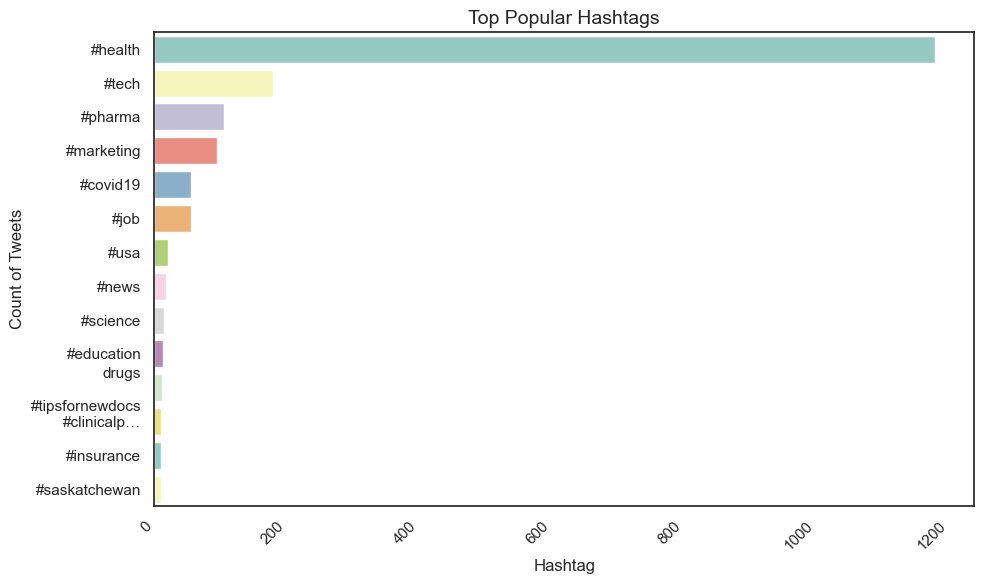

In [220]:
# Create a Seaborn barplot indicating records with a count >10 records.
plt.figure(figsize=(10, 6))
sns.barplot(x='count', y='word', 
            data=filtered_tweets_hashtag, palette='Set3')

plt.title('Top Popular Hashtags', fontsize=14)
plt.xlabel('Hashtag', fontsize=12)
plt.ylabel('Count of Tweets', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('top_popular_hastag_crowded.png', dpi=300)
plt.show()

#### Improvement needs to be made to the charts:

- remove any overpresented hashtags: thinking of reducing the amount of hashtag by combining them into 1 category: for example: any hashtag including health or healthcare should be combined into 1 category only.
- after refining the hashtags categories, create new plot to understand the hashtag trend better

In [125]:
def group_hashtags(tag):
    if any(x in tag for x in ['health', 'medical', 'medicine', 'doctor', 
                                'nurse', 'nursing', 'hospital', 'patient',
                                'wellness', 'telehealth', 'telemedicine',
                                'meded', 'medtwitter', 'foamed','#medicare']):
        return '#health'
    
    elif any(x in tag for x in ['covid', 'coronavirus', 'pandemic']):
        return '#covid19'
    
    elif any(x in tag for x in ['pharma', 'pharmaceutical', 'biotech', 'vaccine']):
        return '#pharma'
    
    elif any(x in tag for x in ['tech', 'ai', 'machinelearning', 'digital',
                                  'data', 'rstats', 'html', 'nodejs',
                                  '100daysofmlcode', '#python','innovation']):
        return '#tech'
    
    elif any(x in tag for x in ['marketing', 'strategy', 'competitive']):
        return '#marketing'
    
    elif any(x in tag for x in ['job', 'hiring', 'career']):
        return '#job'
    elif any(x in tag for x in ['usa', 'chicago']):
        return '#usa'
    else:
        return tag  # keep original if no match

# Apply the function
filtered_tweets_hashtag['word'] = filtered_tweets_hashtag['word'].apply(group_hashtags)

# Regroup and sum counts
filtered_tweets_hashtag= filtered_tweets_hashtag.groupby('word')['count'].sum().reset_index()

# Sort by most frequent
filtered_tweets_hashtag = filtered_tweets_hashtag.sort_values('count', ascending=False).reset_index(drop=True)

filtered_tweets_hashtag

,word,count
0,#health,1180
1,#tech,179
2,#pharma,105
3,#marketing,95
4,#covid19,56
5,#job,56
6,#usa,21
7,#news,17
8,#science,14
9,#education,13


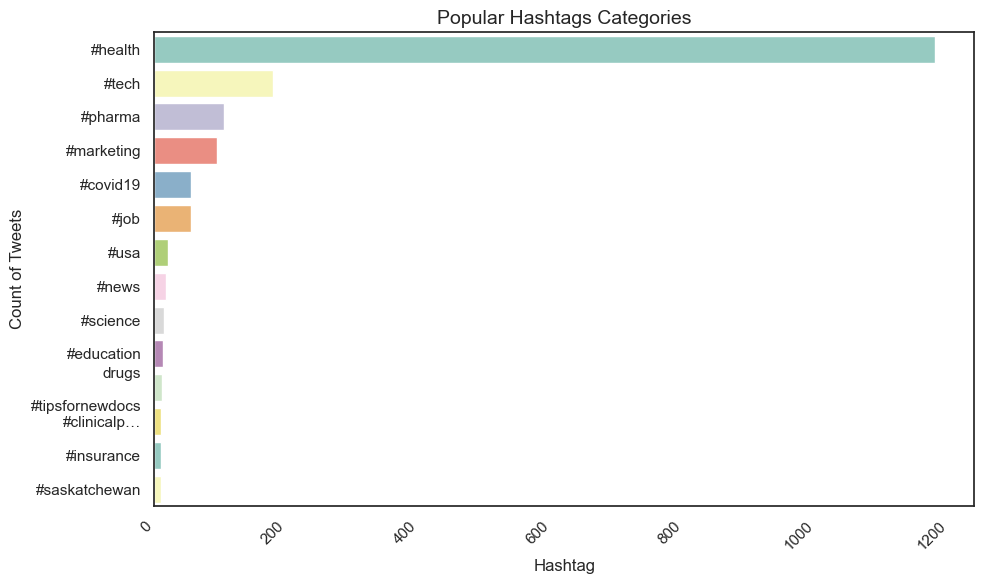

In [126]:
# Plot new barplot using new filtered DataFrame

plt.figure(figsize=(10, 6))
sns.barplot(x='count', y='word', 
            data=filtered_tweets_hashtag, palette='Set3')

plt.title('Popular Hashtags Categories', fontsize=14)
plt.xlabel('Hashtag', fontsize=12)
plt.ylabel('Count of Tweets', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### For better comparison
2 bar charts for comparing top 15 popular hashtags and popular hashtags categories

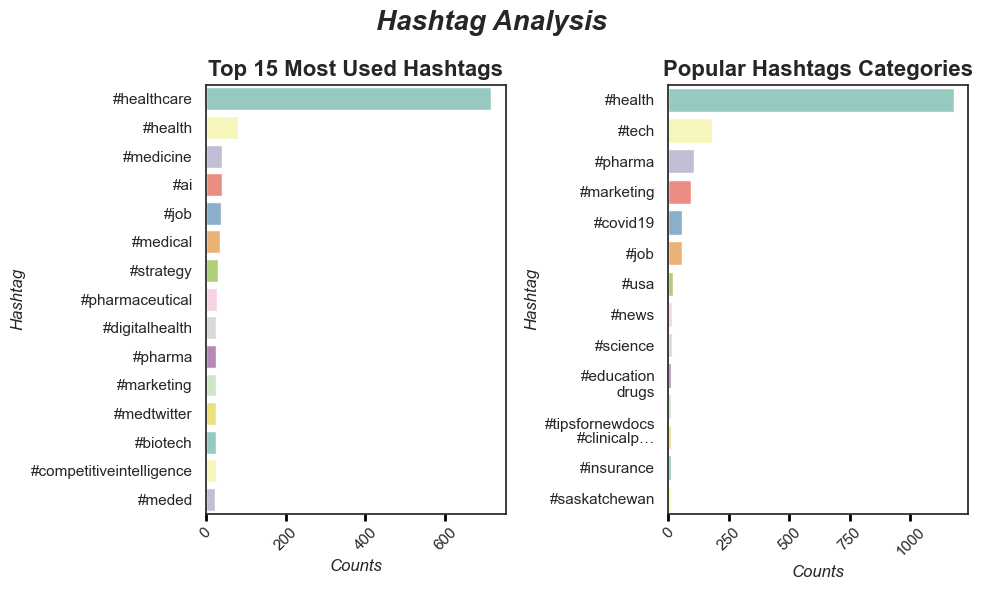

In [127]:
# Create the plot.

top_hashtags = tweets_hashtag.head(15)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)

# Bar chart - top 15 popular hashtags
sns.barplot(x='count', y='word', data=top_hashtags, 
            palette='Set3', ax=axes[0])
axes[0].set_title('Top 15 Most Used Hashtags', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Counts', fontsize=12, fontstyle='italic')
axes[0].set_ylabel('Hashtag', fontsize=12, fontstyle='italic')
axes[0].tick_params(axis='x', rotation=45, length=5, width=2,
                   bottom=True, color='black')

# Plot the data
sns.barplot(x='count', y='word', data=filtered_tweets_hashtag, 
            palette='Set3', ax=axes[1])
axes[1].set_title('Popular Hashtags Categories', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Counts', fontsize=12, fontstyle='italic')
axes[1].set_ylabel('Hashtag', fontsize=12,fontstyle='italic')
axes[1].tick_params(axis='x', rotation=45, which='major', length=5, width=2, 
                    bottom=True,color='black')

plt.suptitle('Hashtag Analysis', fontsize=20, fontweight='bold',fontstyle='italic', x=0.5)
plt.tight_layout()
# View the barplot.
plt.savefig('Hashtag Analysis.png', dpi=300)
plt.show()

### Dig deeper in extracting more insights from tweets text

In [128]:
%pip install textblob

In [129]:
tweets_copy = tweets
tweets_copy

,tweet_id,tweet_full_text,tweet_entities,tweet_entities_hashtags,tweet_metadata,tweet_retweet_count,tweet_favorite_count,tweet_favorited,tweet_retweeted,tweet_lang
0,1567629223795527681,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...","{'hashtags': [{'text': 'Healthcare', 'indices': [253, 264]}], 'symbols': [], 'user_mentions': [], 'urls': [{'url': 'https://t.co/yw0cstfmSI', 'expanded_url': 'https://bit.ly/3BiSKbs', 'display_url...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en
1,1567582846612553728,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…,"{'hashtags': [{'text': 'PremiseHealth', 'indices': [94, 108]}, {'text': 'hiring', 'indices': [127, 134]}], 'symbols': [], 'user_mentions': [{'screen_name': 'AndreaGrammer', 'name': 'Andrea Grammer...","#PremiseHealth, #hiring","{'iso_language_code': 'en', 'result_type': 'recent'}",2,0,False,False,en
2,1567582787070304256,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…,"{'hashtags': [{'text': 'Healthcare', 'indices': [70, 81]}], 'symbols': [], 'user_mentions': [{'screen_name': 'OntarioGreens', 'name': 'Green Party of Ontario', 'id': 37115912, 'id_str': '37115912'...",#Healthcare,"{'iso_language_code': 'en', 'result_type': 'recent'}",39,0,False,False,en
3,1567582767625428992,RT @modrnhealthcr: 🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data…,"{'hashtags': [{'text': 'NEW', 'indices': [20, 24]}], 'symbols': [], 'user_mentions': [{'screen_name': 'modrnhealthcr', 'name': 'Modern Healthcare', 'id': 18935711, 'id_str': '18935711', 'indices':...",#NEW,"{'iso_language_code': 'en', 'result_type': 'recent'}",5,0,False,False,en
4,1567582720460570625,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di...","{'hashtags': [{'text': 'blogs', 'indices': [184, 190]}, {'text': 'digitaltransformation', 'indices': [191, 213]}, {'text': 'cybersecurity', 'indices': [214, 228]}, {'text': 'accounting', 'indices'...","#blogs, #digitaltransformation, #cybersecurity, #accounting, #finance, #healthcare","{'iso_language_code': 'en', 'result_type': 'recent'}",0,0,False,False,en
...,...,...,...,...,...,...,...,...,...,...
1169,1567583004209332227,RT @PotomacPhotonic: Potomac #Innovation Report: #precisionFabrication techniques Optimize #Microfluidic Mixing of Viscous Fluids \n\n#manuf…,"{'hashtags': [{'text': 'Innovation', 'indices': [29, 40]}, {'text': 'precisionFabrication', 'indices': [50, 71]}, {'text': 'Microfluidic', 'indices': [92, 105]}], 'symbols': [], 'user_mentions': [...","#Innovation, #precisionFabrication, #Microfluidic","{'iso_language_code': 'en', 'result_type': 'recent'}",1,0,False,False,en
1170,1567582945342267393,"Not a cent towards workers who would like to advance their training, especially those already employed by SHA or who for various reasons cannot obtain a student loan. Half of our department applie...","{'hashtags': [{'text': 'SKPoli', 'indices': [232, 239]}, {'text': 'healthcare', 'indices': [240, 251]}], 'symbols': [], 'user_mentions': [], 'urls': [{'url': 'https://t.co/33f7Dz5FrU', 'expanded_u...","#SKPoli, #healthcare","{'iso_language_code': 'en', 'result_type': 'recent'}",0,1,False,False,en
1171,1567582936014241792,"The @hfmaorg Region 9 presents ""The Value of ESG to the Healthcare Industry"" and our own Kris Russell and Ron Present will be the key speakers. This #webinar will be taking place 9/13 and will exp...","{'hashtags': [{'text': 'webinar', 'indices': [149, 157]}, {'text': 'ESG', 'indices'

#### Seek for insights regarding how people react to healthcare in general

In [130]:
# Finding how people feel about healthcare
# Using sentiment_assessments:
from textblob import TextBlob

def get_textblob_sentiment(text):
    blob = TextBlob(str(text))
    return pd.Series([blob.sentiment.polarity, blob.sentiment.subjectivity])

# Apply the function and create two new columns
tweets_copy[['polarity', 'subjectivity']] = tweets_copy['tweet_full_text'].apply(get_textblob_sentiment)

# 2. Print the improved summary metrics
print("=== HEALTHCARE SENTIMENT REPORT ===")
print(f'Average Polarity (Tone):     {tweets_copy["polarity"].mean():.2f}')
print(f'Most Positive Tweet Score:   {tweets_copy["polarity"].max():.2f}')
print(f'Most Negative Tweet Score:   {tweets_copy["polarity"].min():.2f}') 
print("-" * 35)
print(f'Average Subjectivity (Bias): {tweets_copy["subjectivity"].mean():.2f}')

# Get insights by combining both metrics
print("\n=== DEEPER INSIGHTS ===")

# Factual/Objective complaints (e.g., policy updates, systemic issues, wait times)
factual_negative = tweets_copy[(tweets_copy['polarity'] < -0.1) & (tweets_copy['subjectivity'] < 0.3)]
print(f"Number of factual/objective complaints: {len(factual_negative)}")

# Emotional opinions (e.g., personal stories, rants, high praise)
emotional_tweets = tweets_copy[tweets_copy['subjectivity'] > 0.6]
print(f"Number of highly emotional/personal opinions: {len(emotional_tweets)}")

=== HEALTHCARE SENTIMENT REPORT ===
Average Polarity (Tone):     0.17
Most Positive Tweet Score:   1.00
Most Negative Tweet Score:   -0.94
-----------------------------------
Average Subjectivity (Bias): 0.33

=== DEEPER INSIGHTS ===
Number of factual/objective complaints: 13
Number of highly emotional/personal opinions: 208


In [131]:
# Filter by health-related hashtags
health_keywords = ['health', 'healthcare', 'hospital', 'medical', 
                    'medicine', 'digitalhealth', 'healthtech',
                   'doctor', 'nurse', 'nursing', 'hospital', 'patient',
                    'wellness', 'telehealth', 'telemedicine',
                    'meded', 'medtwitter', 'foamed','medicare']

# Creating a Dataframe that was filtered by using health-related hashtags
health_tweets= tweets_copy[
    tweets_copy['tweet_entities_hashtags'].str.lower().str.contains(
        '|'.join(health_keywords), na=False)]

# View the DataFrame with specific columns

health_tweets[['tweet_full_text', 'tweet_entities_hashtags','polarity', 'subjectivity']].head(10)

,tweet_full_text,tweet_entities_hashtags,polarity,subjectivity
0,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...",#Healthcare,0.210000,0.306667
1,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…,"#PremiseHealth, #hiring",0.000000,0.000000
2,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…,#Healthcare,-0.225000,0.400000
4,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di...","#blogs, #digitaltransformation, #cybersecurity, #accounting, #finance, #healthcare",0.333333,0.333333
5,"Nursing interventions can be independent, dependent, or collaborative.\n-----\nLearn more: 👉 https://t.co/jrGQeqDme4\n.\n#firstcoastcna #cnaexam #cnaexampreparation #jacksonville #cnatraining #nur...","#firstcoastcna, #cnaexam, #cnaexampreparation, #jacksonville, #cnatraining, #nurse, #nursing, #nurselife, #nursepractitioner, #nurseproblems, #nursingschool, #healthcare",0.250000,0.312500
6,🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data as focus intensifies on addressing #disparities. h/t @JessicaKimCohen &amp;...,"#NEW, #disparities, #healthcare, #alert, #insurance, #data",1.000000,0.300000
7,"Now, more than ever, we need to focus on strengthening our global #Healthcare systems. 2/2",#Healthcare,0.250000,0.250000
8,"RT @AlikaMD: Our nat’l choices re: #healthcare systems aren’t the continuum of public or private, but how much we want of:\n\n- fragmented or…",#healthcare,0.066667,0.213889
9,You ready for $JCO @_JennyCo ❤️\n\n#Healthcare data powered by @Conste11ation $DAG 🔥,#Healthcare,0.200000,0.500000
10,Big news in #healthcare for sure. The road ahead is a long one and approaching this by signing a 10-year collaboration is the right move. #hcldr https://t.co/Z9NFQ1wBor,"#healthcare, #hcldr",0.147143,0.384921


In [132]:
# Create a define function that will categorize into different polarity sentiment segments.
def polarity(score):
    if score > 0.05:
        return 'Positive'
    elif score < -0.05:
        return 'Negative'
    else:
        return 'Neutral'
        
# Create a define function that will categorize into different subjectivity sentiments segments:
def subjectivity(score):
    if score > 0.05:
        return 'Subjective'
    else:
        return 'Objective'
        

health_tweets['polarity_label'] = health_tweets['polarity'].apply(polarity)
health_tweets['subjectivity_label'] = health_tweets['subjectivity'].apply(subjectivity)

health_tweets[['tweet_full_text', 'tweet_entities_hashtags', 'polarity', 'subjectivity', 'polarity_label', 'subjectivity_label']]

,tweet_full_text,tweet_entities_hashtags,polarity,subjectivity,polarity_label,subjectivity_label
0,"As Arkansas’ first Comprehensive Stroke Certified Center, UAMS provides Arkansans with access to the most advanced stoke care. Join us in our mission to make a difference in the health and well-be...",#Healthcare,0.210000,0.306667,Positive,Subjective
1,RT @AndreaGrammer: Work-life balance is at the foundation of how decisions are made and where #PremiseHealth is headed. We're #hiring for…,"#PremiseHealth, #hiring",0.000000,0.000000,Neutral,Objective
2,RT @OntarioGreens: $10 billion can go a long way to fixing our broken #Healthcare system.\n\nYet Doug Ford would rather spend it ALL on a hig…,#Healthcare,-0.225000,0.400000,Negative,Subjective
4,"ICYMI: Our recent blogs on Cybersecurity in Accounting https://t.co/4nnK0FiVVL and Digital Transformation in Healthcare Finance https://t.co/jIqn52lHD3 are a great read, take a look!\n\n#blogs #di...","#blogs, #digitaltransformation, #cybersecurity, #accounting, #finance, #healthcare",0.333333,0.333333,Positive,Subjective
5,"Nursing interventions can be independent, dependent, or collaborative.\n-----\nLearn more: 👉 https://t.co/jrGQeqDme4\n.\n#firstcoastcna #cnaexam #cnaexampreparation #jacksonville #cnatraining #nur...","#firstcoastcna, #cnaexam, #cnaexampreparation, #jacksonville, #cnatraining, #nurse, #nursing, #nurselife, #nursepractitioner, #nurseproblems, #nursingschool, #healthcare",0.250000,0.312500,Positive,Subjective
...,...,...,...,...,...,...
1167,@mkecounty Mental Health Emergency Center (24/7/365) officially opened in @cityofmilwaukee. This is a beautiful example of #healthcare systems coming together &amp; committed to achieving #health...,"#healthcare, #healthequity",0.216667,0.433333,Positive,Subjective
1170,"Not a cent towards workers who would like to advance their training, especially those already employed by SHA or who for various reasons cannot obtain a student loan. Half of our department applie...","#SKPoli, #healthcare",-0.041667,0.516667,Neutral,Subjective
1171,"The @hfmaorg Region 9 presents ""The Value of ESG to the Healthcare Industry"" and our own Kris Russell and Ron Present will be the key speakers. This #webinar will be taking place 9/13 and will exp...","#webinar, #ESG, #healthcare",0.275000,0.625000,Positive,Subjective
1172,Happy physiotherapy 🩺 day 🎉..\n#bpt #physiotherapy \n#HealthyNation #healthcare \n#medicalcare \n#csjmu .\n@WHO \n@MoHFW_INDIA \n@nitish_0210 https://t.co/NQHdIoYymC,"#bpt, #physiotherapy, #HealthyNation, #healthcare, #medicalcare, #csjmu",0.800000,1.000000,Positive,Subjective


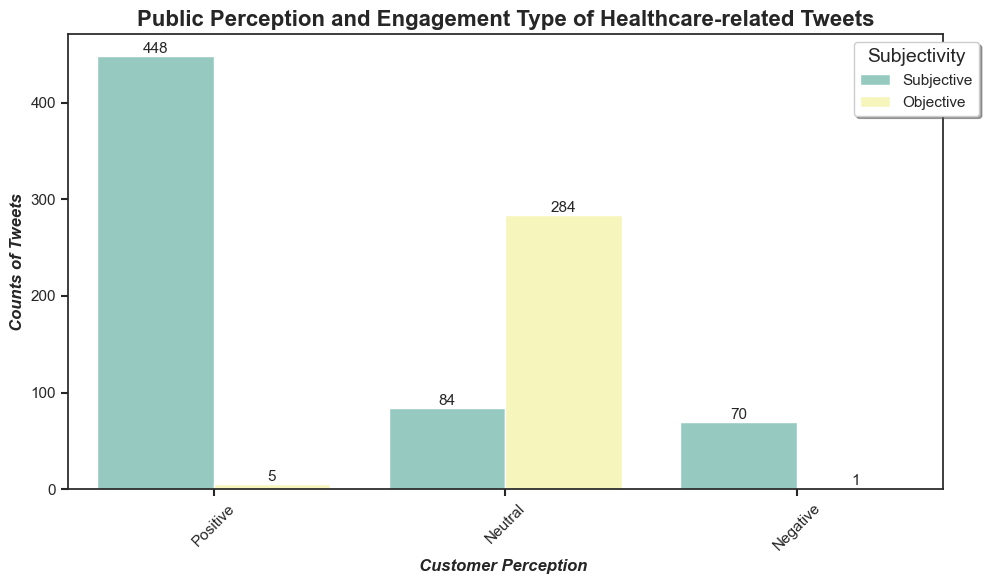

In [133]:
# Create a barchart for easy visualisation of healthcare sentiment distribution
# Use plt.subplots() instead of plt.figure() for better axis control 
fig, ax = plt.subplots(figsize=(10,6))

# Create the countplot
sns.countplot(x='polarity_label', 
              data=health_tweets,
              order=['Positive', 'Neutral', 'Negative'],
              hue='subjectivity_label',
              palette='Set3',
              ax=ax)

# Set titles and labels directly on the axis object
ax.set_title('Public Perception and Engagement Type of Healthcare-related Tweets', fontsize=16, fontweight='bold')
ax.set_xlabel('Customer Perception ', fontsize=12, fontstyle='italic', fontweight='bold')
ax.set_ylabel('Counts of Tweets', fontsize=12, fontstyle='italic', fontweight='bold')

# Cleanly add count labels on top of bars using containers
for container in ax.containers:
    # Filter out 0 or empty values to avoid visual clutter at the baseline
    labels = [f'{int(value)}' if value > 0 else '' for value in container.datavalues]
    ax.bar_label(container, labels=labels, fontsize=11)

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(title='Subjectivity', labels=['Subjective', 'Objective'],
           bbox_to_anchor=(1.05, 1),
           title_fontsize= 14, frameon=True, shadow=True) 

# Plot the figure
plt.tight_layout()
plt.savefig('Public Perception and Engagement Type of Healthcare-related Tweets.png', dpi=300)
plt.show()

In [134]:
# Most positive
print('=== Top 5 Most Positive Healthcare Tweets ===')
display(health_tweets.nlargest(5, 'polarity')[['tweet_full_text', 'polarity']])

# Most negative
print('\n=== Top 5 Most Negative Healthcare Tweets ===')
display(health_tweets.nsmallest(5, 'polarity')[['tweet_full_text', 'polarity']])

=== Top 5 Most Positive Healthcare Tweets ===


,tweet_full_text,polarity
6,🚨#NEW:🚨 Insurance companies are figuring out the best ways to collect information about members’ race and ethnicity data as focus intensifies on addressing #disparities. h/t @JessicaKimCohen &amp;...,1.0
500,The best accounting software for startups has these features #HealthCare #health #startup via https://t.co/IphRfr8oSG https://t.co/G9ZItzmvVU,1.0
521,RT @365gravity: How to find the best accounting software for your startup https://t.co/T51TxbPv3p by @GoGravityOnline\n\n#Healthcare #Busines…,1.0
578,RT @365gravity: How to find the best accounting software for your startup https://t.co/T51TxbPv3p by @GoGravityOnline\n\n#Healthcare #Busines…,1.0
689,The best accounting software for startups has these features #Startup #health #healthcare via https://t.co/u14WxAYdRI https://t.co/VvvlMPFjxC,1.0



=== Top 5 Most Negative Healthcare Tweets ===


,tweet_full_text,polarity
469,RT @drscott_atlanta: Government control of #healthcare is dangerous!!\n\n#CDC promoted disinformation https://t.co/3DqB6QeUFp,-0.9375
732,"@PierrePoilievre Sir, with respect, but how do you propose to combat #inflation , Mr. @PierrePoilievre , as opposed to #sloganeering at every opportunity you get? #cutting #taxes ? For whom and wh...",-0.7500
743,"@PierrePoilievre Sir, with respect, but how do you propose to combat #inflation , Mr. @PierrePoilievre , as opposed to #sloganeering at every opportunity you get? #cutting #taxes ? For whom and wh...",-0.7500
94,What is actually wrong with this country?!? #HealthcareIsAHumanRight #PreP #HIV #healthcare #BlueCrew #VoteBlue #NurseTwitter https://t.co/0m8EpzYAf3,-0.6250
60,"Artificial Intelligence in Cancer Diagnosis and Therapy Market Size to Boost US$ 5,299 Million By 2030| - EIN News https://t.co/osSlMyrDPh #strategy #competitiveintelligence #marketing #pharma #co...",-0.6000


#### Finding the specific NHS related twitter to gather public opinions

In [135]:
# Create a list of keywords that is related to NHS 

nhs_keywords = ['nhs', 'uk health', 'national health service',
                'uk healthcare', 'nhs uk', 'british health',
                'england health',
                'uk hospital', 'nhs trust', 'nhs digital',
                'nhs england']
# Create a function to use later to filter down the related text"
def filter_nhs_tweets(text):
    text_lower = str(text).lower()
    return any(keyword in text_lower for keyword in nhs_keywords)

# Apply filter to the column "tweet_full_text"
nhs_tweets = health_tweets[
    health_tweets['tweet_full_text'].apply(filter_nhs_tweets)]

print(f'Total NHS/UK health tweets found: {len(nhs_tweets)}')
nhs_tweets[['tweet_full_text']].head(10)

Total NHS/UK health tweets found: 1


,tweet_full_text
450,HLA Scholar Thessa Rebecca Frieble from our Amsterdam cohort tells us what leadership means to her.\n\nhttps://t.co/Wt4ZmQ3H3z\n\n#HLAScholars #Leadership #HLA #Healthcare #NHS #doctor #Medical #S...


In [136]:
# Filter from "tweet_entities_hashtags" column
nhs_tweets = health_tweets[
    health_tweets['tweet_entities_hashtags'].str.lower().str.contains(
        '|'.join(nhs_keywords), na=False)]

print(f'Total NHS tweets found: {len(nhs_tweets)}')
nhs_tweets[['tweet_full_text', 'tweet_entities_hashtags']].head(10)

Total NHS tweets found: 1


,tweet_full_text,tweet_entities_hashtags
450,HLA Scholar Thessa Rebecca Frieble from our Amsterdam cohort tells us what leadership means to her.\n\nhttps://t.co/Wt4ZmQ3H3z\n\n#HLAScholars #Leadership #HLA #Healthcare #NHS #doctor #Medical #S...,"#HLAScholars, #Leadership, #HLA, #Healthcare, #NHS, #doctor, #Medical, #Student, #Nurse, #globalhealth, #meded"


# 6. Capacity, utilisation and recommendations

In [137]:
# Load the appointments_regional.csv file.
# View the DataFrame.
ar

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,E54000034,2020-01,Attended,GP,Face-to-Face,1 Day,8107
1,E54000034,2020-01,Attended,GP,Face-to-Face,15 to 21 Days,6791
2,E54000034,2020-01,Attended,GP,Face-to-Face,2 to 7 Days,20686
3,E54000034,2020-01,Attended,GP,Face-to-Face,22 to 28 Days,4268
4,E54000034,2020-01,Attended,GP,Face-to-Face,8 to 14 Days,11971
...,...,...,...,...,...,...,...
596816,E54000050,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,E54000050,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,E54000050,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,E54000050,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [138]:
# Print the min and max dates.
ar['appointment_month'].agg(['min', 'max'])

min    2020-01
max    2022-06
Name: appointment_month, dtype: object

In [139]:
# Filter the data set to only look at data from 2021-08 onwards.

ar_copy = ar[ar['appointment_month'] >= '2021-08']

ar_copy

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
3652,E54000034,2021-08,Attended,GP,Face-to-Face,1 Day,6553
3653,E54000034,2021-08,Attended,GP,Face-to-Face,15 to 21 Days,2390
3654,E54000034,2021-08,Attended,GP,Face-to-Face,2 to 7 Days,10547
3655,E54000034,2021-08,Attended,GP,Face-to-Face,22 to 28 Days,937
3656,E54000034,2021-08,Attended,GP,Face-to-Face,8 to 14 Days,4961
...,...,...,...,...,...,...,...
596816,E54000050,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,E54000050,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,E54000050,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,E54000050,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


**Question 1:** Should the NHS start looking at increasing staff levels? 

In [140]:
# Create an aggregated data set to review the different features.

ar_agg = ar_copy[['appointment_month', 'hcp_type', 'appointment_status',
                  'appointment_mode', 'time_between_book_and_appointment','count_of_appointments']]

# View the DataFrame.
ar_agg

,appointment_month,hcp_type,appointment_status,appointment_mode,time_between_book_and_appointment,count_of_appointments
3652,2021-08,GP,Attended,Face-to-Face,1 Day,6553
3653,2021-08,GP,Attended,Face-to-Face,15 to 21 Days,2390
3654,2021-08,GP,Attended,Face-to-Face,2 to 7 Days,10547
3655,2021-08,GP,Attended,Face-to-Face,22 to 28 Days,937
3656,2021-08,GP,Attended,Face-to-Face,8 to 14 Days,4961
...,...,...,...,...,...,...
596816,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [141]:
# Determine the total number of appointments per month.
ar_df = ar_agg.groupby('appointment_month')['count_of_appointments'].sum().reset_index()

# Add a new column to indicate the average utilisation of services.
# Monthly aggregate / 30 to get to a daily value.
ar_df['utilisation'] = (ar_df['count_of_appointments'] / 30).round(1)

# View the DataFrame.
ar_df

,appointment_month,count_of_appointments,utilisation
0,2021-08,23852171,795072.4
1,2021-09,28522501,950750.0
2,2021-10,30303834,1010127.8
3,2021-11,30405070,1013502.3
4,2021-12,25140776,838025.9
5,2022-01,25635474,854515.8
6,2022-02,25355260,845175.3
7,2022-03,29595038,986501.3
8,2022-04,23913060,797102.0
9,2022-05,27495508,916516.9


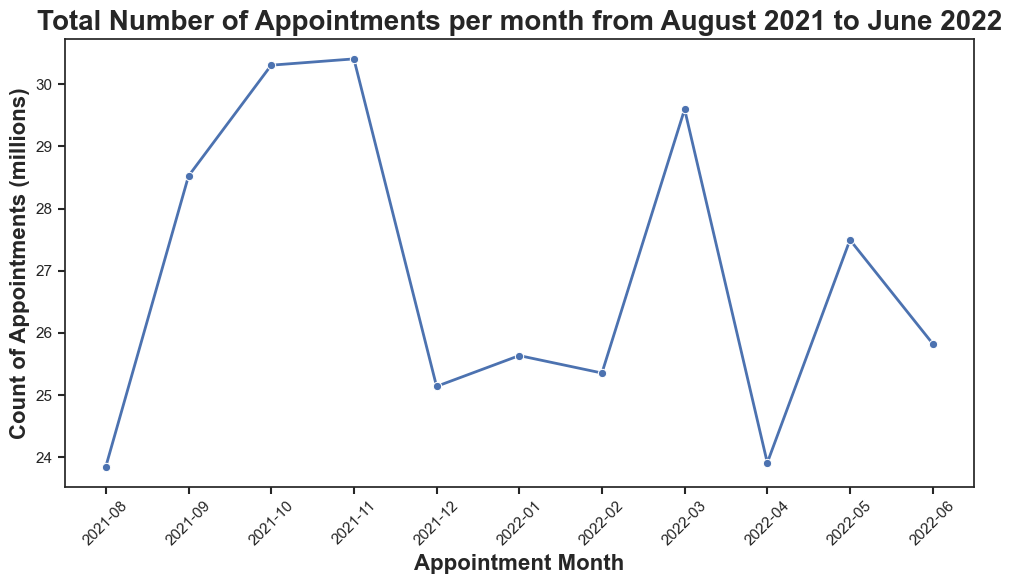

In [142]:
# Plot sum of count of monthly visits.
# Convert the appointment_month to string data type for ease of visualisation.
ar_df['appointment_month']= ar_df['appointment_month']. astype(str)

# Adding a column as "count_millions" to count appointments in millions
ar_df['appointment_millions']= ar_df['count_of_appointments']/ 1_000_000
# Create a lineplot with Seaborn.

fig, ax = plt.subplots()
fig.set_size_inches(10,6)
# Plot data

sns.lineplot(x='appointment_month', y='appointment_millions',
             data= ar_df,
            errorbar=None, linewidth=2, marker='o',
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Total Number of Appointments per month from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Plot figure
plt.tight_layout() 
plt.savefig('appointment_per_month_from_august2021_to_june2022', dpi=300)
plt.show()

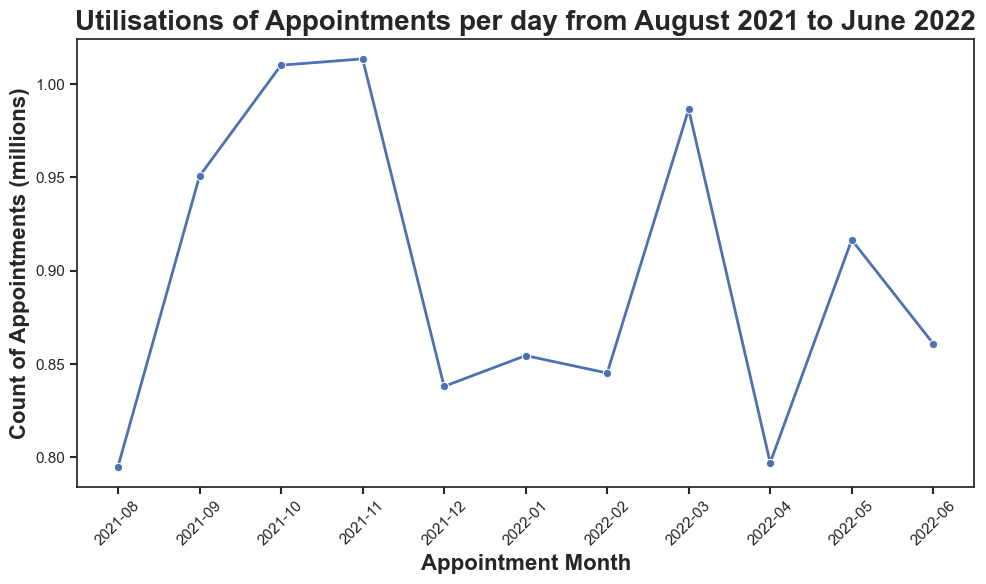

In [143]:
# Plot monthly capacity utilisation
# Adding a column as "count_millions_utilisation" to count appointments in millions
ar_df['utilisation_millions']= ar_df['utilisation']/ 1_000_000

# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(10,6)
# Plot data

sns.lineplot(x='appointment_month', y='utilisation_millions',
             data= ar_df,
            errorbar=None, linewidth=2, marker='o',
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Utilisations of Appointments per day from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Plot figure
plt.tight_layout() 
plt.savefig('utilisation_per_day_from_august2021_to_june2022', dpi=300)
plt.show()

**Question 2:** How do the healthcare professional types differ over time?

In [144]:
# Create a new DataFrame to answer the question
ar_hcp = ar_agg.groupby(['appointment_month', 'hcp_type'])['count_of_appointments'].sum().reset_index()

# Adding a new column that shows appointment as millions for better visualisation
ar_hcp['appointments_millions']= ar_hcp['count_of_appointments']/ 1_000_000

# View the DataFrame
ar_hcp

,appointment_month,hcp_type,count_of_appointments,appointments_millions
0,2021-08,GP,12299022,12.299022
1,2021-08,Other Practice staff,10797821,10.797821
2,2021-08,Unknown,755328,0.755328
3,2021-09,GP,14487785,14.487785
4,2021-09,Other Practice staff,13126731,13.126731
5,2021-09,Unknown,907985,0.907985
6,2021-10,GP,14300751,14.300751
7,2021-10,Other Practice staff,14942504,14.942504
8,2021-10,Unknown,1060579,1.060579
9,2021-11,GP,14897749,14.897749


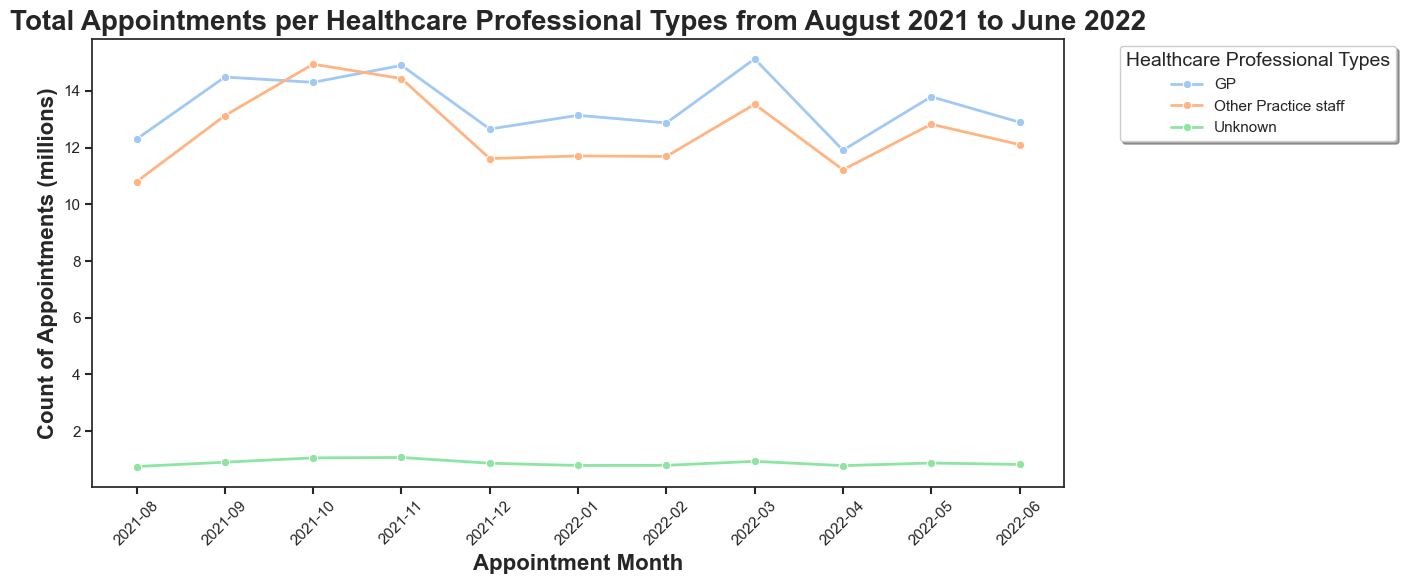

In [145]:
# Create a line plot to answer the question.
fig, ax = plt.subplots()
fig.set_size_inches(14,6)
# Plot data

sns.lineplot(x='appointment_month', y='appointments_millions',
             data= ar_hcp, hue='hcp_type',
            errorbar=None, linewidth=2, marker='o',
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Total Appointments per Healthcare Professional Types from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Healthcare Professional Types', bbox_to_anchor=(1.05, 1),
            title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('healthcare_professional_type_appt_august2021_to_june2022', dpi=300)
plt.show()

**Question 3:** Are there significant changes in whether or not visits are attended?

In [146]:
ar_agg

,appointment_month,hcp_type,appointment_status,appointment_mode,time_between_book_and_appointment,count_of_appointments
3652,2021-08,GP,Attended,Face-to-Face,1 Day,6553
3653,2021-08,GP,Attended,Face-to-Face,15 to 21 Days,2390
3654,2021-08,GP,Attended,Face-to-Face,2 to 7 Days,10547
3655,2021-08,GP,Attended,Face-to-Face,22 to 28 Days,937
3656,2021-08,GP,Attended,Face-to-Face,8 to 14 Days,4961
...,...,...,...,...,...,...
596816,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [147]:
# Create a new DataFrame to answer the question
ar_stt = ar_agg.groupby(['appointment_month', 'appointment_status'])['count_of_appointments'].sum().reset_index()

# Adding a new column that shows appointment as millions for better visualisation
ar_stt['appointments_millions']= ar_stt['count_of_appointments']/ 1_000_000

# View the DataFrame
ar_stt

,appointment_month,appointment_status,count_of_appointments,appointments_millions
0,2021-08,Attended,22081765,22.081765
1,2021-08,DNA,949137,0.949137
2,2021-08,Unknown,821269,0.821269
3,2021-09,Attended,25757066,25.757066
4,2021-09,DNA,1321348,1.321348
5,2021-09,Unknown,1444087,1.444087
6,2021-10,Attended,27170506,27.170506
7,2021-10,DNA,1565624,1.565624
8,2021-10,Unknown,1567704,1.567704
9,2021-11,Attended,27667665,27.667665


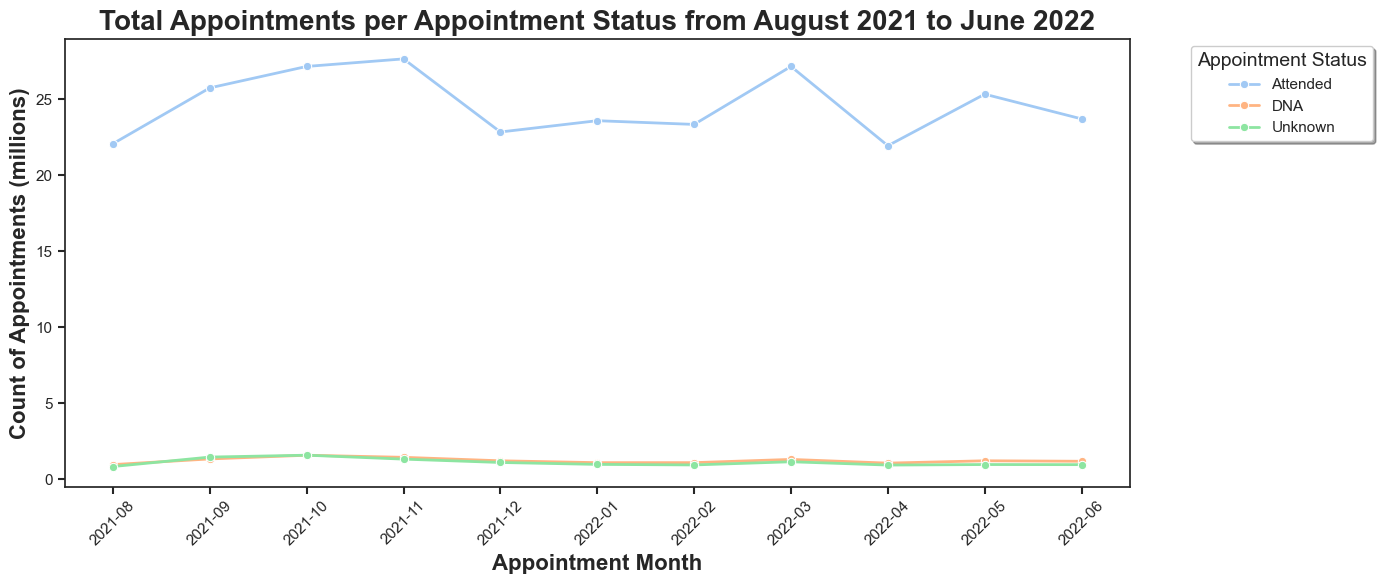

In [148]:
# Create a line plot to answer the question.
fig, ax = plt.subplots()
fig.set_size_inches(14,6)
# Plot data

sns.lineplot(x='appointment_month', y='appointments_millions',
             data= ar_stt, hue='appointment_status',
            errorbar=None, linewidth=2, marker='o',
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Total Appointments per Appointment Status from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Appointment Status', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('Appointments_per_status_august2021_to_june2022', dpi=300)
plt.show()

**Question 4:** Are there changes in terms of appointment type and the busiest months?

In [149]:
# Create a new DataFrame to answer the question
ar_mode = ar_agg.groupby(['appointment_month', 'appointment_mode'])['count_of_appointments'].sum().reset_index()

# Adding a new column that shows appointment as millions for better visualisation
ar_mode['appointments_millions']= ar_mode['count_of_appointments']/ 1_000_000

# View the DataFrame
ar_mode

,appointment_month,appointment_mode,count_of_appointments,appointments_millions
0,2021-08,Face-to-Face,13717325,13.717325
1,2021-08,Home Visit,151619,0.151619
2,2021-08,Telephone,9149072,9.149072
3,2021-08,Unknown,724126,0.724126
4,2021-08,Video/Online,110029,0.110029
5,2021-09,Face-to-Face,17266602,17.266602
6,2021-09,Home Visit,171829,0.171829
7,2021-09,Telephone,10068770,10.068770
8,2021-09,Unknown,859946,0.859946
9,2021-09,Video/Online,155354,0.155354


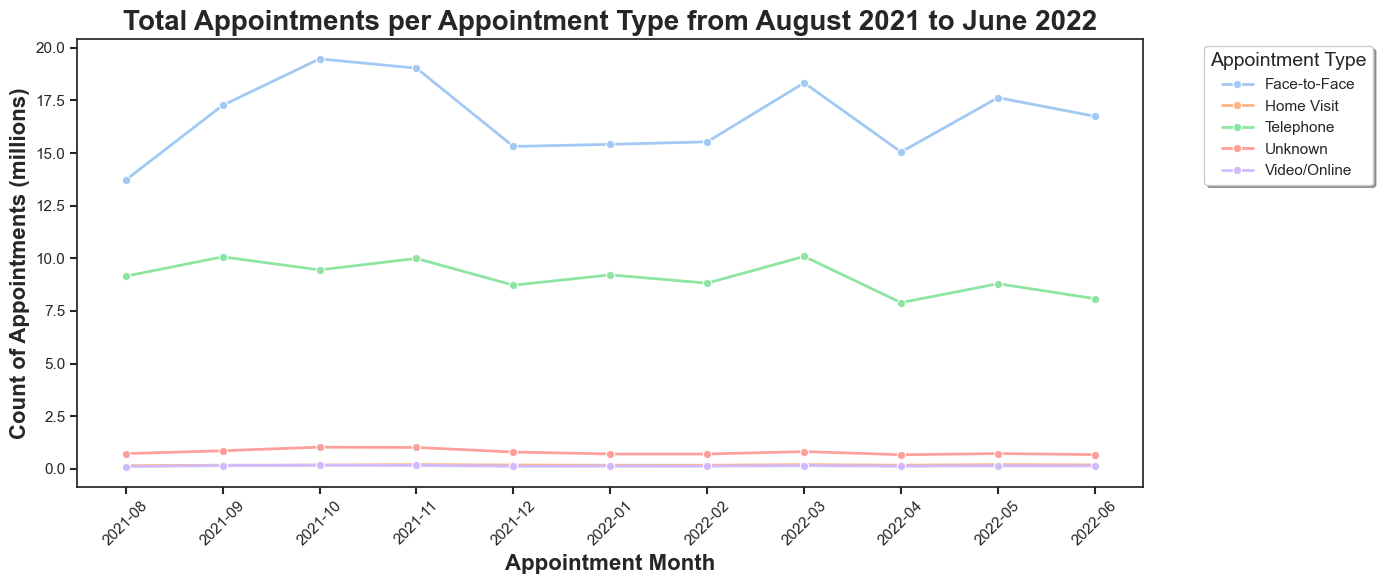

In [150]:
# Create a line plot to answer the question.
fig, ax = plt.subplots()
fig.set_size_inches(14,6)
# Plot data

sns.lineplot(x='appointment_month', y='appointments_millions',
             data= ar_mode, hue='appointment_mode',
            errorbar=None, linewidth=2, marker='o',
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Total Appointments per Appointment Type from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Appointment Type', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('Appointments_mode_from_august2021_to_june2022', dpi=300)
plt.show()

**Question 5:** Are there any trends in time between booking and appointment?

In [151]:
# Create a new DataFrame to answer the question
ar_waittime = ar_agg.groupby(['appointment_month', 'time_between_book_and_appointment'])['count_of_appointments'].sum().reset_index()

# Adding a new column that shows appointment as millions for better visualisation
ar_waittime['appointments_millions']= ar_waittime['count_of_appointments']/ 1_000_000

# View the DataFrame
ar_waittime

,appointment_month,time_between_book_and_appointment,count_of_appointments,appointments_millions
0,2021-08,1 Day,2018319,2.018319
1,2021-08,15 to 21 Days,1453209,1.453209
2,2021-08,2 to 7 Days,4924960,4.924960
3,2021-08,22 to 28 Days,828866,0.828866
4,2021-08,8 to 14 Days,2889150,2.889150
...,...,...,...,...
83,2022-06,22 to 28 Days,1217197,1.217197
84,2022-06,8 to 14 Days,3250347,3.250347
85,2022-06,More than 28 Days,1067420,1.067420
86,2022-06,Same Day,11461923,11.461923


In [152]:
# Create order of "time_and_between_book_and_appointment" column
# Get the last value of each category in the column
waittime = ar_waittime.groupby('time_between_book_and_appointment')\
              ['appointments_millions']\
                .last().sort_values(ascending=False)

waittime_categories = waittime.index.tolist()

waittime_categories

['Same Day',
 '2 to 7 Days',
 '8  to 14 Days',
 '1 Day',
 '15  to 21 Days',
 '22  to 28 Days',
 'More than 28 Days',
 'Unknown / Data Quality']

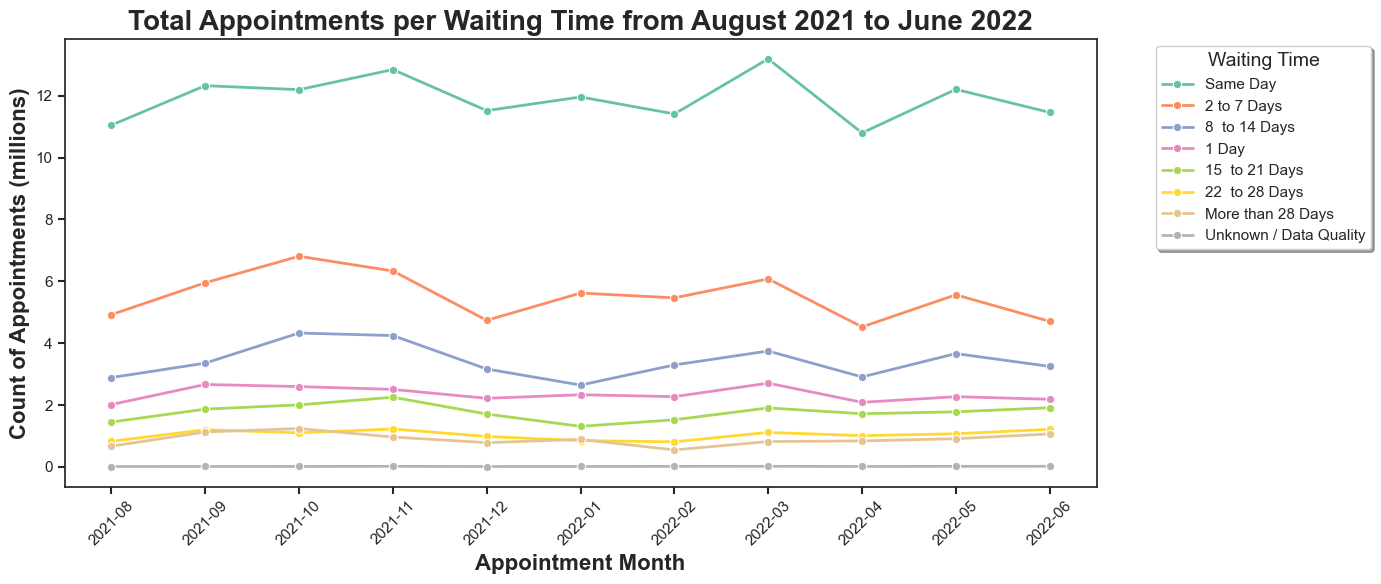

In [153]:
## Create a line plot to answer the question.
fig, ax = plt.subplots()
fig.set_size_inches(14,6)
# Plot data

sns.lineplot(x='appointment_month', y='appointments_millions',
             data= ar_waittime, hue='time_between_book_and_appointment',
             hue_order=waittime_categories, # control legend order
            errorbar=None, linewidth=2, marker='o',
             palette='Set2',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5, rotation=45) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Total Appointments per Waiting Time from August 2021 to June 2022', fontsize= 20, fontweight='bold')
ax.set_xlabel('Appointment Month', fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding legend
plt.legend(title='Waiting Time', bbox_to_anchor=(1.05, 1),
          title_fontsize= 14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout() 
plt.savefig('Appointments_mode_from_august2021_to_june2022', dpi=300)
plt.show()

In [154]:
# Getting a new DataFrame that includes appointment_mode, time_between_book_and_appointment and count_of_appointments
ar_leadtime1 = ar_copy.groupby(['appointment_mode','time_between_book_and_appointment'])['count_of_appointments'].sum().reset_index()

# Adding a new column that shows appointment as millions for better visualisation
ar_leadtime1['appointments_millions']= ar_leadtime1['count_of_appointments']/ 1_000_000

# View the DataFrame
ar_leadtime1

,appointment_mode,time_between_book_and_appointment,count_of_appointments,appointments_millions
0,Face-to-Face,1 Day,16111422,16.111422
1,Face-to-Face,15 to 21 Days,14501752,14.501752
2,Face-to-Face,2 to 7 Days,42303114,42.303114
3,Face-to-Face,22 to 28 Days,8710315,8.710315
4,Face-to-Face,8 to 14 Days,27862128,27.862128
5,Face-to-Face,More than 28 Days,8116493,8.116493
6,Face-to-Face,Same Day,65792768,65.792768
7,Face-to-Face,Unknown / Data Quality,105595,0.105595
8,Home Visit,1 Day,288216,0.288216
9,Home Visit,15 to 21 Days,45617,0.045617


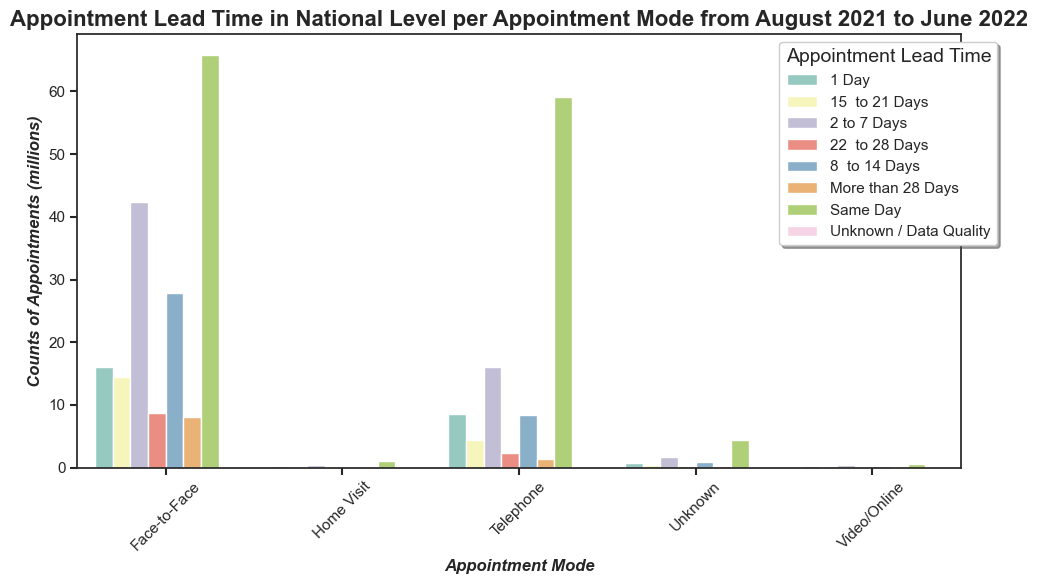

In [155]:
# Create a barchart for easy visualisation of healthcare sentiment distribution
# Use plt.subplots() instead of plt.figure() for better axis control 
fig, ax = plt.subplots(figsize=(10,6))

# Create the countplot
sns.barplot(x='appointment_mode', 
              data=ar_leadtime1,
              y='appointments_millions',
              hue='time_between_book_and_appointment',
              palette='Set3',
              ax=ax)

# Set titles and labels directly on the axis object
ax.set_title('Appointment Lead Time in National Level per Appointment Mode from August 2021 to June 2022' , fontsize=16, fontweight='bold')
ax.set_xlabel('Appointment Mode', fontsize=12, fontstyle='italic', fontweight='bold')
ax.set_ylabel('Counts of Appointments (millions)', fontsize=12, fontstyle='italic', fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(title='Appointment Lead Time',
           bbox_to_anchor=(1.05, 1),
           title_fontsize= 14, frameon=True, shadow=True) 

# Plot the figure
plt.tight_layout()
plt.savefig('appointment_leadtime_national_appointment_mode.png', dpi=300)
plt.show()

**Question 6:** How do the various service settings compare?

In [217]:
nc

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
0,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Primary Care Network,Care Related Encounter,Patient contact during Care Home Round,3,2021-08,0.000003
1,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,Other,Care Related Encounter,Planned Clinics,7,2021-08,0.000007
2,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Home Visit,79,2021-08,0.000079
3,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,General Consultation Acute,725,2021-08,0.000725
4,2021-08-02,E54000050,NHS North East and North Cumbria ICB - 00L,General Practice,Care Related Encounter,Structured Medication Review,2,2021-08,0.000002
...,...,...,...,...,...,...,...,...,...
817389,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Unplanned Clinical Activity,12,2022-06,0.000012
817390,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinics,4,2022-06,0.000004
817391,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,Planned Clinical Procedure,92,2022-06,0.000092
817392,2022-06-30,E54000054,NHS West Yorkshire ICB - X2C4Y,Extended Access Provision,Care Related Encounter,General Consultation Routine,4,2022-06,0.000004


In [157]:
nc.columns.tolist()

['appointment_date',
 'icb_ons_code',
 'sub_icb_location_name',
 'service_setting',
 'context_type',
 'national_category',
 'count_of_appointments',
 'appointment_month',
 'count_millions']

In [158]:
# Create a new DataFrame consisting of the month of appointment and the number of appointments.
nc_df = nc.groupby(['appointment_month','service_setting'])['count_millions'].sum().reset_index()
# View the DataFrame.
nc_df

,appointment_month,service_setting,count_millions
0,2021-08,Extended Access Provision,0.160927
1,2021-08,General Practice,21.575852
2,2021-08,Other,0.449101
3,2021-08,Primary Care Network,0.432448
4,2021-08,Unmapped,1.233843
5,2021-09,Extended Access Provision,0.187906
6,2021-09,General Practice,25.940821
7,2021-09,Other,0.527174
8,2021-09,Primary Care Network,0.530485
9,2021-09,Unmapped,1.336115


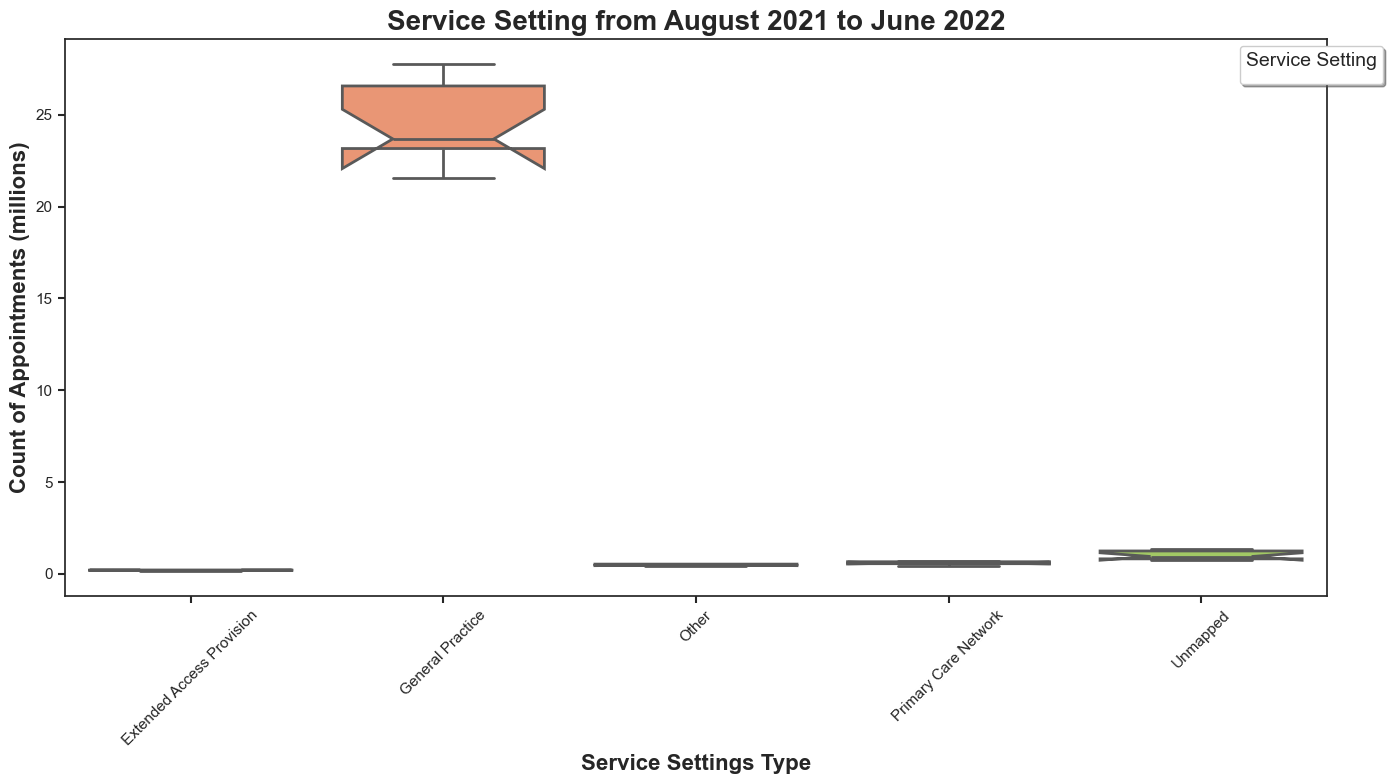

In [159]:
# Create a boxplot to indicate the service settings for the number of appointments
fig, ax = plt.subplots()
fig.set_size_inches(14, 8)

# Plot data
sns.boxplot(x='service_setting', y='count_millions',
            data=nc_df,
            notch=True, linewidth=2,
            palette='Set2')

# Adding tick parameters
ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)
ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and labels
ax.set_title('Service Setting from August 2021 to June 2022',
             fontsize=20, fontweight='bold')
ax.set_xlabel('Service Settings Type', fontsize=16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)', fontsize=16, fontweight='bold')

# Adding legend
plt.legend(title='Service Setting', bbox_to_anchor=(1.05, 1),
           title_fontsize=14, frameon=True, shadow=True)

# Plot figure
plt.tight_layout()
plt.savefig('service_setting_from_august2021_to_june2022', dpi=300)
plt.show()

In [160]:
# Getting all service setting types
nc_df['service_setting'].unique().tolist()

['Extended Access Provision',
 'General Practice',
 'Other',
 'Primary Care Network',
 'Unmapped']

In [161]:
# Create a new Dataframe without GP visits
nc_df_1 = nc_df[nc_df['service_setting'].isin(['Extended Access Provision','Other',
                                               'Primary Care Network','Unmapped'])]

nc_df_1

,appointment_month,service_setting,count_millions
0,2021-08,Extended Access Provision,0.160927
2,2021-08,Other,0.449101
3,2021-08,Primary Care Network,0.432448
4,2021-08,Unmapped,1.233843
5,2021-09,Extended Access Provision,0.187906
7,2021-09,Other,0.527174
8,2021-09,Primary Care Network,0.530485
9,2021-09,Unmapped,1.336115
10,2021-10,Extended Access Provision,0.209539
12,2021-10,Other,0.556487


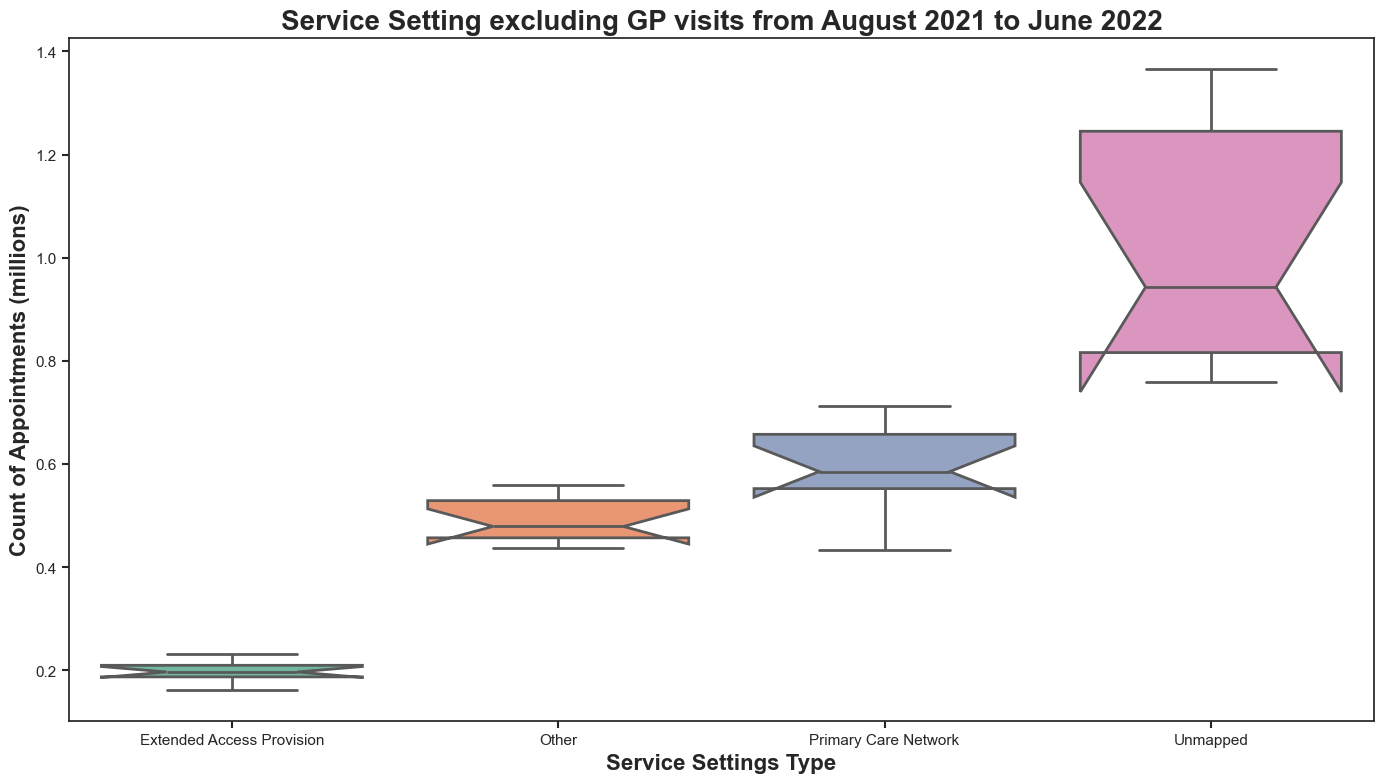

In [162]:
# Create a boxplot in Seaborn where you concentrate on all the service settings, excluding GP visits.
fig, ax = plt.subplots()
fig.set_size_inches(14,8)

# Plot data
sns.boxplot(x='service_setting', y='count_millions',
            data=nc_df_1,
            notch=True, linewidth=2,
            palette='Set2')

# Adding tick parameters
ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5)
ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding title and labels
ax.set_title('Service Setting excluding GP visits from August 2021 to June 2022',
             fontsize=20, fontweight='bold')
ax.set_xlabel('Service Settings Type', fontsize=16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)', fontsize=16, fontweight='bold')

# Plot figure
plt.tight_layout()
plt.savefig('service_setting_excluding_GP_from_august2021_to_june2022', dpi=300)
plt.show()

#### Reflections and further data analysis

#### Limitations of data:
- Nearly 1.2 appointments remain as "unmapped" -> which shows a big data quality flag where a noticeable share of appointment aren't properly classified.
- I want to deep dive in missed appointments and whether to find any insights from what reasons might affect the missed appointments -> however none of current datasets provide any appointments regarding missed appointments -> this could lead to further investigation to identify any links between unmapped service and "missed appointments" and any other data that could be used to strengthen the analysis. In my humble opinion, I would like to receive more information regarding the symptoms/ or any health conditions if possible to answer this question.

#### Questions for further exploration:
- Finding further correlations between waiting time and national service setting/appointment mode/
- Unmapped appointment: regarding data quality -> seek any particular ICBs/sub ICBs to give recommendations

#### Utilisation of resources question: Let's deep dive into the period November 2021 and April 2022

- Through the above visualizations, it has been shown that from Sep to Nov 2021, the demand for NHS appointments was significantly increasing and experienced a steady upward trend before reaching its peak in Nov 2021. In November 2021, the benchmark of 1,200,000 appointments per day was at around 90%.

- However, it dropped sharply in December 2021 and January 2022, and fluctuated massively from March 2022 to June 2022. Compared to the overall figure, it clearly showed that the utilization of appointments never returned to their peak time in Sep to Nov 2021, and April 2022 marked its lowest point of utilisation.

I decided to look at these 2 months to seek deeper insights and see if there are any patterns that might be able to explain this contrast.

In [163]:
# Calling a new DataFrame from the original DataFrame
ar_subset = ar

ar_subset.info()
ar_subset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 596821 entries, 0 to 596820
Data columns (total 7 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   icb_ons_code                       596821 non-null  object
 1   appointment_month                  596821 non-null  object
 2   appointment_status                 596821 non-null  object
 3   hcp_type                           596821 non-null  object
 4   appointment_mode                   596821 non-null  object
 5   time_between_book_and_appointment  596821 non-null  object
 6   count_of_appointments              596821 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 31.9+ MB


,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,E54000034,2020-01,Attended,GP,Face-to-Face,1 Day,8107
1,E54000034,2020-01,Attended,GP,Face-to-Face,15 to 21 Days,6791
2,E54000034,2020-01,Attended,GP,Face-to-Face,2 to 7 Days,20686
3,E54000034,2020-01,Attended,GP,Face-to-Face,22 to 28 Days,4268
4,E54000034,2020-01,Attended,GP,Face-to-Face,8 to 14 Days,11971
...,...,...,...,...,...,...,...
596816,E54000050,2022-06,Unknown,Unknown,Unknown,2 to 7 Days,21
596817,E54000050,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,8
596818,E54000050,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,28
596819,E54000050,2022-06,Unknown,Unknown,Unknown,More than 28 Days,17


In [164]:
# Filter appointment month to show only period in April 2022
ar_april= ar_subset[ar_subset['appointment_month'].isin(['2022-04'])]

ar_april

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
5199,E54000034,2022-04,Attended,GP,Face-to-Face,1 Day,6705
5200,E54000034,2022-04,Attended,GP,Face-to-Face,15 to 21 Days,3326
5201,E54000034,2022-04,Attended,GP,Face-to-Face,2 to 7 Days,9874
5202,E54000034,2022-04,Attended,GP,Face-to-Face,22 to 28 Days,1622
5203,E54000034,2022-04,Attended,GP,Face-to-Face,8 to 14 Days,5566
...,...,...,...,...,...,...,...
596462,E54000050,2022-04,Unknown,Unknown,Unknown,2 to 7 Days,14
596463,E54000050,2022-04,Unknown,Unknown,Unknown,22 to 28 Days,13
596464,E54000050,2022-04,Unknown,Unknown,Unknown,8 to 14 Days,22
596465,E54000050,2022-04,Unknown,Unknown,Unknown,More than 28 Days,33


In [165]:
# Group by icb_ons_code for better comparison of appointments 

ar_april_subset = ar_april.groupby(['icb_ons_code'])['count_of_appointments'].sum().reset_index()

# Adding 'utilisations column for understanding capacity per day
ar_april_subset['utilisation']= (ar_april_subset['count_of_appointments'] / 30).round(1)

ar_april_subset.sort_values(by='utilisation', ascending=False)

,icb_ons_code,count_of_appointments,utilisation
29,E54000050,1379494,45983.1
33,E54000054,1174475,39149.2
36,E54000057,1118651,37288.4
0,E54000008,1062508,35416.9
12,E54000027,1006387,33546.2
14,E54000029,774019,25800.6
17,E54000032,754730,25157.7
25,E54000042,747942,24931.4
30,E54000051,742852,24761.7
32,E54000053,722669,24089.0


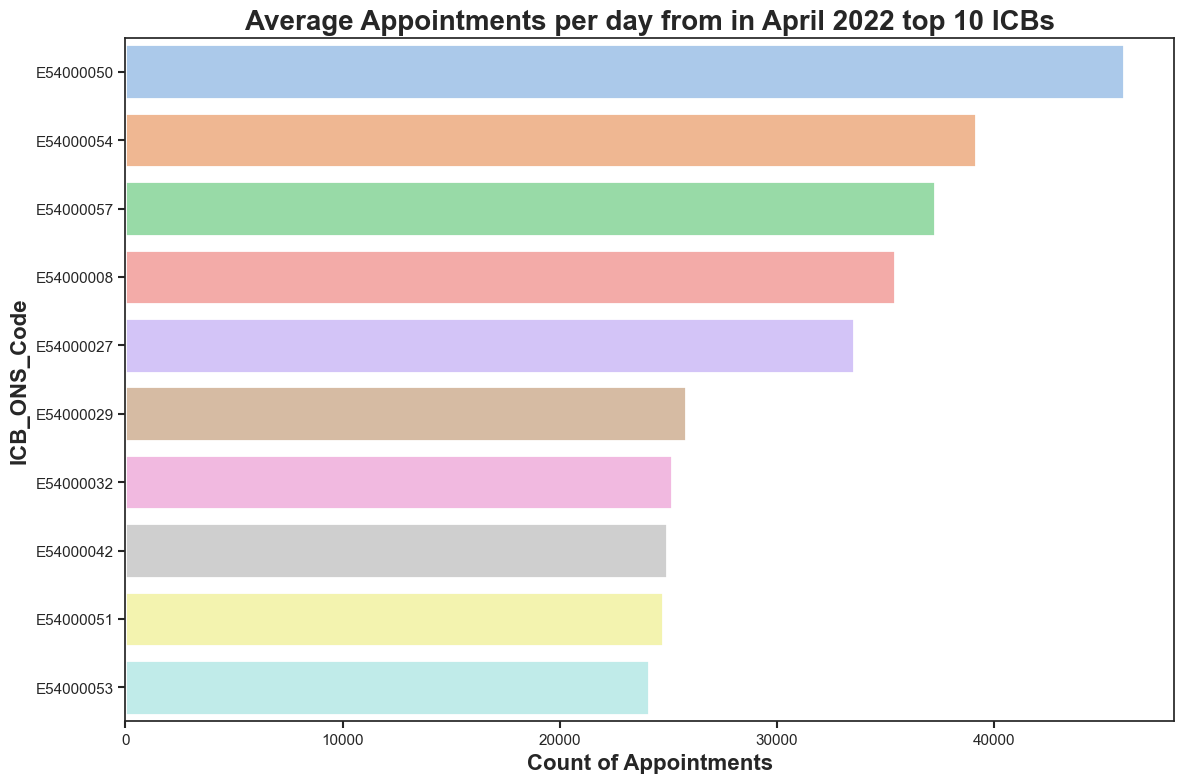

In [166]:
# Plot monthly capacity utilisation per ICB
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(12,8)
# Plot data

sns.barplot(x='utilisation',y='icb_ons_code',
             data= ar_april_subset.sort_values(by='utilisation',ascending=False).head(10),
            errorbar=None, linewidth=2,
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Average Appointments per day from in April 2022 top 10 ICBs', fontsize= 20, fontweight='bold')
ax.set_xlabel('Count of Appointments', fontsize= 16, fontweight='bold')
ax.set_ylabel('ICB_ONS_Code',fontsize= 16, fontweight='bold')

# Plot figure
plt.tight_layout() 
plt.savefig('utilisation_per_day_icb_april2022', dpi=300)
plt.show()

In [167]:
# Filter appointment month to show only period in November 2021
ar_nov= ar_subset[ar_subset['appointment_month'].isin(['2021-11'])]

ar_nov

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
4239,E54000034,2021-11,Attended,GP,Face-to-Face,1 Day,7823
4240,E54000034,2021-11,Attended,GP,Face-to-Face,15 to 21 Days,4477
4241,E54000034,2021-11,Attended,GP,Face-to-Face,2 to 7 Days,14177
4242,E54000034,2021-11,Attended,GP,Face-to-Face,22 to 28 Days,1801
4243,E54000034,2021-11,Attended,GP,Face-to-Face,8 to 14 Days,7487
...,...,...,...,...,...,...,...
595575,E54000050,2021-11,Unknown,Unknown,Unknown,2 to 7 Days,31
595576,E54000050,2021-11,Unknown,Unknown,Unknown,22 to 28 Days,7
595577,E54000050,2021-11,Unknown,Unknown,Unknown,8 to 14 Days,35
595578,E54000050,2021-11,Unknown,Unknown,Unknown,More than 28 Days,14


In [168]:
# Group by icb_ons_code for better comparison of appointments 

ar_nov_subset = ar_nov.groupby(['icb_ons_code'])['count_of_appointments'].sum().reset_index()

# Adding 'utilisations column for understanding capacity per day
ar_nov_subset['utilisation']= (ar_nov_subset['count_of_appointments'] / 30).round(1)

ar_nov_subset.sort_values(by='utilisation', ascending=False)

,icb_ons_code,count_of_appointments,utilisation
29,E54000050,1738485,57949.5
33,E54000054,1473951,49131.7
36,E54000057,1425077,47502.6
0,E54000008,1366727,45557.6
12,E54000027,1204118,40137.3
14,E54000029,968353,32278.4
17,E54000032,963115,32103.8
25,E54000042,940011,31333.7
30,E54000051,937062,31235.4
27,E54000044,933900,31130.0


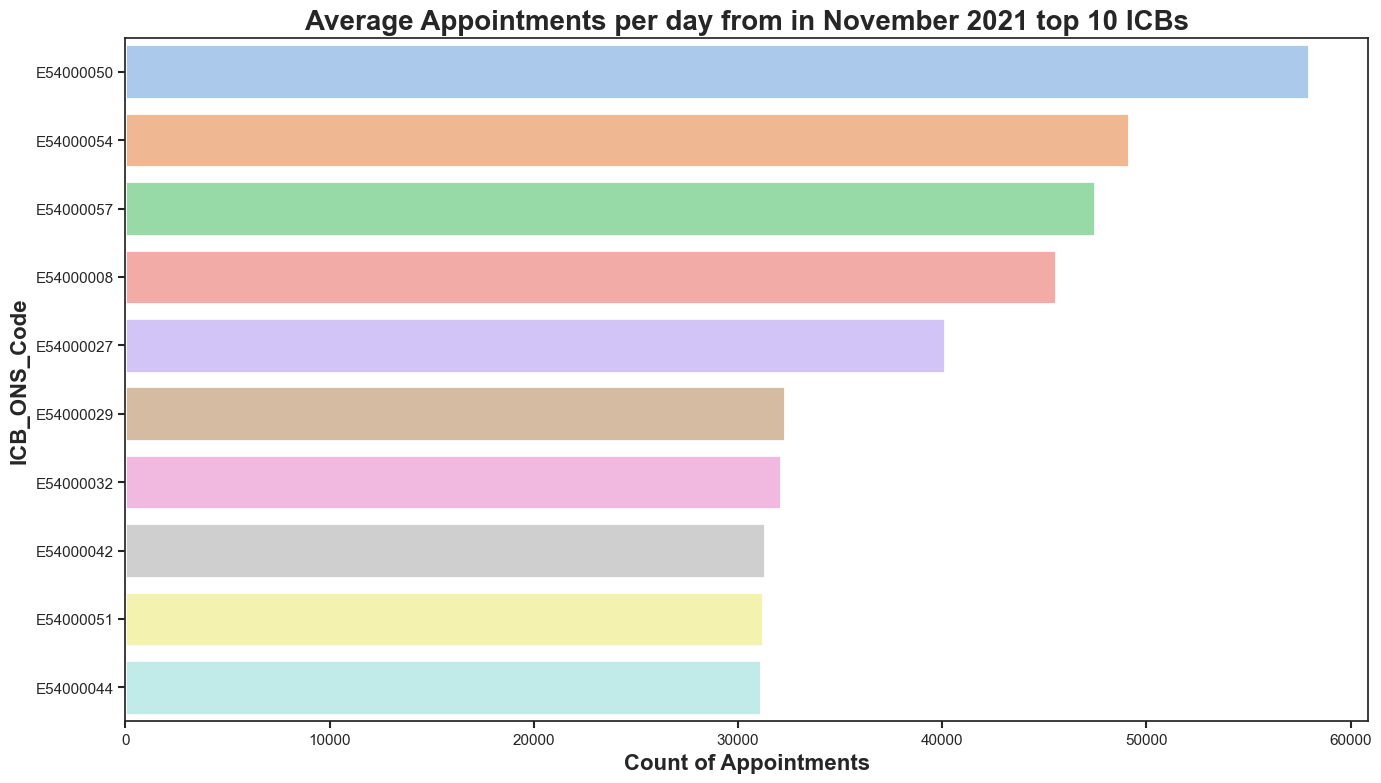

In [169]:
# Plot monthly capacity utilisation per ICB
# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(14,8)
# Plot data

sns.barplot(x='utilisation',y='icb_ons_code',
             data= ar_nov_subset.sort_values(by='utilisation',ascending=False).head(10),
            errorbar=None, linewidth=2,
             palette='pastel',ax=ax)

# Adding tick parameters
ax.tick_params(axis='x',which='major',bottom=True,
               length=5,width=1.5) 
ax.tick_params(axis='y',which='major',left=True,
               length=5,width=1.5) 

# Adding title and label
ax.set_title('Average Appointments per day from in November 2021 top 10 ICBs', fontsize= 20, fontweight='bold')
ax.set_xlabel('Count of Appointments', fontsize= 16, fontweight='bold')
ax.set_ylabel('ICB_ONS_Code',fontsize= 16, fontweight='bold')

# Plot figure
plt.tight_layout() 
plt.savefig('utilisation_per_day_icb_nov2021', dpi=300)
plt.show()

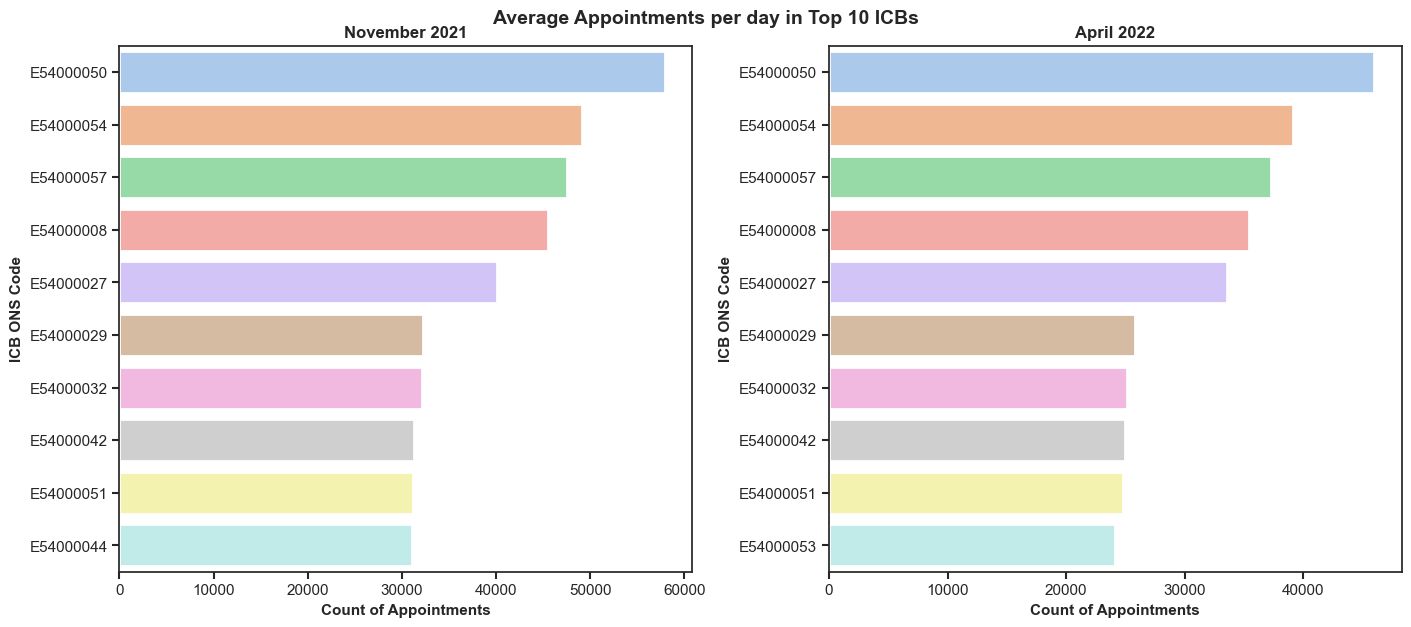

In [170]:
fig, axes = plt.subplots(1, 2, figsize=(14,6), constrained_layout=True)

# ✅ November 2021 — LEFT (axes[0])
sns.barplot(x='utilisation', y='icb_ons_code',
            data=ar_nov_subset.sort_values(by='utilisation', ascending=False).head(10),
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[0])

axes[0].set_title('November 2021', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[0].set_ylabel('ICB ONS Code', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[0].tick_params(axis='y', which='major', left=True, length=5, width=1.5)

# ✅ April 2022 — RIGHT (axes[1])
sns.barplot(x='utilisation', y='icb_ons_code',
            data=ar_april_subset.sort_values(by='utilisation', ascending=False).head(10),
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[1])

axes[1].set_title('April 2022', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[1].set_ylabel('ICB ONS Code', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[1].tick_params(axis='y', which='major', left=True, length=5, width=1.5)

# Shared overall title
fig.suptitle('Average Appointments per day in Top 10 ICBs',
             fontsize=14, fontweight='bold', y=1.02)

plt.savefig('combined_utilisation.png', dpi=300, bbox_inches='tight')
plt.show()

#### Plot above chart in a different way for better comparison, where it can easily show how much the total of appointments has dropped within 4 months

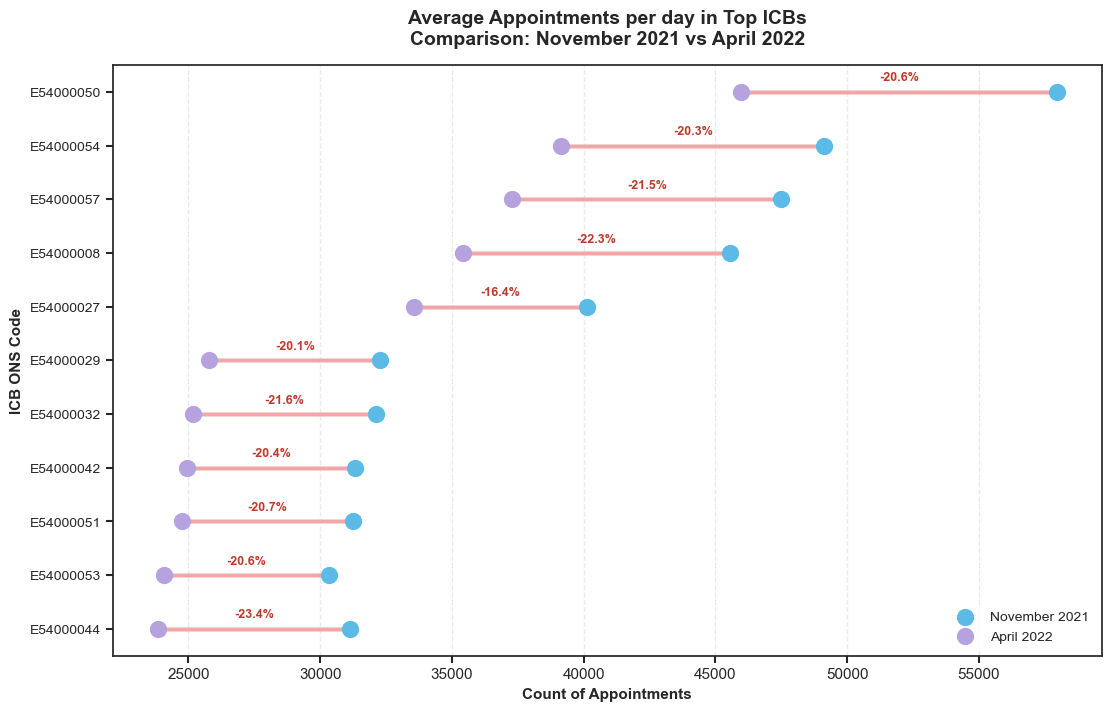

In [171]:
# 1. PREPARE THE DATA
# Extract columns and rename them to distinguish between months
df_nov = ar_nov_subset[['icb_ons_code', 'utilisation']].rename(columns={'utilisation': 'nov_utilisation'})
df_apr = ar_april_subset[['icb_ons_code', 'utilisation']].rename(columns={'utilisation': 'apr_utilisation'})

# Merge both months together based on the ICB code
df_merged = pd.merge(df_nov, df_apr, on='icb_ons_code', how='outer')

# Find the unique union of the Top 10 from both months (handles the 11 total unique ICBs)
top_nov = ar_nov_subset.sort_values(by='utilisation', ascending=False).head(10)['icb_ons_code']
top_apr = ar_april_subset.sort_values(by='utilisation', ascending=False).head(10)['icb_ons_code']
unique_top_icbs = pd.concat([top_nov, top_apr]).unique()

# Filter and sort the data (ascending=True places the highest April values at the top of a horizontal plot)
df_plot = df_merged[df_merged['icb_ons_code'].isin(unique_top_icbs)].copy()
df_plot = df_plot.sort_values(by='apr_utilisation', ascending=True)

# 2. PLOT THE DATA
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

# Create fixed numerical positions for the y-axis rows
y_positions = range(len(df_plot))

# Draw the connecting lines ("dumbbell handles")
for i, (idx, row) in enumerate(df_plot.iterrows()):
    # Only draw lines if data for both months exists to avoid NaN errors
    if pd.notna(row['nov_utilisation']) and pd.notna(row['apr_utilisation']):
        ax.plot([row['nov_utilisation'], row['apr_utilisation']], [i, i], 
                color='#d3d3d3', linewidth=2.5, zorder=1)

# Plot the dots ("dumbbell weights")
ax.scatter(df_plot['nov_utilisation'], y_positions, color='#5cbae6', s=130, label='November 2021', zorder=2)
ax.scatter(df_plot['apr_utilisation'], y_positions, color='#b6a2de', s=130, label='April 2022', zorder=2)

# 3. STYLING & LABELS
# Set the text labels for the y-axis rows
ax.set_yticks(y_positions)
ax.set_yticklabels(df_plot['icb_ons_code'], fontsize=10)

# Add grid lines for the x-axis to make scanning values easier
ax.grid(True, axis='x', linestyle='--', alpha=0.4)

# Labels and Title
ax.set_title('Average Appointments per day in Top ICBs\nComparison: November 2021 vs April 2022', 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Count of Appointments', fontsize=11, fontweight='bold')
ax.set_ylabel('ICB ONS Code', fontsize=11, fontweight='bold')

# Ticks styling
ax.tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
ax.tick_params(axis='y', which='major', left=True, length=5, width=1.5)

for i, (idx, row) in enumerate(df_plot.iterrows()):
    if pd.notna(row['nov_utilisation']) and pd.notna(row['apr_utilisation']):
        # If April is less than November, it's a decline (color it light red)
        line_color = '#f3a6a6' if row['apr_utilisation'] < row['nov_utilisation'] else '#d3d3d3'
        
        ax.plot([row['nov_utilisation'], row['apr_utilisation']], [i, i], 
                color=line_color, linewidth=2.5, zorder=1)
# 4. ADDING CALCULATION HOW MUCH PERCENTAGE HAS DROPPED FROM APRIL 2022 to NOV 2021
# Place the legend cleanly inside the plot space
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none', fontsize=10)
# Create the figure and plot the dots as you normally do...
for i, (idx, row) in enumerate(df_plot.iterrows()):
    if pd.notna(row['nov_utilisation']) and pd.notna(row['apr_utilisation']):
        nov_val = row['nov_utilisation']
        apr_val = row['apr_utilisation']
        
        # 1. Calculate the percentage drop
        pct_drop = ((apr_val - nov_val) / nov_val) * 100
        
        # 2. Draw the dumbbell handle
        ax.plot([nov_val, apr_val], [i, i], color='#f3a6a6', linewidth=2.5, zorder=1)
        
        # 3. Add the percentage text label slightly above the middle of the handle
        mid_point = (nov_val + apr_val) / 2
        ax.text(mid_point, i + 0.15, f"{pct_drop:.1f}%", 
                ha='center', va='bottom', fontsize=9, fontweight='bold', color='#c0392b')

# Save the new chart
plt.savefig('dumbbell_utilisation.png', dpi=300, bbox_inches='tight')
plt.show()

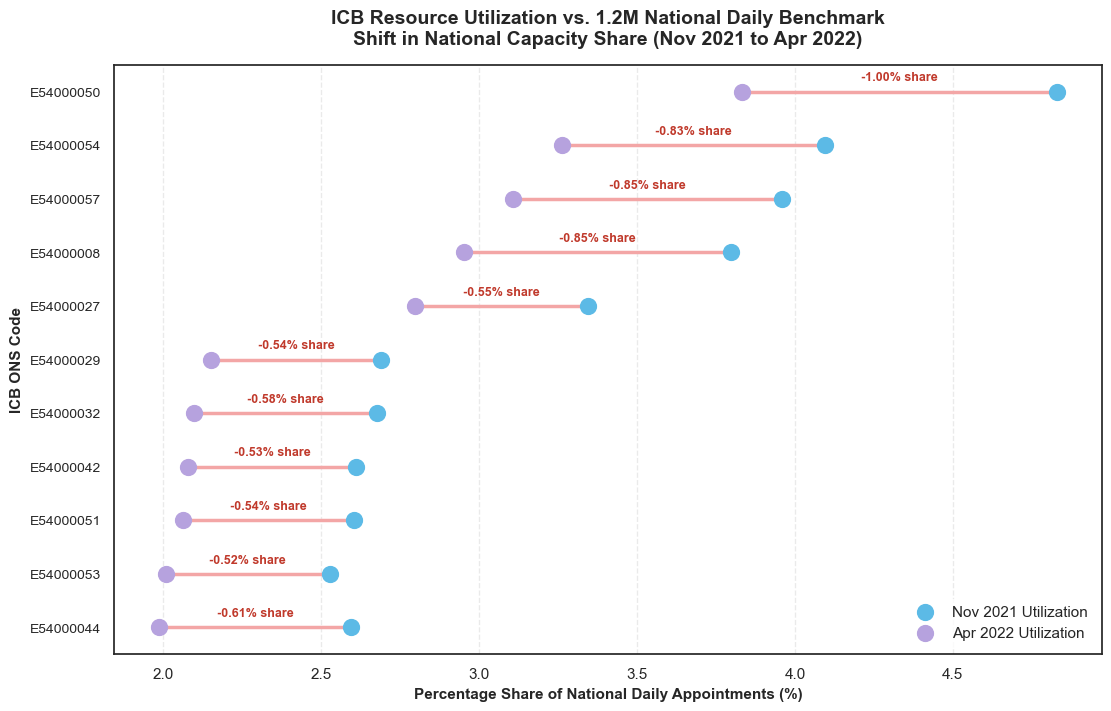

In [172]:
# 1. Define the national benchmark (1.2 million per day)
BENCHMARK = 1200000

# 2. Convert raw appointment counts into percentage of national resource utilization
df_plot['nov_pct_of_national'] = (df_plot['nov_utilisation'] / BENCHMARK) * 100
df_plot['apr_pct_of_national'] = (df_plot['apr_utilisation'] / BENCHMARK) * 100

# Sort by April resource utilization to keep your existing structural order
df_plot = df_plot.sort_values(by='apr_pct_of_national', ascending=True)

# 3. Plotting
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
y_positions = range(len(df_plot))

for i, (idx, row) in enumerate(df_plot.iterrows()):
    if pd.notna(row['nov_pct_of_national']) and pd.notna(row['apr_pct_of_national']):
        nov_pct = row['nov_pct_of_national']
        apr_pct = row['apr_pct_of_national']
        
        # Calculate absolute difference in national resource share
        share_dropped = nov_pct - apr_pct
        
        # Draw the connection line (representing lost national resource share)
        ax.plot([nov_pct, apr_pct], [i, i], color='#f3a6a6', linewidth=2.5, zorder=1)
        
        # Label the line with how much national resource share was lost
        mid_point = (nov_pct + apr_pct) / 2
        ax.text(mid_point, i + 0.15, f"-{share_dropped:.2f}% share", 
                ha='center', va='bottom', fontsize=9, fontweight='bold', color='#c0392b')

# Plot the individual month markers
ax.scatter(df_plot['nov_pct_of_national'], y_positions, color='#5cbae6', s=130, label='Nov 2021 Utilization', zorder=2)
ax.scatter(df_plot['apr_pct_of_national'], y_positions, color='#b6a2de', s=130, label='Apr 2022 Utilization', zorder=2)

# Formatting
ax.set_yticks(y_positions)
ax.set_yticklabels(df_plot['icb_ons_code'], fontsize=10)
ax.set_title('ICB Resource Utilization vs. 1.2M National Daily Benchmark\nShift in National Capacity Share (Nov 2021 to Apr 2022)', 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Percentage Share of National Daily Appointments (%)', fontsize=11, fontweight='bold')
ax.set_ylabel('ICB ONS Code', fontsize=11, fontweight='bold')
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')

plt.savefig('national_benchmark_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

#### Insights from above charts:

- Among the top 10 ICBs of the whole of England, from November 2021 to April 2022, total appointments in each ICB dropped by an average 20%.
- The biggest ICB of the whole nation E54000050 lost 1% in terms of its national resources from Nov 2021 to April 2022.
  
- What caught my attention was E54000044: the drop in percentage was the largest among the top 10 at 23.4 % - if using benchmarking with E54000051 and E54000032: they all had the same capacity in November 2021, however then in April 2022, E54000044 experienced a drop gap of 3% more than others.

- Compared with the benchmark of 1.2M appointments a day, this has also shows that: E54000044 lost about 0.61% of the entire UK's daily appointment capacity over those 5 months, while other similar-sized peers such as E54000051 and E54000052 lost less, which were around 0.54% and 0.53% respectively.

-> Need further investigations about what caused this to offer recommendations, which would be:

- an appointment status issue
- waiting time issue
- national categories issue

-> Next step moving forward: extract all information regarding E54000044 and do further investigation.

#### Extract all information in 3 datasets related to E54000044 for analysis

In [173]:
ar_44= ar_copy[ar_copy['icb_ons_code'].isin(['E54000044'])]

ar_44

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
17205,E54000044,2021-08,Attended,GP,Face-to-Face,1 Day,5058
17206,E54000044,2021-08,Attended,GP,Face-to-Face,15 to 21 Days,1648
17207,E54000044,2021-08,Attended,GP,Face-to-Face,2 to 7 Days,11229
17208,E54000044,2021-08,Attended,GP,Face-to-Face,22 to 28 Days,723
17209,E54000044,2021-08,Attended,GP,Face-to-Face,8 to 14 Days,3727
...,...,...,...,...,...,...,...
33022,E54000044,2022-06,Unknown,Unknown,Telephone,Same Day,15
33023,E54000044,2022-06,Unknown,Unknown,Unknown,15 to 21 Days,3
33024,E54000044,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,2
33025,E54000044,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,1


In [214]:
ar_44['count_of_appointments'].sum()

np.int64(8924264)

In [174]:
nc_44= nc[nc['icb_ons_code'].isin(['E54000044'])]

nc_44.columns.tolist()

nc_44

,appointment_date,icb_ons_code,sub_icb_location_name,service_setting,context_type,national_category,count_of_appointments,appointment_month,count_millions
365381,2021-08-02,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,Unmapped,Unmapped,Unmapped,167,2021-08,0.000167
365382,2021-08-02,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,Primary Care Network,Care Related Encounter,Structured Medication Review,21,2021-08,0.000021
365383,2021-08-02,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,Primary Care Network,Care Related Encounter,Social Prescribing Service,21,2021-08,0.000021
365384,2021-08-02,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,Primary Care Network,Care Related Encounter,Service provided by organisation external to the practice,3,2021-08,0.000003
365385,2021-08-02,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,Primary Care Network,Care Related Encounter,Planned Clinical Procedure,2,2021-08,0.000002
...,...,...,...,...,...,...,...,...,...
461796,2022-06-30,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,General Practice,Care Related Encounter,Care Home Needs Assessment & Personalised Care and Support Planning,11,2022-06,0.000011
461797,2022-06-30,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,Extended Access Provision,Inconsistent Mapping,Inconsistent Mapping,21,2022-06,0.000021
461798,2022-06-30,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,Extended Access Provision,Care Related Encounter,Unplanned Clinical Activity,2,2022-06,0.000002
461799,2022-06-30,E54000044,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,Extended Access Provision,Care Related Encounter,General Consultation Routine,24,2022-06,0.000024


In [175]:
ad_44 = ad[ad['icb_ons_code'].isin(['E54000044'])]

ad_44

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,icb_ons_code,region_ons_code,appointment_date,actual_duration,count_of_appointments
72068,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,E54000044,E40000005,2021-12-01,21-30 Minutes,1405
72069,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,E54000044,E40000005,2021-12-01,16-20 Minutes,1370
72070,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,E54000044,E40000005,2021-12-01,11-15 Minutes,2169
72071,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,E54000044,E40000005,2021-12-01,1-5 Minutes,2932
72072,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,E54000044,E40000005,2021-12-01,Unknown / Data Quality,3895
...,...,...,...,...,...,...,...,...
86726,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,E54000044,E40000005,2022-06-30,31-60 Minutes,476
86727,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,E54000044,E40000005,2022-06-30,21-30 Minutes,864
86728,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,E54000044,E40000005,2022-06-30,16-20 Minutes,889
86729,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,E54000044,E40000005,2022-06-30,11-15 Minutes,1431


In [176]:
ad_44[['sub_icb_location_name','sub_icb_location_ons_code']].drop_duplicates().values.tolist()

[['NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q', 'E38000136'],
 ['NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y', 'E38000223'],
 ['NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A', 'E38000221']]

#### Plot some charts to understand the overall trends regarding this ICB

#### National Categories

In [177]:
# Group the nc_44 dataset based on 'national_category' column
nc_44_subset = nc_44.groupby(['national_category','sub_icb_location_name'])['count_millions'].sum().reset_index()

# Display the result (fixed by adding proper newline separation)
nc_44_subset

,national_category,sub_icb_location_name,count_millions
0,Care Home Needs Assessment & Personalised Care and Support Planning,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,0.001861
1,Care Home Needs Assessment & Personalised Care and Support Planning,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,0.002178
2,Care Home Needs Assessment & Personalised Care and Support Planning,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,0.001241
3,Care Home Visit,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,0.017555
4,Care Home Visit,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,0.008805
5,Care Home Visit,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,0.007318
6,Clinical Triage,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,0.556435
7,Clinical Triage,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,0.434042
8,Clinical Triage,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,0.284554
9,General Consultation Acute,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,0.661921


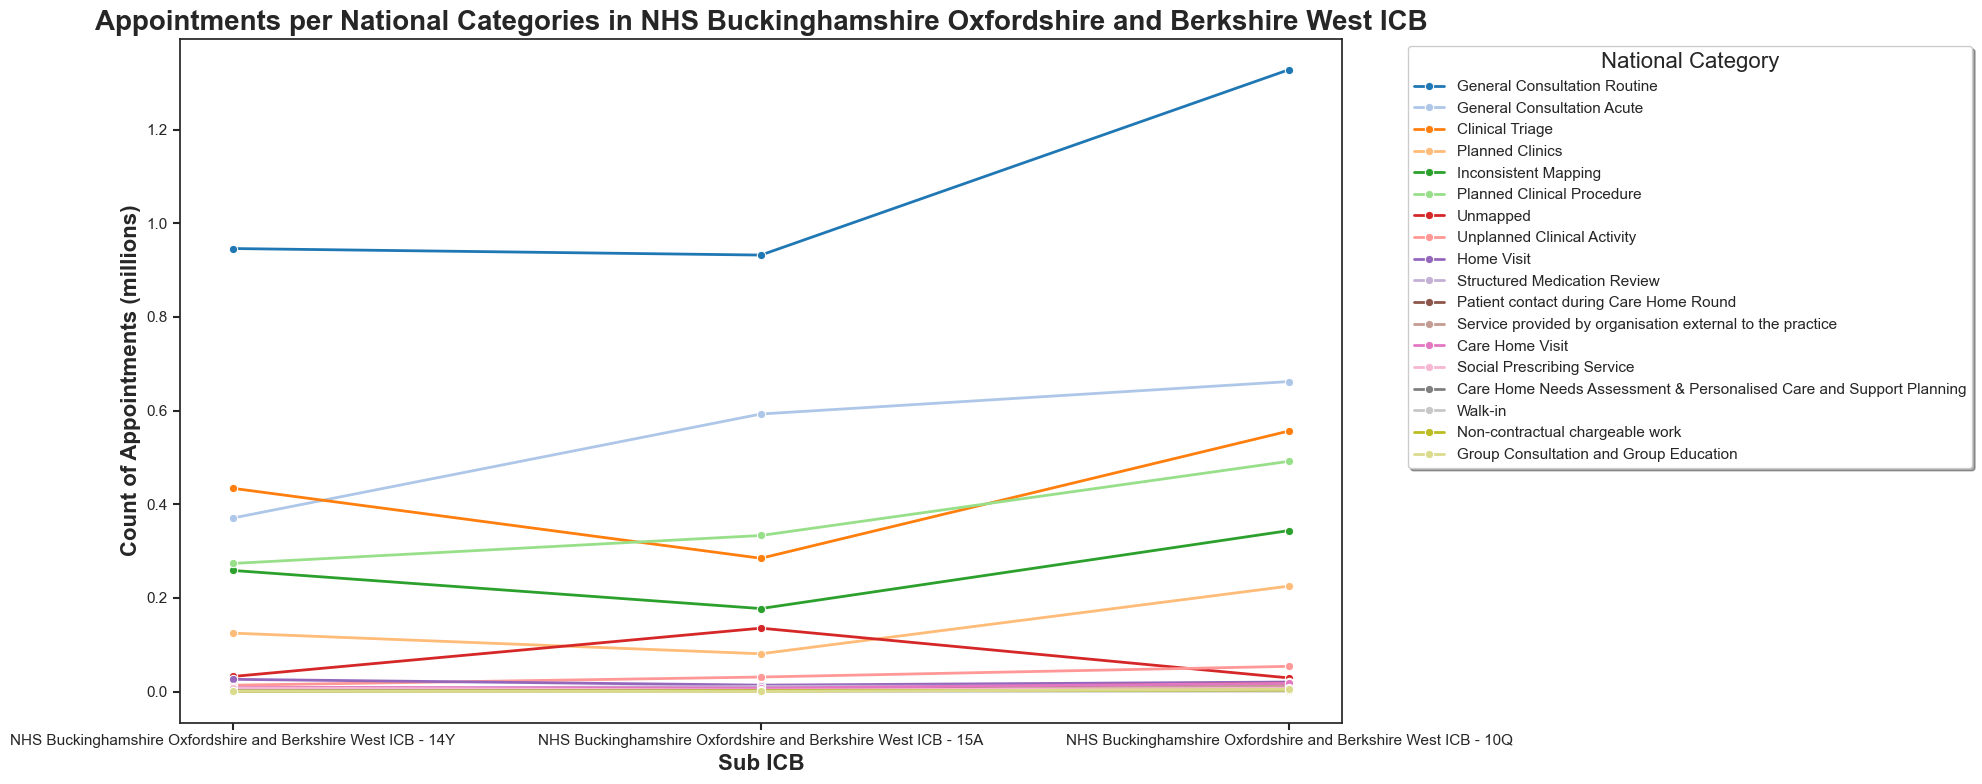

In [178]:
# Plot the appointments over the national categories per sub ICBs
# Adding more color options for better visualisation
import matplotlib.cm as cm
colors = cm.tab20.colors 

# Create a lineplot.
fig, ax = plt.subplots()
fig.set_size_inches(20,8)
# Plot data

sns.lineplot(x='sub_icb_location_name', y='count_millions', hue='national_category',
             hue_order=all_categories, # control legend order
             data=nc_44_subset.sort_values(by='count_millions', ascending=True),
             errorbar=None, 
             linewidth=2, marker='o', ax=ax, palette= colors)

# Adding title and labels

ax.set_title('Appointments per National Categories in NHS Buckinghamshire Oxfordshire and Berkshire West ICB', 
             fontsize= 20, fontweight='bold')
ax.set_xlabel('Sub ICB',fontsize= 16, fontweight='bold')
ax.set_ylabel('Count of Appointments (millions)',fontsize= 16, fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(bbox_to_anchor=(1.05, 1),
          title='National Category', title_fontsize=16,
           frameon=True, shadow=True)

# Plot figure
plt.tight_layout()  
plt.savefig('appointments_by_national_category_inE54000044.png', dpi=300)
plt.show()

In [179]:
patients

,PUBLICATION,EXTRACT_DATE,TYPE,SUB_ICB_LOCATION_CODE,ONS_SUB_ICB_LOCATION_CODE,CODE,POSTCODE,SEX,AGE,NUMBER_OF_PATIENTS
0,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81001,TS18 1HU,ALL,ALL,3889
1,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81002,TS18 2AW,ALL,ALL,18742
2,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81004,TS5 8SB,ALL,ALL,11327
3,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81005,TS14 7DJ,ALL,ALL,7726
4,GP_PRAC_PAT_LIST,2025-01-01,GP,16C,E38000247,A81006,TS18 2AT,ALL,ALL,14738
...,...,...,...,...,...,...,...,...,...,...
6244,GP_PRAC_PAT_LIST,2025-01-01,GP,02Q,E38000008,Y08082,DN22 7XF,ALL,ALL,9
6245,GP_PRAC_PAT_LIST,2025-01-01,GP,03R,E38000190,Y08186,BD1 3LS,ALL,ALL,27
6246,GP_PRAC_PAT_LIST,2025-01-01,GP,A3A8R,E38000255,Y08371,RM13 8QZ,ALL,ALL,2419
6247,GP_PRAC_PAT_LIST,2025-01-01,GP,36L,E38000245,Y08402,CR0 1FE,ALL,ALL,31


In [180]:
# Getting a DataFrame where I can get the total number of patients for the 3 sub ICBs

patients_ad44= patients[patients['ONS_SUB_ICB_LOCATION_CODE'].isin(['E38000136','E38000223','E38000221'])]

patients_ad44

,PUBLICATION,EXTRACT_DATE,TYPE,SUB_ICB_LOCATION_CODE,ONS_SUB_ICB_LOCATION_CODE,CODE,POSTCODE,SEX,AGE,NUMBER_OF_PATIENTS
3564,GP_PRAC_PAT_LIST,2025-01-01,GP,15A,E38000221,J82054,RG17 9UX,ALL,ALL,9502
3740,GP_PRAC_PAT_LIST,2025-01-01,GP,15A,E38000221,K81002,RG14 7LW,ALL,ALL,15574
3741,GP_PRAC_PAT_LIST,2025-01-01,GP,15A,E38000221,K81003,RG7 1QY,ALL,ALL,15912
3742,GP_PRAC_PAT_LIST,2025-01-01,GP,15A,E38000221,K81004,RG30 6BW,ALL,ALL,14600
3744,GP_PRAC_PAT_LIST,2025-01-01,GP,15A,E38000221,K81007,RG1 4SJ,ALL,ALL,5774
...,...,...,...,...,...,...,...,...,...,...
4013,GP_PRAC_PAT_LIST,2025-01-01,GP,10Q,E38000136,K84613,OX26 6XX,ALL,ALL,21776
4014,GP_PRAC_PAT_LIST,2025-01-01,GP,10Q,E38000136,K84618,OX28 3FS,ALL,ALL,8528
4015,GP_PRAC_PAT_LIST,2025-01-01,GP,10Q,E38000136,K84624,OX11 7GD,ALL,ALL,10752
6054,GP_PRAC_PAT_LIST,2025-01-01,GP,14Y,E38000223,Y01964,HP18 1BB,ALL,ALL,28568


In [181]:
patients_number_ad44= patients_ad44.groupby('ONS_SUB_ICB_LOCATION_CODE')['NUMBER_OF_PATIENTS'].sum().reset_index()

patients_number_ad44= patients_number_ad44.rename(columns={'ONS_SUB_ICB_LOCATION_CODE':'sub_icb_location_ons_code'})

patients_number_ad44

,sub_icb_location_ons_code,NUMBER_OF_PATIENTS
0,E38000136,828236
1,E38000221,589533
2,E38000223,595556


In [213]:
ad_44_merge= ad_44.groupby(['sub_icb_location_code', 'sub_icb_location_ons_code','sub_icb_location_name'])['count_of_appointments']\
                            .sum().reset_index()

ad_44_merge

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,count_of_appointments
0,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,2153717
1,14Y,E38000223,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,1429206
2,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,1489285


In [183]:
# Create a DataFrame that includes the number of patients and sub-ICB code for further analysis
ad44_ons_code =pd.merge(ad_44_merge, patients_number_ad44, on='sub_icb_location_ons_code', how='outer')

ad44_ons_code 

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,count_of_appointments,NUMBER_OF_PATIENTS
0,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,2153717,828236
1,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,1489285,589533
2,14Y,E38000223,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,1429206,595556


In [184]:
# Calculate appts per 1000 patients for each sub-ICB
ad44_ons_code['appts_per_1000'] = (
    (ad44_ons_code['count_of_appointments'] / ad44_ons_code['NUMBER_OF_PATIENTS']) * 1000
).round(1)

ad44_ons_code.sort_values(by='NUMBER_OF_PATIENTS', ascending=False)

,sub_icb_location_code,sub_icb_location_ons_code,sub_icb_location_name,count_of_appointments,NUMBER_OF_PATIENTS,appts_per_1000
0,10Q,E38000136,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 10Q,2153717,828236,2600.4
2,14Y,E38000223,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 14Y,1429206,595556,2399.8
1,15A,E38000221,NHS Buckinghamshire Oxfordshire and Berkshire West ICB - 15A,1489285,589533,2526.2


In [185]:
# National average appointments per patient
national_appts = nc['count_of_appointments'].sum()
national_patients = patients['NUMBER_OF_PATIENTS'].sum()
national_rate = round((national_appts / national_patients) * 1000, 1)

In [186]:
# Calculate each sub ICB capacity versus national average
ad44_ons_code['comparison'] = ((ad44_ons_code['appts_per_1000'] - national_rate) / national_rate * 100).round(1)

In [215]:
# NHS Buckinghamshire Oxfordshire and Berkshire West ICB appointments total combined

bob_total_appts = 8924264
bob_total_patients = ad44_ons_code['NUMBER_OF_PATIENTS'].sum()
bob_rate = round((bob_total_appts / bob_total_patients) * 1000, 1)

In [216]:
print(f"Total of appointments in the whole NHS England system recorded from 2021-08 to 2022-06:  {national_appts} appointments")
print(f"Total of patients in the whole NHS England system:  {national_patients} patients")
print(f"National average appointments per patients:  {national_rate} appts per 1,000 patients")

print(f"NHS Buckinghamshire Oxfordshire and Berkshire West ICB average appointments per patients :  {bob_rate} appts per 1,000 patients")
print(f"NHS Buckinghamshire Oxfordshire and Berkshire West ICB vs National average appointments per patients :   {round((bob_rate - national_rate) / national_rate * 100, 1)}%")

Total of appointments in the whole NHS England system recorded from 2021-08 to 2022-06:  296046770 appointments
Total of patients in the whole NHS England system:  63724968 patients
National average appointments per patients:  4645.7 appts per 1,000 patients
NHS Buckinghamshire Oxfordshire and Berkshire West ICB average appointments per patients :  4432.6 appts per 1,000 patients
NHS Buckinghamshire Oxfordshire and Berkshire West ICB vs National average appointments per patients :   -4.6%


###### Key takeaway from above findings:
- BOB ICB records 4.6% fewer appointments per registered patient than the national average. 
- This may come from various reasons, part of it might come from data submission coverage or anything else.

-> Further investigations into national category

In [189]:
# Getting the proportions of each national category type of appointments in NHS Buckinghamshire Oxfordshire and Berkshire West ICB
bob_quality = (nc_44.groupby('national_category')['count_of_appointments']
               .sum() / nc_44['count_of_appointments'].sum() * 100).round(2)
bob_quality

national_category
Care Home Needs Assessment & Personalised Care and Support Planning     0.06
Care Home Visit                                                         0.38
Clinical Triage                                                        14.29
General Consultation Acute                                             18.21
General Consultation Routine                                           35.92
Group Consultation and Group Education                                  0.07
Home Visit                                                              0.67
Inconsistent Mapping                                                    8.74
Non-contractual chargeable work                                         0.06
Patient contact during Care Home Round                                  0.35
Planned Clinical Procedure                                             12.31
Planned Clinics                                                         4.83
Service provided by organisation external to the practice 

In [190]:
# Getting the proportions of each national category type of appointments in national overall levels
national_quality = (nc.groupby('national_category')['count_of_appointments']
                    .sum() / nc['count_of_appointments'].sum() * 100).round(2)

national_quality

national_category
Care Home Needs Assessment & Personalised Care and Support Planning     0.14
Care Home Visit                                                         0.21
Clinical Triage                                                        14.03
General Consultation Acute                                             18.14
General Consultation Routine                                           32.86
Group Consultation and Group Education                                  0.02
Home Visit                                                              0.72
Inconsistent Mapping                                                    9.42
Non-contractual chargeable work                                         0.05
Patient contact during Care Home Round                                  0.27
Planned Clinical Procedure                                              8.68
Planned Clinics                                                         9.46
Service provided by organisation external to the practice 

In [191]:
# Getting the result in a DataFrame
comparison = pd.DataFrame({'NHS Buckinghamshire Oxfordshire and Berkshire West ICB %': bob_quality, 'National_%': national_quality}).\
             fillna(0)

comparison.sort_values(by='NHS Buckinghamshire Oxfordshire and Berkshire West ICB %', ascending=False)

,NHS Buckinghamshire Oxfordshire and Berkshire West ICB %,National_%
national_category,,
General Consultation Routine,35.92,32.86
General Consultation Acute,18.21,18.14
Clinical Triage,14.29,14.03
Planned Clinical Procedure,12.31,8.68
Inconsistent Mapping,8.74,9.42
Planned Clinics,4.83,9.46
Unmapped,2.20,3.74
Unplanned Clinical Activity,1.10,1.03
Home Visit,0.67,0.72


#### Summary of key findings for the NHS Buckinghamshire Oxfordshire and Berkshire West ICB (BOB):

- BOB records far fewer planned clinics than national levels ( 4.83% vs 9.46%) but recorded more planned clinical procedure than national levels( 12.31% vs 8.68%) 
- BoB ICB experienced a drop gap of 3% in appointments more than others while average drop in appointments for other peers were 20% 
- BoB ICB lost about 0.61% of the entire UK's daily appointment capacity over those 5 months, while other similar-sized peers such as E54000051 and E54000052 lost less, which were around 0.54% and 0.53% respectively.
- BOB ICB records 4.6% fewer appointments per registered patient than the national average.

#### Finding areas for recommendations

In [192]:
ar_44

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
17205,E54000044,2021-08,Attended,GP,Face-to-Face,1 Day,5058
17206,E54000044,2021-08,Attended,GP,Face-to-Face,15 to 21 Days,1648
17207,E54000044,2021-08,Attended,GP,Face-to-Face,2 to 7 Days,11229
17208,E54000044,2021-08,Attended,GP,Face-to-Face,22 to 28 Days,723
17209,E54000044,2021-08,Attended,GP,Face-to-Face,8 to 14 Days,3727
...,...,...,...,...,...,...,...
33022,E54000044,2022-06,Unknown,Unknown,Telephone,Same Day,15
33023,E54000044,2022-06,Unknown,Unknown,Unknown,15 to 21 Days,3
33024,E54000044,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,2
33025,E54000044,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,1


In [193]:
# Making sure that the dataframe used is covered from August 2021 to June 2022 for more precise analysis when compared with other datasets              
ar_44_leadtime = ar_44.groupby(['appointment_mode', 'time_between_book_and_appointment'])['count_of_appointments'].sum().reset_index()

ar_44_leadtime

,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,Face-to-Face,1 Day,415464
1,Face-to-Face,15 to 21 Days,399503
2,Face-to-Face,2 to 7 Days,1201685
3,Face-to-Face,22 to 28 Days,234791
4,Face-to-Face,8 to 14 Days,786571
5,Face-to-Face,More than 28 Days,190963
6,Face-to-Face,Same Day,1678235
7,Face-to-Face,Unknown / Data Quality,2452
8,Home Visit,1 Day,10732
9,Home Visit,15 to 21 Days,1266


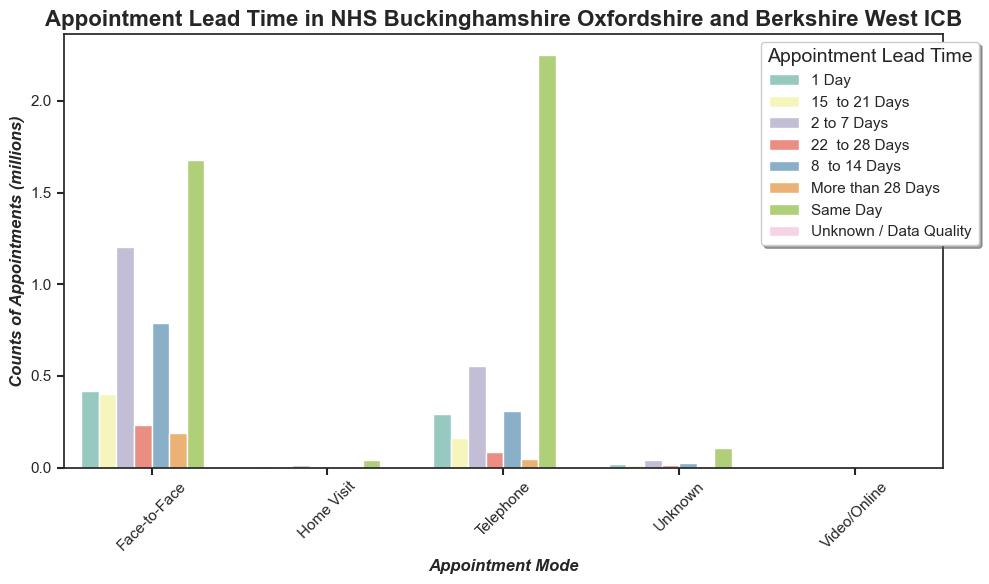

In [194]:
# Create a barchart for easy visualisation of healthcare sentiment distribution
# Adding a column that counts the appointments to millions for better visualisation

ar_44_leadtime['count_millions'] = ar_44_leadtime['count_of_appointments']/ 1_000_000
# Use plt.subplots() instead of plt.figure() for better axis control 
fig, ax = plt.subplots(figsize=(10,6))

# Create the countplot
sns.barplot(x='appointment_mode', 
              data=ar_44_leadtime,
              y='count_millions',
              hue='time_between_book_and_appointment',
              palette='Set3',
              ax=ax)

# Set titles and labels directly on the axis object
ax.set_title('Appointment Lead Time in NHS Buckinghamshire Oxfordshire and Berkshire West ICB' , fontsize=16, fontweight='bold')
ax.set_xlabel('Appointment Mode', fontsize=12, fontstyle='italic', fontweight='bold')
ax.set_ylabel('Counts of Appointments (millions)', fontsize=12, fontstyle='italic', fontweight='bold')

# Adding tick marks

ax.tick_params(axis='x', which='major', bottom=True,
               length=5, width=1.5, rotation=45)

ax.tick_params(axis='y', which='major', left=True,
               length=5, width=1.5)

# Adding legend
plt.legend(title='Appointment Lead Time',
           bbox_to_anchor=(1.05, 1),
           title_fontsize= 14, frameon=True, shadow=True) 

# Plot the figure
plt.tight_layout()
plt.savefig('appointment_leadtime_bob_icb.png', dpi=300)
plt.show()

In [195]:
ar_44_combined = ar_44[ar_44['appointment_month'].isin(['2021-11','2022-04'])]

ar_44_combined

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
17812,E54000044,2021-11,Attended,GP,Face-to-Face,1 Day,6223
17813,E54000044,2021-11,Attended,GP,Face-to-Face,15 to 21 Days,4262
17814,E54000044,2021-11,Attended,GP,Face-to-Face,2 to 7 Days,15766
17815,E54000044,2021-11,Attended,GP,Face-to-Face,22 to 28 Days,1388
17816,E54000044,2021-11,Attended,GP,Face-to-Face,8 to 14 Days,6910
...,...,...,...,...,...,...,...
32541,E54000044,2022-04,Unknown,Unknown,Telephone,1 Day,2
32542,E54000044,2022-04,Unknown,Unknown,Telephone,2 to 7 Days,6
32543,E54000044,2022-04,Unknown,Unknown,Telephone,8 to 14 Days,2
32544,E54000044,2022-04,Unknown,Unknown,Telephone,Same Day,19


In [196]:
ar_44_combined1= ar_44_combined.groupby(['appointment_month','appointment_mode','time_between_book_and_appointment'])\
                                        ['count_of_appointments'].sum().reset_index()

ar_44_combined1

,appointment_month,appointment_mode,time_between_book_and_appointment,count_of_appointments
0,2021-11,Face-to-Face,1 Day,38873
1,2021-11,Face-to-Face,15 to 21 Days,53572
2,2021-11,Face-to-Face,2 to 7 Days,126590
3,2021-11,Face-to-Face,22 to 28 Days,27036
4,2021-11,Face-to-Face,8 to 14 Days,94665
...,...,...,...,...
74,2022-04,Video/Online,2 to 7 Days,31
75,2022-04,Video/Online,22 to 28 Days,4
76,2022-04,Video/Online,8 to 14 Days,16
77,2022-04,Video/Online,More than 28 Days,2


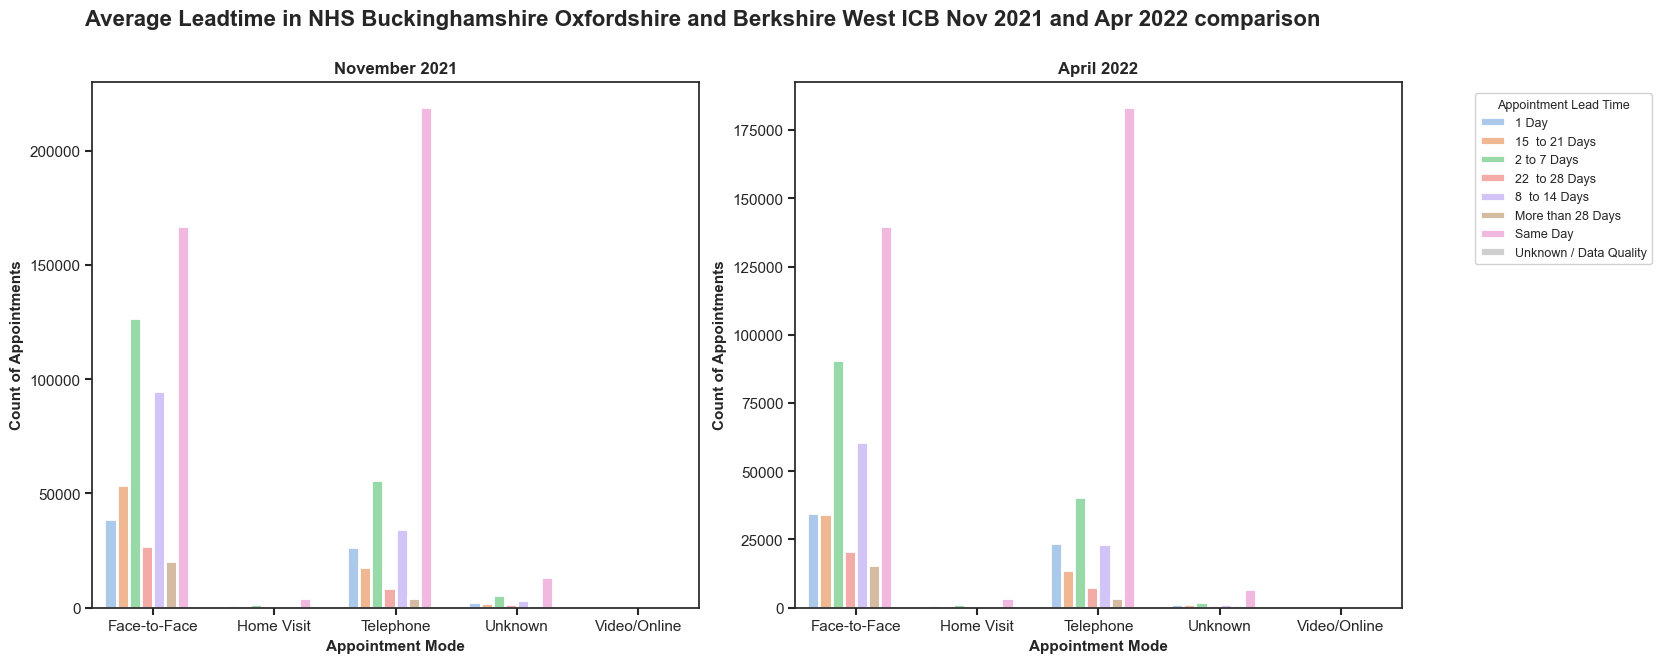

In [206]:
fig, axes = plt.subplots(1, 2, figsize=(14,6), constrained_layout=True)

# ✅ November 2021 — LEFT (axes[0])
sns.barplot(x='appointment_mode', y='count_of_appointments',
            data=ar_44_combined1[ar_44_combined1['appointment_month'].isin(['2021-11'])],
            hue='time_between_book_and_appointment',
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[0])

axes[0].set_title('November 2021', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Appointment Mode', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[0].tick_params(axis='y', which='major', left=True, length=5, width=1.5)
axes[0].legend_.remove() 

# ✅ April 2022 — RIGHT (axes[1])
sns.barplot(x='appointment_mode', y='count_of_appointments',
            data=ar_44_combined1[ar_44_combined1['appointment_month'].isin(['2022-04'])],
            hue='time_between_book_and_appointment',
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[1])

axes[1].set_title('April 2022', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Appointment Mode', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[1].tick_params(axis='y', which='major', left=True, length=5, width=1.5)
axes[1].legend_.remove()  

# Using the same legend
handles, labels = axes[1].get_legend_handles_labels()
fig.legend( handles, labels,
    title='Appointment Lead Time',
    loc='upper right',
    bbox_to_anchor=(1.18, 0.95),
    fontsize=9,
    title_fontsize=9,
    framealpha=0.9,)

# Shared overall title
fig.suptitle('Average Leadtime in NHS Buckinghamshire Oxfordshire and Berkshire West ICB Nov 2021 and Apr 2022 comparison ',
             fontsize=16, fontweight='bold', y=1.08)

plt.savefig('combined_average_leadtime_BOB_ICB_nov2021_apr_2022.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key findings from above chart

- As from previous findings, we could see that NHS Buckinghamshire Oxfordshire and Berkshire West ICB experienced a 23.4% drop in appointments from Nov 2021 to April 2022 - which was around 3.3% higher than average drop compared to other top8 ICBs across the nation.
- BoB ICB lost about 0.61% of the entire UK's daily appointment capacity over those 5 months, while other similar-sized peers such as E54000051 and E54000052 lost less, which were around 0.54% and 0.53% respectively.

-> Above charts have shown where the 3.3% gap appeared:

- Same Day Telephone appointments: drop from 210K to approx 180K
- Same Day Face to Face appointments: drop from 165K to 140K
- 2 to 7 Days Lead Time Appointments: also drop around 30% -> At the moment no information on this have been provided, so we are not certain about this was because the lead time was too long that patients decided to cancel their appointments/or they already recovered so that they would not need the new appointment/ or the decision made by own clinics => This could be where further investigation can be made to better understand patients reasoning behind cancelling their appointments and make the best use out of NHS capacity.

#### Recommendations for NHS Buckinghamshire Oxfordshire and Berkshire West ICB

As the drop from peak November 2021 to April 2022 was the common trends across almost any ICBs, this could be understood as a national effect. As the financial year 2021-2022 ended in March 2022, it might be coming from the funding issue when funding for NHS was cut down in the new FY 2022-2023 (as it's common knowledge that NHS is funded by the government).

-> NHS Buckinghamshire Oxfordshire and Berkshire West ICB should find better ways in understanding their actual needs, avoid hiring too many fixed term contract within short amount of time and start replacing them with longer, more flexible contract in order to be more sustainable.

-> A testing on this recommendation could be stated below

In [198]:
ar_44_hcp=ar_44_combined.groupby(['appointment_status','hcp_type','appointment_month'])['count_of_appointments'].sum().reset_index()

ar_44_hcp

,appointment_status,hcp_type,appointment_month,count_of_appointments
0,Attended,GP,2021-11,466108
1,Attended,GP,2022-04,359091
2,Attended,Other Practice staff,2021-11,367855
3,Attended,Other Practice staff,2022-04,284074
4,Attended,Unknown,2021-11,14299
5,Attended,Unknown,2022-04,15560
6,DNA,GP,2021-11,11959
7,DNA,GP,2022-04,9592
8,DNA,Other Practice staff,2021-11,30872
9,DNA,Other Practice staff,2022-04,19935


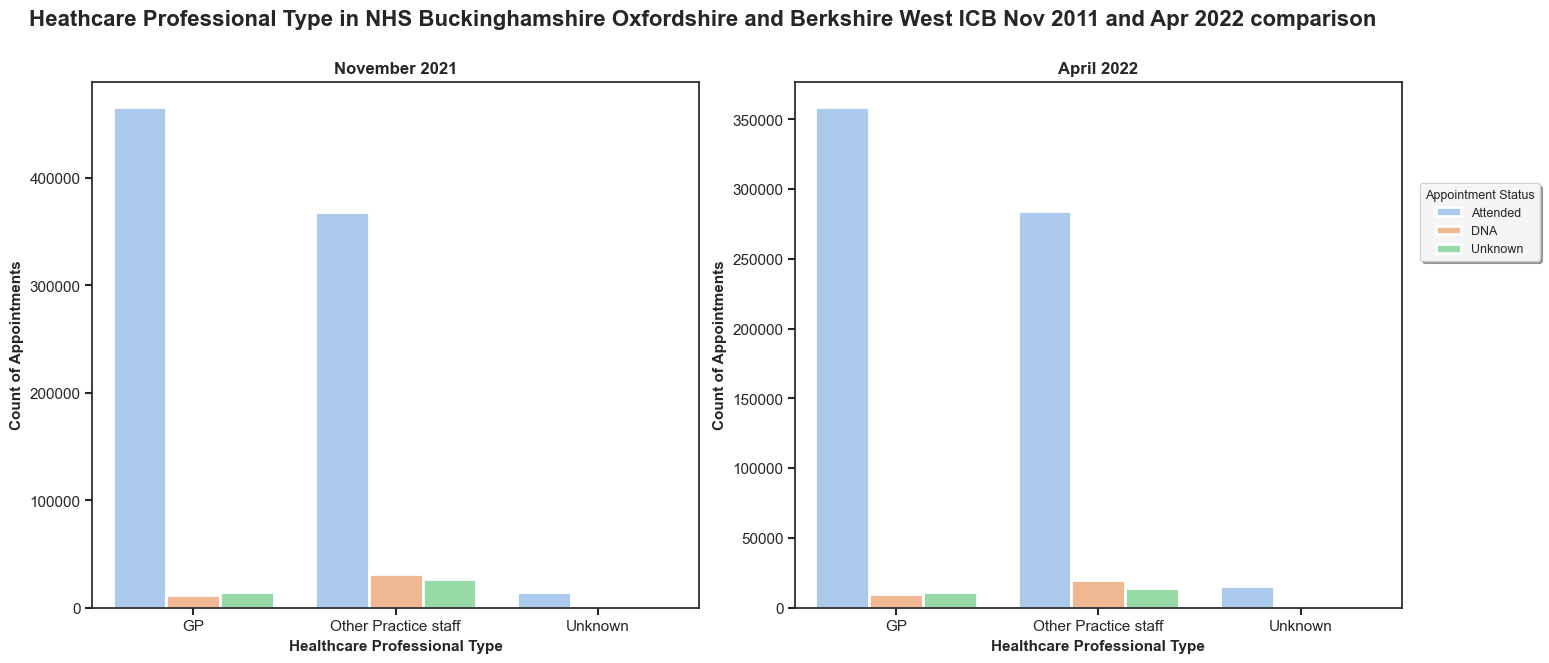

In [199]:
fig, axes = plt.subplots(1, 2, figsize=(14,6), constrained_layout=True)

# ✅ November 2021 — LEFT (axes[0])
sns.barplot(x='hcp_type', y='count_of_appointments',
            data=ar_44_hcp[ar_44_hcp['appointment_month'].isin(['2021-11'])],
            hue='appointment_status',
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[0])

axes[0].set_title('November 2021', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Healthcare Professional Type', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[0].tick_params(axis='y', which='major', left=True, length=5, width=1.5)
axes[0].legend_.remove() 

# ✅ April 2022 — RIGHT (axes[1])
sns.barplot(x='hcp_type', y='count_of_appointments',
            data=ar_44_hcp[ar_44_hcp['appointment_month'].isin(['2022-04'])],
            hue='appointment_status',
            errorbar=None, linewidth=2,
            palette='pastel', ax=axes[1])

axes[1].set_title('April 2022', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Healthcare Professional Type', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Count of Appointments', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', which='major', bottom=True, length=5, width=1.5)
axes[1].tick_params(axis='y', which='major', left=True, length=5, width=1.5)
axes[1].legend_.remove()  

# Using the same legend
handles, labels = axes[1].get_legend_handles_labels()
fig.legend( handles, labels,
    title='Appointment Status',
    loc='upper right',
    bbox_to_anchor=(1.1, 0.8), 
    fontsize=9,shadow=True,
    title_fontsize=9,
    framealpha=0.9,)

# Shared overall title
fig.suptitle('Heathcare Professional Type in NHS Buckinghamshire Oxfordshire and Berkshire West ICB Nov 2011 and Apr 2022 comparison ',
             fontsize=16, fontweight='bold', y=1.08)

plt.savefig('hcp_type_BOB_ICB_nov2021_apr_2022.png', dpi=300, bbox_inches='tight')
plt.show()

In [200]:
ar_44_hcp_test= ar_44_hcp.groupby(['hcp_type','appointment_month'])['count_of_appointments'].sum().reset_index()

ar_44_hcp_test

,hcp_type,appointment_month,count_of_appointments
0,GP,2021-11,492303
1,GP,2022-04,380033
2,Other Practice staff,2021-11,425443
3,Other Practice staff,2022-04,318081
4,Unknown,2021-11,16154
5,Unknown,2022-04,16827


In [201]:
ar_44_hcp_test_pivot=(ar_44_hcp_test.pivot(index='hcp_type', columns='appointment_month', values='count_of_appointments')
              .rename(columns={'2021-11': 'Nov 2021', '2022-04': 'Apr 2022'})
              .reset_index())

ar_44_hcp_test_pivot.columns.name = None

ar_44_hcp_test_pivot

,hcp_type,Nov 2021,Apr 2022
0,GP,492303,380033
1,Other Practice staff,425443,318081
2,Unknown,16154,16827


In [202]:
ar_44_hcp_test_pivot['Appointments Drop'] = ar_44_hcp_test_pivot['Nov 2021'] - ar_44_hcp_test_pivot['Apr 2022']

ar_44_hcp_test_pivot['Appointments Drop Percentage'] = (
    (ar_44_hcp_test_pivot['Nov 2021'] - ar_44_hcp_test_pivot['Apr 2022'])
    / ar_44_hcp_test_pivot['Nov 2021']
    * 100
).round(2)

ar_44_hcp_test_pivot

,hcp_type,Nov 2021,Apr 2022,Appointments Drop,Appointments Drop Percentage
0,GP,492303,380033,112270,22.81
1,Other Practice staff,425443,318081,107362,25.24
2,Unknown,16154,16827,-673,-4.17


In [203]:
share_nov = ar_44_hcp_test_pivot['Nov 2021'] / ar_44_hcp_test_pivot['Nov 2021'].sum() * 100
share_apr = ar_44_hcp_test_pivot['Apr 2022'] / ar_44_hcp_test_pivot['Apr 2022'].sum() * 100
ar_44_hcp_test_pivot['Nov Share (%)'] = share_nov
ar_44_hcp_test_pivot['Apr Share (%)'] = share_apr
ar_44_hcp_test_pivot['Share Shift (Percentage Points)'] = share_apr - share_nov

ar_44_hcp_test_pivot

,hcp_type,Nov 2021,Apr 2022,Appointments Drop,Appointments Drop Percentage,Nov Share (%),Apr Share (%),Share Shift (Percentage Points)
0,GP,492303,380033,112270,22.81,52.714745,53.155855,0.441110
1,Other Practice staff,425443,318081,107362,25.24,45.555520,44.490524,-1.064995
2,Unknown,16154,16827,-673,-4.17,1.729736,2.353621,0.623885


#### Next recommendations:

- The share shift was quite close to 0: the patient behavior did not change. As shown in above Healthcare Professional Type chart, the pattern in all bar stayed the same.
- The 23.4% drop in appointments can be explained by: the drop in healthcare system headcount: the appointments provided by GP and other practice staff all dropped by 22.81% and 25.24% respectively, which could result from the cutting in headcount and reduced service.
- However, we are not so sure about if cutting headcount was the right thing to do, because as seen in the overall national level of Healthcare Professional Type, the overall appointments experienced a noticeable rise in May 2022.

In [204]:
ar_44

,icb_ons_code,appointment_month,appointment_status,hcp_type,appointment_mode,time_between_book_and_appointment,count_of_appointments
17205,E54000044,2021-08,Attended,GP,Face-to-Face,1 Day,5058
17206,E54000044,2021-08,Attended,GP,Face-to-Face,15 to 21 Days,1648
17207,E54000044,2021-08,Attended,GP,Face-to-Face,2 to 7 Days,11229
17208,E54000044,2021-08,Attended,GP,Face-to-Face,22 to 28 Days,723
17209,E54000044,2021-08,Attended,GP,Face-to-Face,8 to 14 Days,3727
...,...,...,...,...,...,...,...
33022,E54000044,2022-06,Unknown,Unknown,Telephone,Same Day,15
33023,E54000044,2022-06,Unknown,Unknown,Unknown,15 to 21 Days,3
33024,E54000044,2022-06,Unknown,Unknown,Unknown,22 to 28 Days,2
33025,E54000044,2022-06,Unknown,Unknown,Unknown,8 to 14 Days,1


In [209]:
# Group by month and lead time to see the distribution of wait times over the full year
ar_44_finaltest= ar_44.groupby(['appointment_month','time_between_book_and_appointment'])['count_of_appointments'].sum().unstack()

# Convert to percentage shares per month to normalize the volume drops
ar_44_shares = ar_44_finaltest.div(ar_44_finaltest.sum(axis=1), axis=0) * 100

print("📊 PERCENTAGE SHARE OF WAITING TIMES")

ar_44_table = ar_44_shares.loc[['2021-08','2021-09','2021-10',
                  '2021-11','2021-12','2022-01','2022-03', '2022-04', '2022-05','2022-06']].round(2)
ar_44_table

📊 PERCENTAGE SHARE OF WAITING TIMES


time_between_book_and_appointment,1 Day,15 to 21 Days,2 to 7 Days,22 to 28 Days,8 to 14 Days,More than 28 Days,Same Day,Unknown / Data Quality
appointment_month,,,,,,,,
2021-08,7.70,6.07,20.35,3.46,11.97,2.64,47.76,0.04
2021-09,8.72,6.44,20.21,4.10,11.58,3.33,45.59,0.04
2021-10,7.95,6.62,22.88,3.24,14.80,3.08,41.38,0.05
2021-11,7.40,7.89,20.34,4.01,14.25,2.80,43.29,0.04
2021-12,8.10,6.91,18.80,3.71,12.64,2.60,47.20,0.05
2022-01,8.68,5.13,21.77,3.40,10.08,2.86,48.02,0.04
2022-03,9.10,6.09,20.34,3.56,12.52,2.21,46.14,0.05
2022-04,8.49,6.93,18.83,4.11,12.00,2.85,46.74,0.05
2022-05,7.90,6.13,19.80,3.86,13.44,2.73,46.09,0.05


#### Final result:
The funding cut was actually fine, and the ICB has enough structural baseline capacity.

If ICB was drastically understaffed or patients were struggling to seek for help, the percentage shares in appointments must fluctuate a lot, however we can see a stable trend in here

-> NHS Buckinghamshire Oxfordshire and Berkshire West ICB got its capacity under control